# Baseline CNN — Meme MRI, standart 5-fold protokolü

**Modeller:** ResNet34, DenseNet121, EfficientNet-B0, MobileNetV2, InceptionV3
**Bu grubun reçetesi:** Yalnızca sınıflandırma başı eğitilir (backbone donuk). Augmentation ve regularization yok. Adam, lr 1e-3.

Bu notebook, dört grup notebook'undan biridir (`1_baseline_cnn`, `2_baseline_vit`, `3_optimized_cnn`, `4_optimized_vit`). Dördünün kodu birebir aynıdır; tek fark ilk hücredeki `GROUP` satırıdır. Bu sayede şunlar bütün gruplarda aynı kalır:
- **Veri bölünmesi:** Her fold'da 16.826 train / 3.594 validation / 3.604 test (`holdout5` modu). Fold ataması `folds_holdout5.csv` dosyasına bir kez yazılır ve bütün notebook'lar aynı dosyayı kullanır.
- **Eğitim koşulları:** 10 epoch, etkin batch 32, 224×224 giriş, en iyi epoch en düşük validation loss'a göre seçilir, seed 42.
- **Çıktılar:** Her model ve her fold için train/validation/test confusion matrix'i, ROC eğrisi ve metrik grafiği, accuracy ve loss eğrileri, metrik tablosu.

**Nasıl çalıştırılır:** Colab'da GPU seçip bütün hücreleri sırayla çalıştır. Oturum kesilirse yeniden çalıştırman yeterli; biten fold'lar atlanır. Süre yetmezse ilk hücrede `MODELS = ["ViT-L-16"]` gibi tek bir model verebilirsin.
Dört notebook bittikten sonra `5_tum_sonuclar.ipynb` ile bütün sonuçları tek bir Excel dosyasında birleştir.


In [1]:
# ======================= 1. AYARLAR =======================
from pathlib import Path

# Bu notebook'un deney grubu. DEĞİŞTİRME: her grubun kendi notebook'u var.
GROUP = "baseline_cnn"

# None = grubun tüm modelleri. Colab süresi yetmezse tek tek ver: ["ViT-L-16"]
MODELS = None

# RERUN = False        → biten fold'lar atlanır, kaldığı yerden devam eder.
# RERUN = "bir-etiket" → bu gruptaki eski sonuçlar BİR KEZ silinir ve yeniden eğitilir
#   (MODELS = None ise tüm modeller, MODELS = ["InceptionV3"] gibi verilirse sadece onlar).
#   Silme yapıldıktan sonra Drive'a rerun_<etiket>.done dosyası yazılır. Colab kesilip notebook aynen
#   yeniden çalıştırılırsa aynı etiketle bir daha silme YAPILMAZ, kaldığı fold'dan devam eder.
#   Yeni bir temiz çalıştırma için yeni bir etiket ver (ör. tarih).
RERUN = False

# Swin-T eğitilir ve kaydedilir; makaleye girip girmeyeceği ayrı karar
INCLUDE_SWIN = True

# ---------------- 5 katlı çapraz doğrulama (TÜM gruplarda aynı fold'lar) ----------------
# Kaggle train (16.826) + validation (3.594) = 20.420 görüntü havuzu oluşturulur, test (3.604) hiç karışmaz.
#   "kfold"    : Stratified 5-fold. Her fold: ~16.336 train / ~4.084 validation. Her görüntü tam 1 kez validation olur.
#   "holdout5" : 5 tekrarlı stratified hold-out. Her fold: TAM 16.826 train / 3.594 validation (Kaggle sayılarıyla birebir),
#                ama validation kümeleri fold'lar arasında örtüşebilir (klasik k-fold değildir; makalede böyle yazılmalı).
CV_MODE = "holdout5"   # hocanın istediği: her fold Kaggle sayılarıyla birebir aynı
N_FOLDS = 5
FOLD_SEED = 42        # fold ataması bir kez üretilir, folds.csv'ye yazılır; tüm gruplar ve modeller aynı dosyayı kullanır
TRAIN_SEED = 42       # her fold'da model eğitimi için aynı seed

# Veri kaynağı: "kaggle" (önerilen; train/validation/test klasörleriyle iner) veya "rar"
DATA_SOURCE = "kaggle"
KAGGLE_ID = "abenjelloun/breast-mri-tumor-classification-dataset"
RAR_SOURCE = "/content/drive/MyDrive/data_set_zip/breast_mri_dataset.rar"   # rar'da validation klasörü de olmalı

EXPECTED_COUNTS = {"train": 16826, "val": 3594, "test": 3604}
STRICT_COUNTS = True                  # sayılar tutmazsa dur

# Sonuçlar Drive'a yazılır (Colab kapanınca kaybolmasın, kaldığı yerden devam edebilsin)
OUTPUT_ROOT = Path("/content/drive/MyDrive/breast_mri_standard_results")

SHOW_PLOTS = True                     # grafikleri hücre altında da göster

# ---------------- Tüm gruplarda ORTAK protokol ----------------
COMMON = dict(
    img_size=224,
    epochs=10,                 # her run sabit 10 epoch, early stopping yok
    batch_size=32,             # fiziksel batch
    accum_steps=1,             # bellek yetmezse batch_size=16, accum_steps=2 (etkin batch yine 32)
    num_workers=2,
    amp=True,                  # mixed precision (hız için, tüm gruplarda açık)
    select_by="val_loss",      # en iyi epoch: en düşük validation loss (tüm gruplarda aynı)
    mean=[0.485, 0.456, 0.406],
    std=[0.229, 0.224, 0.225],
)

# ---------------- Grup reçeteleri ----------------
# Baseline: yalnızca sınıflandırma başı eğitilir, augmentation/regularization yok.
# Optimize: CNN ve ViT için AYNI reçete ve AYNI ince ayar kapsamı (tüm katmanlar).
RECIPES = {
    "baseline": dict(optimizer="adam", lr=1e-3, weight_decay=0.0, scheduler=None,
                     augment=False, label_smoothing=0.0, head_dropout=0.0, grad_clip=None),
    "optimized": dict(optimizer="adamw", lr=1e-4, weight_decay=1e-4, scheduler="cosine", eta_min=1e-6,
                      augment=True, label_smoothing=0.1, head_dropout=0.3, grad_clip=1.0),
}
FT_SCOPE = {
    ("baseline", "cnn"): "head",
    ("baseline", "vit"): "head",
    ("optimized", "cnn"): "full",      # tüm katmanlar
    ("optimized", "vit"): "full",      # tüm katmanlar (CNN ile birebir aynı)
}
VIT_LAST_BLOCKS = 4

AUGMENT = dict(rotation=15, hflip_p=0.5, vflip_p=0.5, translate=0.05, scale=(0.95, 1.05),
               brightness=0.15, contrast=0.15, erasing_p=0.15)

CNN_MODELS = ["ResNet34", "DenseNet121", "EfficientNet-B0", "MobileNetV2", "InceptionV3"]
VIT_MODELS = ["ViT-B-16", "ViT-B-32", "ViT-L-16", "ViT-L-32"] + (["Swin-T"] if INCLUDE_SWIN else [])


In [2]:
# ======================= 2. KURULUM + VERİ + SIZINTI KONTROLÜ =======================
import os, gc, json, time, random, shutil, subprocess, hashlib, platform
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from torchvision import datasets, models, transforms
from sklearn.metrics import confusion_matrix, roc_auc_score, roc_curve
from IPython.display import display

from google.colab import drive
drive.mount("/content/drive")
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device, "|", torch.cuda.get_device_name(0) if device.type == "cuda" else "")

# ---------- Veriyi getir ----------
if DATA_SOURCE == "kaggle":
    import kagglehub   # gerekirse: kagglehub.login()
    RAW_ROOT = Path(kagglehub.dataset_download(KAGGLE_ID))
else:
    shutil.copy2(RAR_SOURCE, "/content/dataset.rar")
    subprocess.run(["unrar", "x", "-o+", "/content/dataset.rar", "/content/dataset_raw/"], check=True)
    RAW_ROOT = Path("/content/dataset_raw")

SPLIT_ALIASES = {"train": {"train", "training"},
                 "val": {"val", "valid", "validation"},
                 "test": {"test", "testing"}}

def find_split_dirs(root):
    """train/val/test klasörlerini (içinde Benign/Malignant olan) otomatik bulur."""
    for d in sorted([root] + [p for p in root.rglob("*") if p.is_dir()]):
        children = {c.name.lower(): c for c in d.iterdir() if c.is_dir()}
        found = {}
        for split, aliases in SPLIT_ALIASES.items():
            for a in aliases:
                if a in children:
                    cls = {c.name.lower() for c in children[a].iterdir() if c.is_dir()}
                    if {"benign", "malignant"} <= cls:
                        found[split] = children[a]
        if len(found) == 3:
            return found
    raise RuntimeError(f"{root} altında train/validation/test (Benign/Malignant) yapısı bulunamadı.")

SPLIT_DIRS = find_split_dirs(RAW_ROOT)
print({k: str(v) for k, v in SPLIT_DIRS.items()})

def make_tf(augment):
    c, a = COMMON, AUGMENT
    if not augment:
        return transforms.Compose([transforms.Resize((c["img_size"], c["img_size"])),
                                   transforms.ToTensor(), transforms.Normalize(c["mean"], c["std"])])
    return transforms.Compose([
        transforms.Resize((c["img_size"], c["img_size"])),
        transforms.RandomRotation(a["rotation"]),
        transforms.RandomHorizontalFlip(a["hflip_p"]),
        transforms.RandomVerticalFlip(a["vflip_p"]),
        transforms.RandomAffine(0, translate=(a["translate"], a["translate"]), scale=a["scale"]),
        transforms.ColorJitter(brightness=a["brightness"], contrast=a["contrast"]),
        transforms.ToTensor(), transforms.Normalize(c["mean"], c["std"]),
        transforms.RandomErasing(p=a["erasing_p"], scale=(0.02, 0.08), ratio=(0.3, 3.3)),
    ])

EVAL_TF = make_tf(False)
DS = {s: datasets.ImageFolder(SPLIT_DIRS[s], transform=EVAL_TF) for s in ["train", "val", "test"]}

# ---------- Kontroller ----------
for s, d in DS.items():
    assert [c.lower() for c in d.classes] == ["benign", "malignant"], d.classes
CLASS_NAMES = DS["train"].classes            # Malignant = 1 = pozitif sınıf
counts = pd.DataFrame({s: pd.Series(d.targets).value_counts().sort_index().values for s, d in DS.items()},
                      index=CLASS_NAMES)
counts.loc["Toplam"] = counts.sum()
display(counts)
mismatch = {s: (len(DS[s]), n) for s, n in EXPECTED_COUNTS.items() if len(DS[s]) != n}
if mismatch:
    msg = f"Görüntü sayıları beklenenle tutmuyor (gerçek, beklenen): {mismatch}"
    if STRICT_COUNTS: raise ValueError(msg)
    print("UYARI:", msg)
counts.to_csv(OUTPUT_ROOT / "split_counts.csv")

# ---------- Train+Val havuzu ve 5 fold (bir kez üretilir, sonra hep aynısı kullanılır) ----------
from sklearn.model_selection import StratifiedKFold, StratifiedShuffleSplit

class ListDataset(torch.utils.data.Dataset):
    def __init__(self, samples, transform):
        self.samples, self.transform = samples, transform
        self.targets = [y for _, y in samples]
    def __len__(self): return len(self.samples)
    def __getitem__(self, i):
        path, y = self.samples[i]
        return self.transform(datasets.folder.default_loader(path)), y

POOL = DS["train"].samples + DS["val"].samples          # 20.420 görüntü
POOL_SRC = ["train"] * len(DS["train"]) + ["val"] * len(DS["val"])
pool_y = np.array([y for _, y in POOL])
rel = [str(Path(p).relative_to(RAW_ROOT)) for p, _ in POOL]

FOLDS_FILE = OUTPUT_ROOT / f"folds_{CV_MODE}.csv"
if FOLDS_FILE.exists():
    fdf = pd.read_csv(FOLDS_FILE)
    assert fdf["file"].tolist() == rel, "folds dosyasındaki görüntü listesi mevcut veriyle aynı değil!"
    print("Mevcut fold ataması yüklendi:", FOLDS_FILE.name)
else:
    if CV_MODE == "kfold":
        splitter = StratifiedKFold(N_FOLDS, shuffle=True, random_state=FOLD_SEED)
    elif CV_MODE == "holdout5":
        splitter = StratifiedShuffleSplit(N_FOLDS, test_size=EXPECTED_COUNTS["val"], random_state=FOLD_SEED)
    else:
        raise ValueError(CV_MODE)
    fdf = pd.DataFrame({"file": rel, "label": pool_y, "kaggle_split": POOL_SRC})
    for k, (_, va) in enumerate(splitter.split(np.zeros(len(pool_y)), pool_y), 1):
        col = np.array(["train"] * len(pool_y), dtype=object); col[va] = "val"; fdf[f"fold{k}"] = col
    fdf.to_csv(FOLDS_FILE, index=False)
    print("Yeni fold ataması üretildi ve kaydedildi:", FOLDS_FILE)

FOLD_IDX = {k: (np.where(fdf[f"fold{k}"] == "train")[0], np.where(fdf[f"fold{k}"] == "val")[0])
            for k in range(1, N_FOLDS + 1)}
fold_table = pd.DataFrame([{"Fold": k, "Train": len(tr), "Train Benign": int((pool_y[tr] == 0).sum()),
                            "Train Malignant": int((pool_y[tr] == 1).sum()), "Validation": len(va),
                            "Val Benign": int((pool_y[va] == 0).sum()), "Val Malignant": int((pool_y[va] == 1).sum()),
                            "Test": len(DS["test"])} for k, (tr, va) in FOLD_IDX.items()])
fold_table.to_csv(OUTPUT_ROOT / f"fold_counts_{CV_MODE}.csv", index=False)
display(fold_table)   # makaledeki veri seti tablosu bu tablodan alınmalı

# ---------- Sızıntı kontrolü: split'ler arası aynı / çok benzer görüntü ----------
def leakage_check(max_hamming=2):
    """(1) train+val havuzu ile test arasında, (2) havuzun kendi içinde (fold'lar arası sızıntı)
    birebir aynı (md5) ve çok benzer (pHash) görüntüleri sayar."""
    try:
        import imagehash
    except ImportError:
        subprocess.run(["pip", "install", "-q", "imagehash"], check=True); import imagehash
    from PIL import Image
    groups = {"trainval": [p for p, _ in POOL], "test": [p for p, _ in DS["test"].samples]}
    md5 = {g: [hashlib.md5(open(p, "rb").read()).hexdigest() for p in ps] for g, ps in groups.items()}
    ph = {g: np.array([int(str(imagehash.phash(Image.open(p).convert("L"))), 16) for p in ps], dtype=np.uint64)
          for g, ps in groups.items()}
    POP = np.array([bin(i).count("1") for i in range(256)], dtype=np.uint8)
    def near_count(A, B, same=False):
        Ab = A.view(np.uint8).reshape(-1, 8); hits = 0
        for i, h in enumerate(B):
            d = POP[Ab ^ np.array([h], dtype=np.uint64).view(np.uint8)].sum(1)
            if same: d[i] = 255
            hits += int((d <= max_hamming).any())
        return hits
    tv, te = set(md5["trainval"]), md5["test"]
    rows = [
        {"Karşılaştırma": "test ↔ train+val", "Tür": "birebir aynı (md5)", "Etkilenen test görüntüsü": sum(h in tv for h in te)},
        {"Karşılaştırma": "test ↔ train+val", "Tür": f"çok benzer (pHash ≤ {max_hamming})", "Etkilenen test görüntüsü": near_count(ph["trainval"], ph["test"])},
        {"Karşılaştırma": "train+val kendi içinde", "Tür": "birebir aynı (md5)",
         "Etkilenen test görüntüsü": int(pd.Series(md5["trainval"]).duplicated(keep=False).sum())},
        {"Karşılaştırma": "train+val kendi içinde", "Tür": f"çok benzer (pHash ≤ {max_hamming})",
         "Etkilenen test görüntüsü": near_count(ph["trainval"], ph["trainval"], same=True)},
    ]
    df = pd.DataFrame(rows).rename(columns={"Etkilenen test görüntüsü": "Eşleşmesi olan görüntü sayısı"})
    df.to_csv(OUTPUT_ROOT / "leakage_check.csv", index=False)
    return df

if not (OUTPUT_ROOT / "leakage_check.csv").exists():
    print("Sızıntı kontrolü yapılıyor (bir kez, birkaç dakika sürer)...")
    display(leakage_check())
else:
    display(pd.read_csv(OUTPUT_ROOT / "leakage_check.csv"))


Mounted at /content/drive
Device: cuda | NVIDIA A100-SXM4-40GB
Using Colab cache for faster access to the 'breast-mri-tumor-classification-dataset' dataset.
{'train': '/kaggle/input/breast-mri-tumor-classification-dataset/breast_mri_dataset/train', 'val': '/kaggle/input/breast-mri-tumor-classification-dataset/breast_mri_dataset/val', 'test': '/kaggle/input/breast-mri-tumor-classification-dataset/breast_mri_dataset/test'}


,train,val,test
Benign,8413,1797,1802
Malignant,8413,1797,1802
Toplam,16826,3594,3604


Mevcut fold ataması yüklendi: folds_holdout5.csv


,Fold,Train,Train Benign,Train Malignant,Validation,Val Benign,Val Malignant,Test
0,1,16826,8413,8413,3594,1797,1797,3604
1,2,16826,8413,8413,3594,1797,1797,3604
2,3,16826,8413,8413,3594,1797,1797,3604
3,4,16826,8413,8413,3594,1797,1797,3604
4,5,16826,8413,8413,3594,1797,1797,3604


,Karşılaştırma,Tür,Eşleşmesi olan görüntü sayısı
0,test ↔ train+val,birebir aynı (md5),0
1,test ↔ train+val,çok benzer (pHash ≤ 2),2820
2,train+val kendi içinde,birebir aynı (md5),0
3,train+val kendi içinde,çok benzer (pHash ≤ 2),15827


In [3]:
# ======================= 3. MODEL, EĞİTİM, DEĞERLENDİRME =======================
def seed_all(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True; torch.backends.cudnn.benchmark = False

def worker_init(worker_id):
    s = torch.initial_seed() % 2**32
    np.random.seed(s); random.seed(s)

FAMILY = {**{m: "cnn" for m in CNN_MODELS}, **{m: "vit" for m in ["ViT-B-16", "ViT-B-32", "ViT-L-16", "ViT-L-32", "Swin-T"]}}
HEAD_MODULE = {"ResNet34": "fc", "InceptionV3": "fc", "DenseNet121": "classifier", "EfficientNet-B0": "classifier",
               "MobileNetV2": "classifier", "ViT-B-16": "heads", "ViT-B-32": "heads", "ViT-L-16": "heads",
               "ViT-L-32": "heads", "Swin-T": "head"}

def new_head(in_features, p):
    return nn.Sequential(nn.Dropout(p), nn.Linear(in_features, 2))

def build_model(name, head_dropout):
    W = "IMAGENET1K_V1"
    if name == "ResNet34":
        m = models.resnet34(weights=W); m.fc = new_head(m.fc.in_features, head_dropout)
    elif name == "DenseNet121":
        m = models.densenet121(weights=W); m.classifier = new_head(m.classifier.in_features, head_dropout)
    elif name == "EfficientNet-B0":
        m = models.efficientnet_b0(weights=W); m.classifier = new_head(m.classifier[1].in_features, head_dropout)
    elif name == "MobileNetV2":
        m = models.mobilenet_v2(weights=W); m.classifier = new_head(m.classifier[1].in_features, head_dropout)
    elif name == "InceptionV3":
        m = models.inception_v3(weights=W); m.aux_logits = False; m.AuxLogits = None
        m.dropout = nn.Identity()   # InceptionV3'ün kendi Dropout(0.5)'i kaldırılır; head dropout diğer modellerle aynı (RECIPES)
        m.fc = new_head(m.fc.in_features, head_dropout)
    elif name.startswith("ViT"):
        m = getattr(models, name.lower().replace("-", "_"))(weights=W)
        m.heads.head = new_head(m.heads.head.in_features, head_dropout)
    elif name == "Swin-T":
        m = models.swin_t(weights=W); m.head = new_head(m.head.in_features, head_dropout)
    else:
        raise ValueError(name)
    return m

def configure_trainable(m, name, scope):
    """scope: head | partial | full"""
    for p in m.parameters():
        p.requires_grad = (scope == "full")
    if scope == "full":
        return
    prefixes = [HEAD_MODULE[name] + "."]
    if scope == "partial":
        if name.startswith("ViT"):
            n = len(m.encoder.layers)
            prefixes += [f"encoder.layers.encoder_layer_{i}." for i in range(n - VIT_LAST_BLOCKS, n)] + ["encoder.ln."]
        elif name == "Swin-T":
            prefixes += ["features.7.", "norm."]
        else:
            raise ValueError("partial yalnızca ViT/Swin için tanımlı")
    for pn, p in m.named_parameters():
        if pn.startswith(tuple(prefixes)):
            p.requires_grad = True

def set_train_mode(m):
    """Eğitilebilir parametresi olmayan (dondurulmuş) modüller eval modunda kalır:
    BatchNorm istatistikleri güncellenmez, donmuş bloklarda dropout/stochastic depth çalışmaz."""
    m.train()
    for mod in m.modules():
        ps = list(mod.parameters(recurse=True))
        if ps and not any(p.requires_grad for p in ps):
            mod.eval()

def autocast():
    return torch.autocast(device_type=device.type, dtype=torch.float16,
                          enabled=COMMON["amp"] and device.type == "cuda")

EVAL_LOSS = nn.CrossEntropyLoss()   # değerlendirme kaybı tüm gruplarda düz CE (label smoothing yok) -> karşılaştırılabilir

def train_one_epoch(m, loader, opt, loss_fn, scaler, grad_clip):
    set_train_mode(m); opt.zero_grad(set_to_none=True)
    params = [p for p in m.parameters() if p.requires_grad]
    acc_steps = COMMON["accum_steps"]; tot_loss = correct = n = 0
    for step, (x, y) in enumerate(loader, 1):
        x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
        with autocast():
            out = m(x); loss = loss_fn(out, y)
        scaler.scale(loss / acc_steps).backward()
        if step % acc_steps == 0 or step == len(loader):
            if grad_clip:
                scaler.unscale_(opt); nn.utils.clip_grad_norm_(params, grad_clip)
            scaler.step(opt); scaler.update(); opt.zero_grad(set_to_none=True)
        tot_loss += EVAL_LOSS(out.float(), y).item() * y.size(0)
        correct += (out.argmax(1) == y).sum().item(); n += y.size(0)
    return tot_loss / n, correct / n

@torch.inference_mode()
def predict(m, loader):
    m.eval(); ys, probs, losses = [], [], []
    for x, y in loader:
        x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
        with autocast():
            out = m(x)
        out = out.float()
        losses.append(EVAL_LOSS(out, y).item() * y.size(0))
        ys.append(y.cpu().numpy()); probs.append(out.softmax(1)[:, 1].cpu().numpy())
    y = np.concatenate(ys); prob = np.concatenate(probs)
    return y, prob, sum(losses) / len(y)

def metrics(y, prob, loss=None):
    pred = (prob >= 0.5).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    sd = lambda a, b: a / b if b else 0.0
    prec, rec = sd(tp, tp + fp), sd(tp, tp + fn)
    return {"N": int(len(y)), "TN": int(tn), "FP": int(fp), "FN": int(fn), "TP": int(tp),
            "Accuracy": sd(tp + tn, len(y)), "Precision": prec, "Recall (Sensitivity)": rec,
            "Specificity": sd(tn, tn + fp), "F1-Score": sd(2 * prec * rec, prec + rec),
            "ROC-AUC": roc_auc_score(y, prob), "Loss": loss}

def save_fig(path):
    plt.tight_layout(); plt.savefig(path, dpi=300)
    plt.show() if SHOW_PLOTS else None
    plt.close()

def plot_curves(hist, title, out_dir):
    ep = hist["Epoch"]
    for key in ["Accuracy", "Loss"]:
        plt.figure(figsize=(7, 4.5))
        plt.plot(ep, hist[f"Train {key}"], "o-", label="Train")
        plt.plot(ep, hist[f"Validation {key}"], "s-", label="Validation")
        plt.xlabel("Epoch"); plt.ylabel(key); plt.title(f"{title} – {key}"); plt.grid(alpha=.3); plt.legend()
        save_fig(out_dir / f"{key.lower()}_curve.png")

def plot_split(y, prob, mtr, title, split, out_dir):
    cm = np.array([[mtr["TN"], mtr["FP"]], [mtr["FN"], mtr["TP"]]])
    plt.figure(figsize=(5.5, 4.5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
    plt.xlabel("Tahmin"); plt.ylabel("Gerçek"); plt.title(f"{title} – {split} (N={mtr['N']})")
    save_fig(out_dir / f"cm_{split.lower()}.png")
    fpr, tpr, _ = roc_curve(y, prob)
    plt.figure(figsize=(5.5, 4.5)); plt.plot(fpr, tpr, label=f"AUC = {mtr['ROC-AUC']:.4f}"); plt.plot([0, 1], [0, 1], "--")
    plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate"); plt.title(f"{title} – {split} ROC")
    plt.legend(); plt.grid(alpha=.3); save_fig(out_dir / f"roc_{split.lower()}.png")

def plot_metric_bars(mtr, title, split, out_dir):
    keys = ["Accuracy", "Precision", "Recall (Sensitivity)", "Specificity", "F1-Score", "ROC-AUC"]
    vals = [mtr[k] for k in keys]
    plt.figure(figsize=(8, 4.5)); bars = plt.bar(["Accuracy", "Precision", "Recall", "Specificity", "F1", "AUC"], vals)
    for b, v in zip(bars, vals):
        plt.text(b.get_x() + b.get_width() / 2, v + 0.005, f"{v:.4f}", ha="center", va="bottom", fontsize=9)
    plt.ylim(0, 1.05); plt.ylabel("Değer"); plt.title(f"{title} – {split} Metrics"); plt.grid(axis="y", alpha=.3)
    save_fig(out_dir / f"metrics_{split.lower()}.png")

def show_saved_fold(out_dir, name, fold, res):
    """Atlanan (daha önce tamamlanmış) bir fold'un Drive'daki çıktılarını, eğitim sırasındaki sırayla gösterir."""
    from IPython.display import Image as _Img
    hist_file = out_dir / "history.csv"
    if hist_file.exists():
        for _, r in pd.read_csv(hist_file).iterrows():
            print(f"{name} | Fold {fold} | Epoch {int(r['Epoch']):02d}/{COMMON['epochs']} | "
                  f"Train loss {r['Train Loss']:.4f} acc {r['Train Accuracy']:.4f} | "
                  f"Val loss {r['Validation Loss']:.4f} acc {r['Validation Accuracy']:.4f}")
    if SHOW_PLOTS:
        pngs = ["accuracy_curve.png", "loss_curve.png"] + [f"{k}_{s}.png" for s in ["train", "validation", "test"]
                                                           for k in ["cm", "roc", "metrics"]]
        for p in pngs:
            if (out_dir / p).exists():
                display(_Img(filename=str(out_dir / p), width=560))
    print(f"{name} – Fold {fold} sonuçları (best epoch = {res['Best Epoch']}):")
    display(pd.DataFrame(res["Splits"]).T)
    print(f"✓ {name} Fold {fold}: best epoch {res['Best Epoch']} | Test acc {res['Splits']['Test']['Accuracy']:.4f}")

def run_one(name, fold, kind):
    seed = TRAIN_SEED
    family = FAMILY[name]; R = RECIPES[kind]; scope = FT_SCOPE[(kind, family)]
    out_dir = OUTPUT_ROOT / CV_MODE / GROUP / name / f"Fold_{fold}"
    done = out_dir / "result.json"
    if done.exists():
        res = json.loads(done.read_text())
        print(f"[atlandı] {name} Fold {fold} zaten tamam — kaydedilmiş çıktılar Drive'dan gösteriliyor")
        show_saved_fold(out_dir, name, fold, res)
        return res
    out_dir.mkdir(parents=True, exist_ok=True); seed_all(seed)

    g = torch.Generator(); g.manual_seed(seed)
    pin = device.type == "cuda"; nw = COMMON["num_workers"]; bs = COMMON["batch_size"]
    tr_idx, va_idx = FOLD_IDX[fold]
    sub = lambda idx, tf: ListDataset([POOL[i] for i in idx], tf)
    tr_loader = DataLoader(sub(tr_idx, make_tf(R["augment"])), bs, shuffle=True, generator=g,
                           worker_init_fn=worker_init, num_workers=nw, pin_memory=pin)
    eval_loaders = {"Train": DataLoader(sub(tr_idx, EVAL_TF), bs, shuffle=False, num_workers=nw, pin_memory=pin),
                    "Validation": DataLoader(sub(va_idx, EVAL_TF), bs, shuffle=False, num_workers=nw, pin_memory=pin),
                    "Test": DataLoader(DS["test"], bs, shuffle=False, num_workers=nw, pin_memory=pin)}

    m = build_model(name, R["head_dropout"]); configure_trainable(m, name, scope); m.to(device)
    params = [p for p in m.parameters() if p.requires_grad]
    n_tr, n_all = sum(p.numel() for p in params), sum(p.numel() for p in m.parameters())
    opt = (torch.optim.AdamW if R["optimizer"] == "adamw" else torch.optim.Adam)(params, lr=R["lr"], weight_decay=R["weight_decay"])
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=COMMON["epochs"], eta_min=R["eta_min"]) if R["scheduler"] == "cosine" else None
    loss_fn = nn.CrossEntropyLoss(label_smoothing=R["label_smoothing"])
    scaler = torch.amp.GradScaler("cuda", enabled=COMMON["amp"] and device.type == "cuda")

    hist = {k: [] for k in ["Epoch", "LR", "Train Loss", "Train Accuracy", "Validation Loss", "Validation Accuracy"]}
    best = (float("inf"), -1.0, None, 0); t0 = time.time()
    for ep in range(1, COMMON["epochs"] + 1):
        lr_now = opt.param_groups[0]["lr"]
        tl, ta = train_one_epoch(m, tr_loader, opt, loss_fn, scaler, R["grad_clip"])
        yv, pv, vl = predict(m, eval_loaders["Validation"]); va = ((pv >= .5).astype(int) == yv).mean()
        if sched: sched.step()
        for k, v in zip(hist, [ep, lr_now, tl, ta, vl, va]): hist[k].append(v)
        key = (vl, -va) if COMMON["select_by"] == "val_loss" else (-va, vl)
        if key < (best[0], best[1]):
            best = (key[0], key[1], {k: v.detach().cpu().clone() for k, v in m.state_dict().items()}, ep)
        print(f"{name} | Fold {fold} | Epoch {ep:02d}/{COMMON['epochs']} | "
              f"Train loss {tl:.4f} acc {ta:.4f} | Val loss {vl:.4f} acc {va:.4f}")
    train_time = time.time() - t0
    m.load_state_dict(best[2]); best_epoch = best[3]
    pd.DataFrame(hist).to_csv(out_dir / "history.csv", index=False)
    title = f"{name} – Fold {fold}"
    plot_curves(hist, title, out_dir)

    res = {"CV": CV_MODE, "Group": GROUP, "Model": name, "Fold": fold, "Seed": seed, "Best Epoch": best_epoch,
           "Trainable Params": n_tr, "Total Params": n_all, "Train Time (s)": round(train_time, 1), "Splits": {}}
    for split, loader in eval_loaders.items():
        y, prob, loss = predict(m, loader); mtr = metrics(y, prob, loss)
        res["Splits"][split] = mtr
        plot_split(y, prob, mtr, title, split, out_dir)
        plot_metric_bars(mtr, title, split, out_dir)
        if split == "Test":   # örnek bazlı tahminler (McNemar vb. istatistiksel test için)
            pd.DataFrame({"file": [p for p, _ in DS["test"].samples], "y": y, "prob_malignant": prob,
                          "pred": (prob >= .5).astype(int)}).to_csv(out_dir / "test_predictions.csv", index=False)
    fold_df = pd.DataFrame(res["Splits"]).T
    fold_df.to_csv(out_dir / "metrics.csv")
    print(f"{name} – Fold {fold} sonuçları (best epoch = {best_epoch}):")
    display(fold_df)
    done.write_text(json.dumps(res, indent=2))
    print(f"✓ {name} Fold {fold}: best epoch {best_epoch} | Test acc {res['Splits']['Test']['Accuracy']:.4f}")
    del m, opt, best; gc.collect(); torch.cuda.empty_cache()
    return res

METRIC_COLS = ["Accuracy", "Precision", "Recall (Sensitivity)", "Specificity", "F1-Score", "ROC-AUC", "Loss"]

def results_to_frames(results):
    rows = [{"CV": r["CV"], "Group": r["Group"], "Model": r["Model"], "Fold": r["Fold"], "Best Epoch": r["Best Epoch"],
             "Split": s, **mtr} for r in results for s, mtr in r["Splits"].items()]
    per_run = pd.DataFrame(rows)
    g = per_run.groupby(["Group", "Model", "Split"], sort=False)[METRIC_COLS]
    summary = g.mean().add_suffix(" mean").join(g.std(ddof=1).add_suffix(" std")).reset_index()
    article = per_run.groupby(["Group", "Model", "Split"], sort=False)[METRIC_COLS[:-1]].agg(
        lambda s: f"{100*s.mean():.2f} ± {100*s.std(ddof=1):.2f}").reset_index()
    return per_run, summary, article


Eski sonuçlar silindi, yeniden eğitilecek: /content/drive/MyDrive/breast_mri_standard_results/holdout5/baseline_cnn/ResNet34
Eski sonuçlar silindi, yeniden eğitilecek: /content/drive/MyDrive/breast_mri_standard_results/holdout5/baseline_cnn/DenseNet121
Eski sonuçlar silindi, yeniden eğitilecek: /content/drive/MyDrive/breast_mri_standard_results/holdout5/baseline_cnn/EfficientNet-B0
Eski sonuçlar silindi, yeniden eğitilecek: /content/drive/MyDrive/breast_mri_standard_results/holdout5/baseline_cnn/MobileNetV2
Eski sonuçlar silindi, yeniden eğitilecek: /content/drive/MyDrive/breast_mri_standard_results/holdout5/baseline_cnn/InceptionV3
Downloading: "https://download.pytorch.org/models/resnet34-b627a593.pth" to /root/.cache/torch/hub/checkpoints/resnet34-b627a593.pth


100%|██████████| 83.3M/83.3M [00:00<00:00, 219MB/s]


ResNet34 | Fold 1 | Epoch 01/10 | Train loss 0.5644 acc 0.7006 | Val loss 0.5149 acc 0.7501
ResNet34 | Fold 1 | Epoch 02/10 | Train loss 0.4918 acc 0.7622 | Val loss 0.4821 acc 0.7685
ResNet34 | Fold 1 | Epoch 03/10 | Train loss 0.4627 acc 0.7846 | Val loss 0.4922 acc 0.7593
ResNet34 | Fold 1 | Epoch 04/10 | Train loss 0.4482 acc 0.7905 | Val loss 0.4481 acc 0.7944
ResNet34 | Fold 1 | Epoch 05/10 | Train loss 0.4316 acc 0.8042 | Val loss 0.4378 acc 0.7999
ResNet34 | Fold 1 | Epoch 06/10 | Train loss 0.4218 acc 0.8103 | Val loss 0.4342 acc 0.7960
ResNet34 | Fold 1 | Epoch 07/10 | Train loss 0.4171 acc 0.8102 | Val loss 0.4365 acc 0.7952
ResNet34 | Fold 1 | Epoch 08/10 | Train loss 0.4065 acc 0.8169 | Val loss 0.4196 acc 0.8088
ResNet34 | Fold 1 | Epoch 09/10 | Train loss 0.4030 acc 0.8161 | Val loss 0.4119 acc 0.8125
ResNet34 | Fold 1 | Epoch 10/10 | Train loss 0.3984 acc 0.8216 | Val loss 0.4088 acc 0.8100


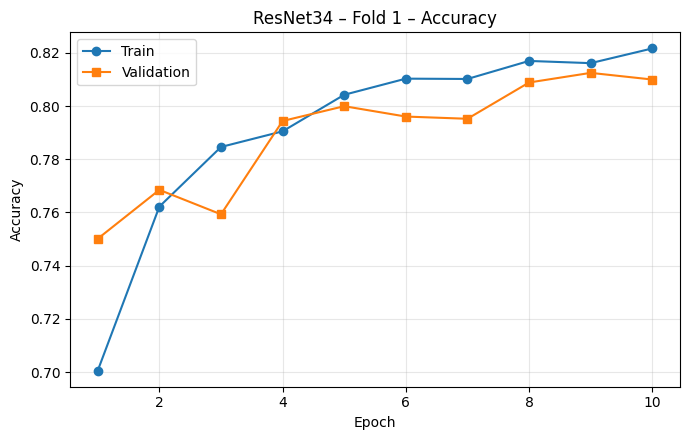

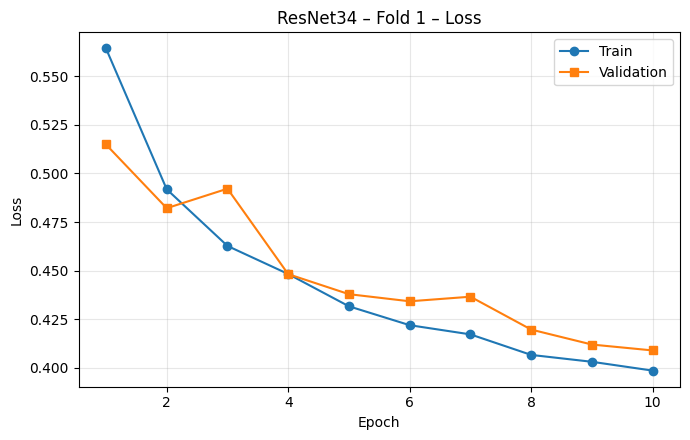

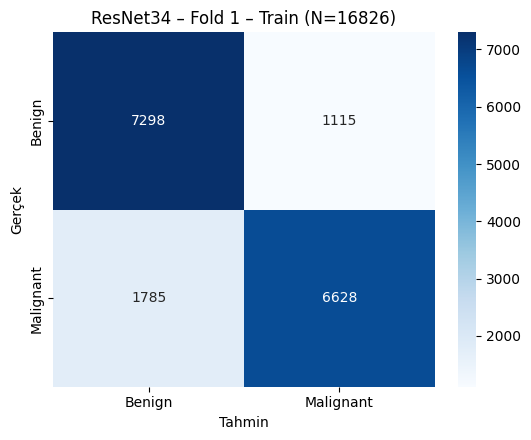

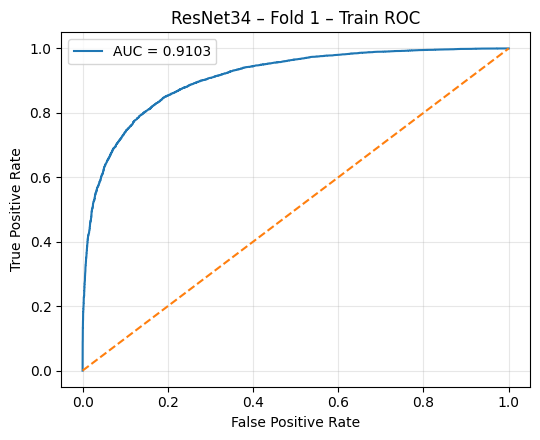

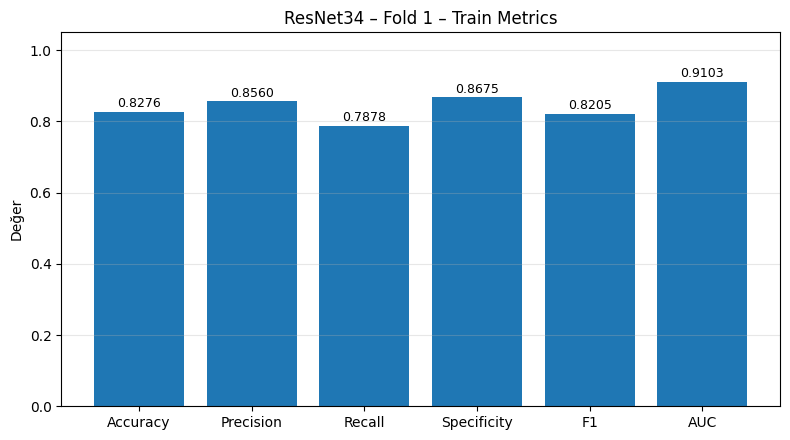

...

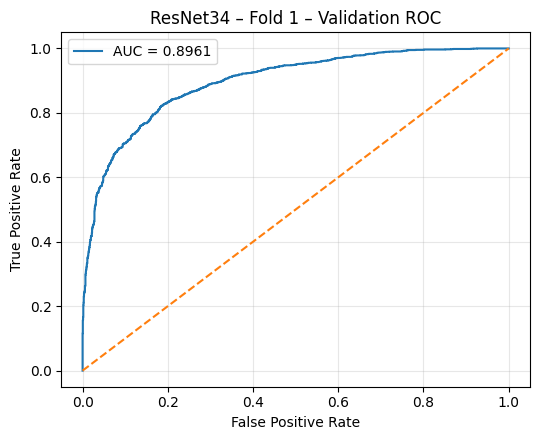

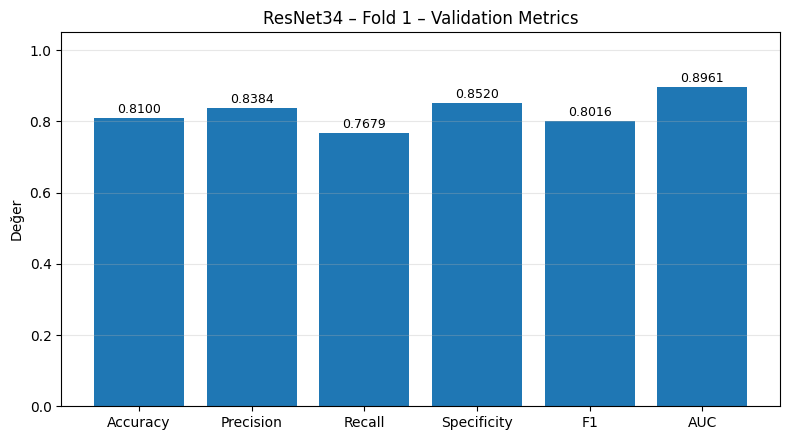

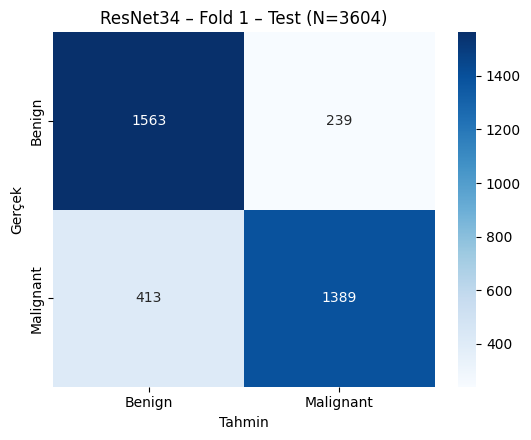

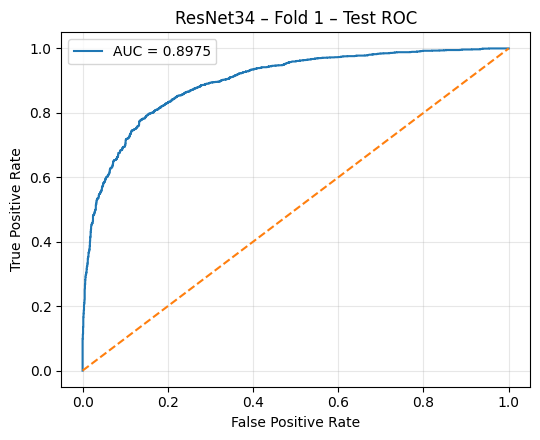

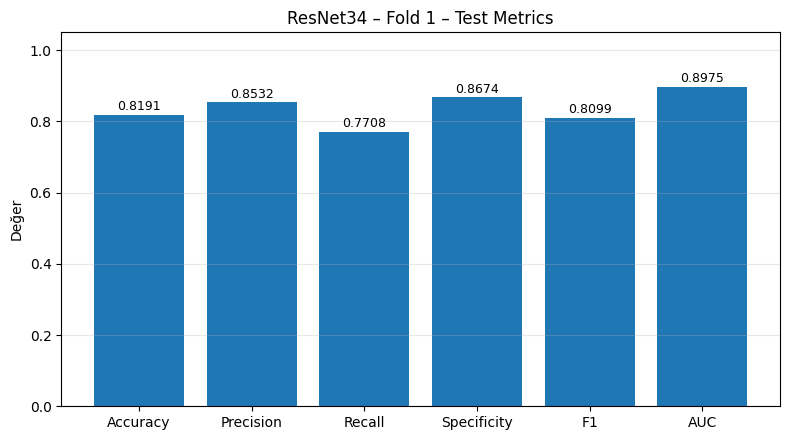

ResNet34 – Fold 1 sonuçları (best epoch = 10):


,N,TN,FP,FN,TP,Accuracy,Precision,Recall (Sensitivity),Specificity,F1-Score,ROC-AUC,Loss
Train,16826.0,7298.0,1115.0,1785.0,6628.0,0.827648,0.855999,0.787828,0.867467,0.820500,0.910328,0.387232
Validation,3594.0,1531.0,266.0,417.0,1380.0,0.809961,0.838396,0.767947,0.851976,0.801626,0.896150,0.408831
Test,3604.0,1563.0,239.0,413.0,1389.0,0.819090,0.853194,0.770810,0.867370,0.809913,0.897534,0.409462


✓ ResNet34 Fold 1: best epoch 10 | Test acc 0.8191
ResNet34 | Fold 2 | Epoch 01/10 | Train loss 0.5656 acc 0.6970 | Val loss 0.5070 acc 0.7507
ResNet34 | Fold 2 | Epoch 02/10 | Train loss 0.4958 acc 0.7590 | Val loss 0.4681 acc 0.7816
ResNet34 | Fold 2 | Epoch 03/10 | Train loss 0.4648 acc 0.7842 | Val loss 0.4824 acc 0.7652
ResNet34 | Fold 2 | Epoch 04/10 | Train loss 0.4483 acc 0.7906 | Val loss 0.4378 acc 0.7963
ResNet34 | Fold 2 | Epoch 05/10 | Train loss 0.4368 acc 0.7972 | Val loss 0.4303 acc 0.7974
ResNet34 | Fold 2 | Epoch 06/10 | Train loss 0.4234 acc 0.8079 | Val loss 0.4211 acc 0.8055
ResNet34 | Fold 2 | Epoch 07/10 | Train loss 0.4170 acc 0.8086 | Val loss 0.4206 acc 0.7999
ResNet34 | Fold 2 | Epoch 08/10 | Train loss 0.4098 acc 0.8155 | Val loss 0.4055 acc 0.8136
ResNet34 | Fold 2 | Epoch 09/10 | Train loss 0.4061 acc 0.8164 | Val loss 0.4017 acc 0.8147
ResNet34 | Fold 2 | Epoch 10/10 | Train loss 0.4031 acc 0.8169 | Val loss 0.3989 acc 0.8169


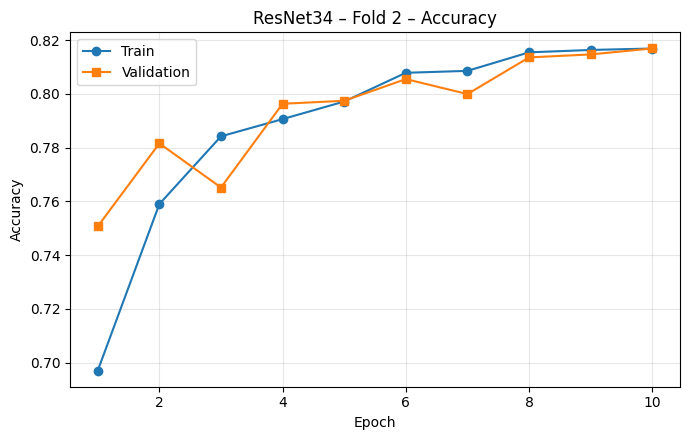

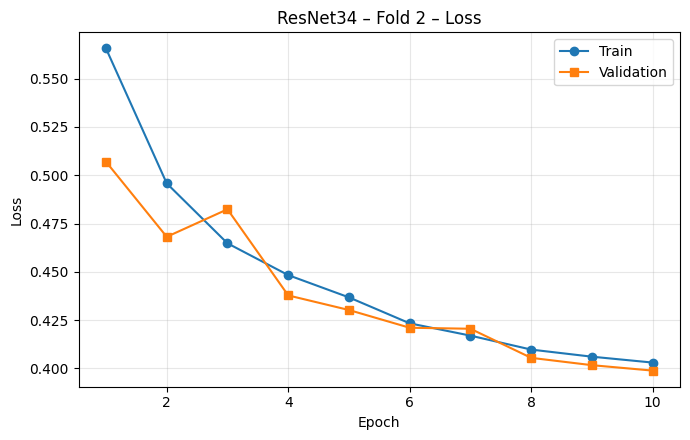

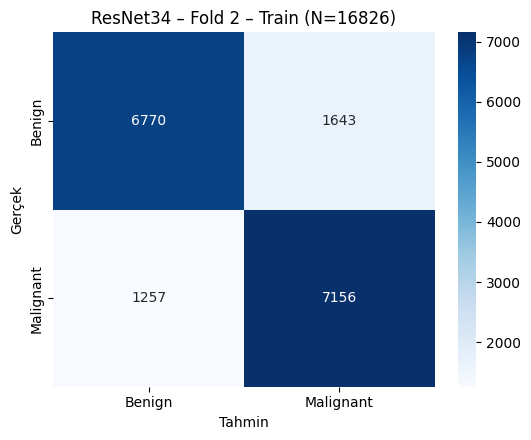

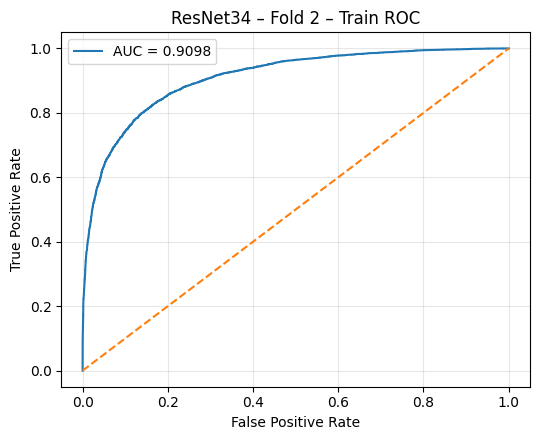

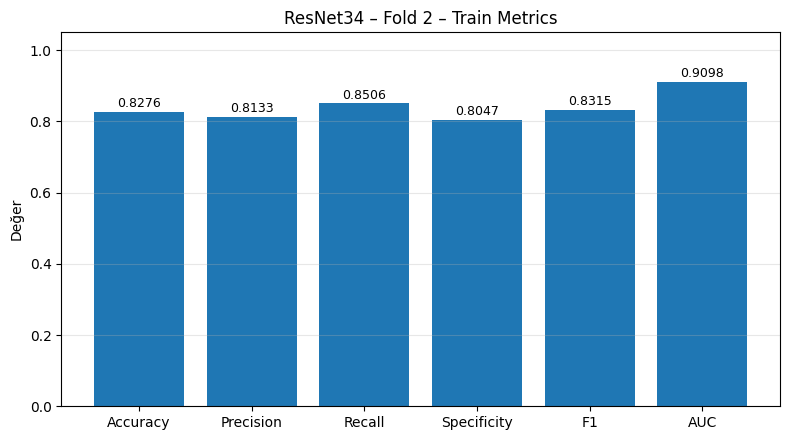

...

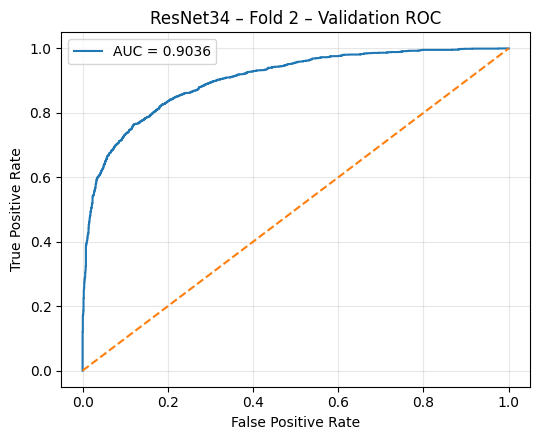

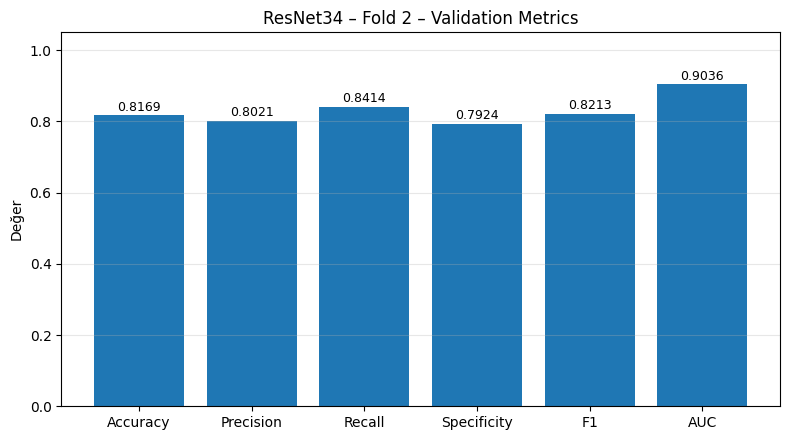

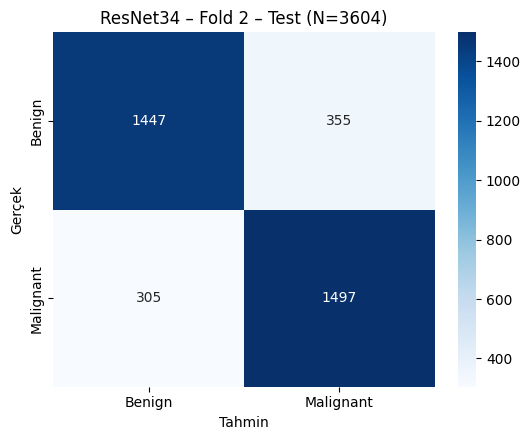

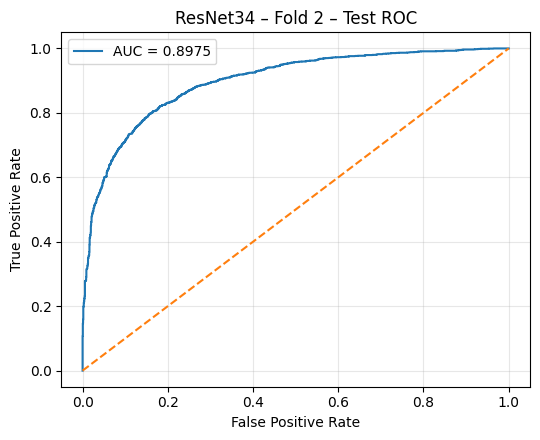

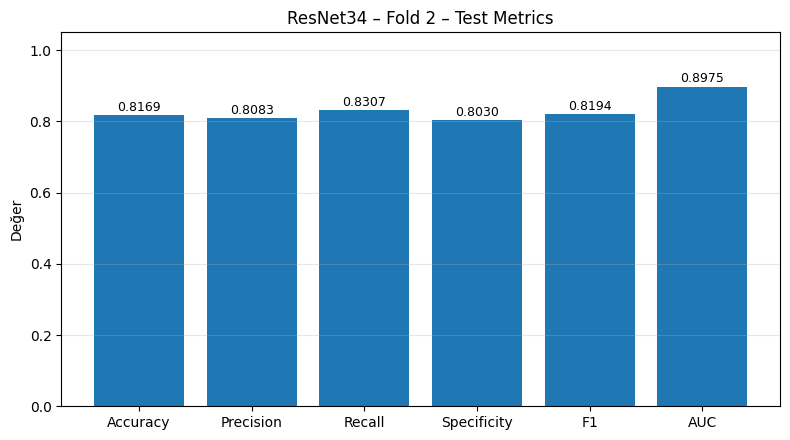

ResNet34 – Fold 2 sonuçları (best epoch = 10):


,N,TN,FP,FN,TP,Accuracy,Precision,Recall (Sensitivity),Specificity,F1-Score,ROC-AUC,Loss
Train,16826.0,6770.0,1643.0,1257.0,7156.0,0.827648,0.813274,0.850588,0.804707,0.831513,0.909835,0.391723
Validation,3594.0,1424.0,373.0,285.0,1512.0,0.816917,0.802122,0.841402,0.792432,0.821293,0.903621,0.398904
Test,3604.0,1447.0,355.0,305.0,1497.0,0.816870,0.808315,0.830744,0.802997,0.819376,0.897453,0.409229


✓ ResNet34 Fold 2: best epoch 10 | Test acc 0.8169
ResNet34 | Fold 3 | Epoch 01/10 | Train loss 0.5647 acc 0.7022 | Val loss 0.5185 acc 0.7468
ResNet34 | Fold 3 | Epoch 02/10 | Train loss 0.4907 acc 0.7645 | Val loss 0.4780 acc 0.7730
ResNet34 | Fold 3 | Epoch 03/10 | Train loss 0.4624 acc 0.7862 | Val loss 0.4601 acc 0.7855
ResNet34 | Fold 3 | Epoch 04/10 | Train loss 0.4466 acc 0.7934 | Val loss 0.4482 acc 0.7874
ResNet34 | Fold 3 | Epoch 05/10 | Train loss 0.4324 acc 0.8013 | Val loss 0.4363 acc 0.8030
ResNet34 | Fold 3 | Epoch 06/10 | Train loss 0.4223 acc 0.8045 | Val loss 0.4418 acc 0.7960
ResNet34 | Fold 3 | Epoch 07/10 | Train loss 0.4156 acc 0.8105 | Val loss 0.4259 acc 0.8133
ResNet34 | Fold 3 | Epoch 08/10 | Train loss 0.4060 acc 0.8189 | Val loss 0.4132 acc 0.8141
ResNet34 | Fold 3 | Epoch 09/10 | Train loss 0.4014 acc 0.8194 | Val loss 0.4117 acc 0.8150
ResNet34 | Fold 3 | Epoch 10/10 | Train loss 0.3996 acc 0.8209 | Val loss 0.4113 acc 0.8169


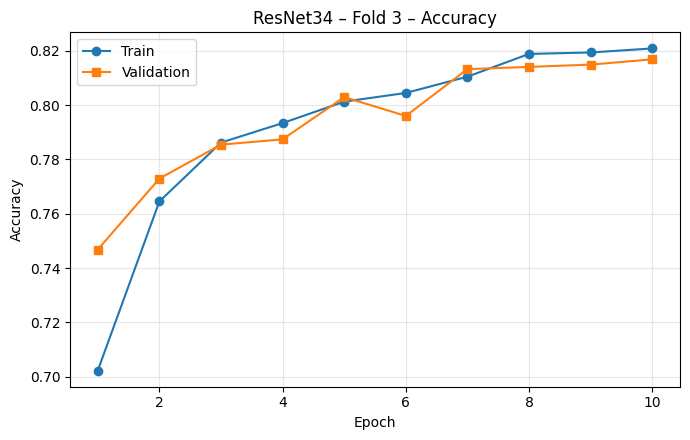

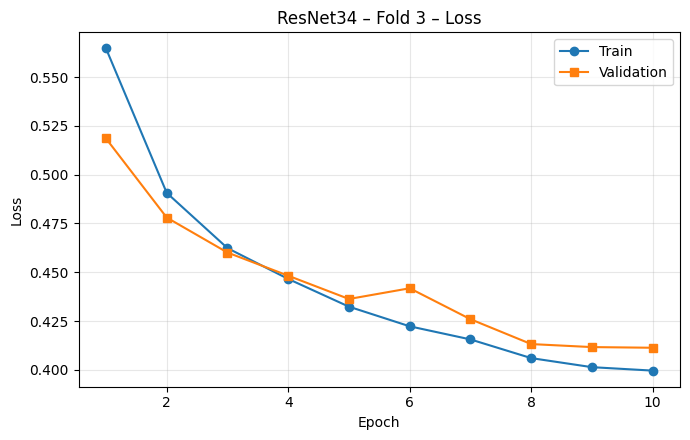

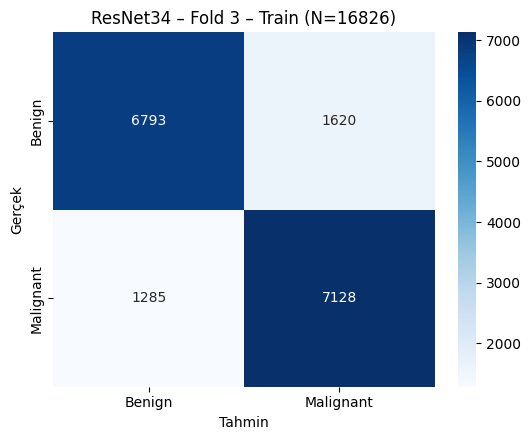

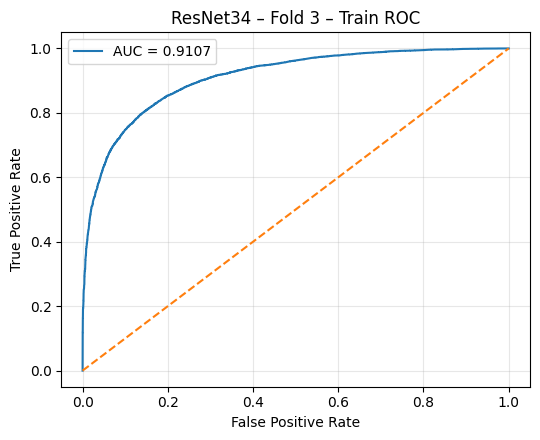

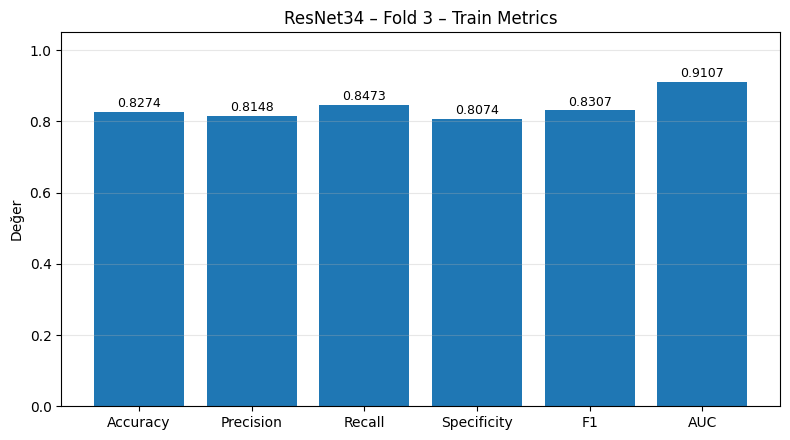

...

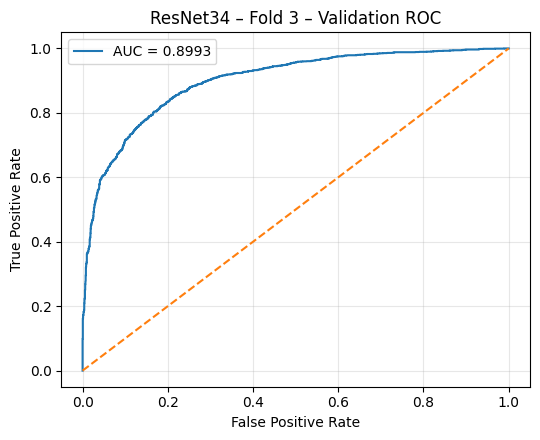

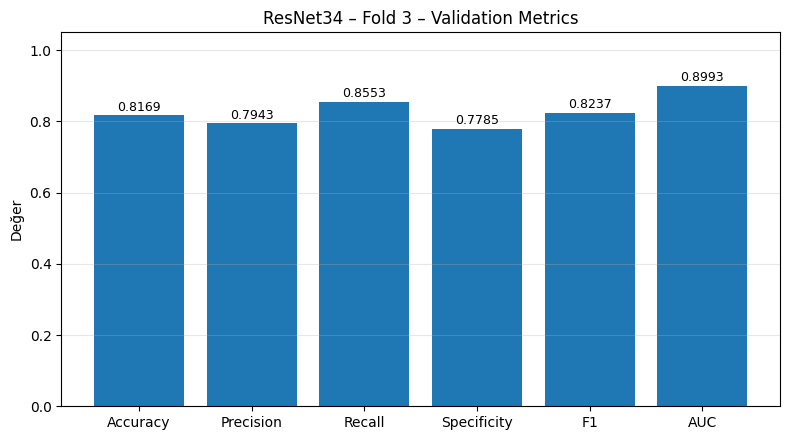

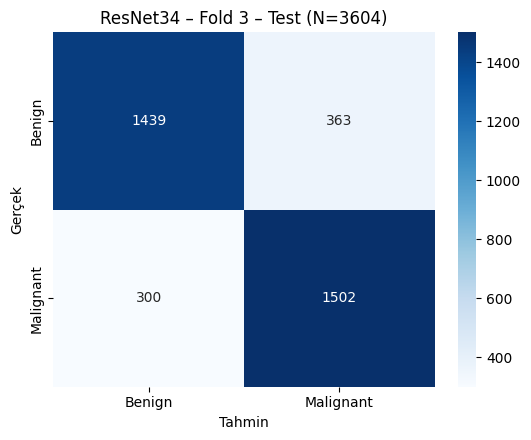

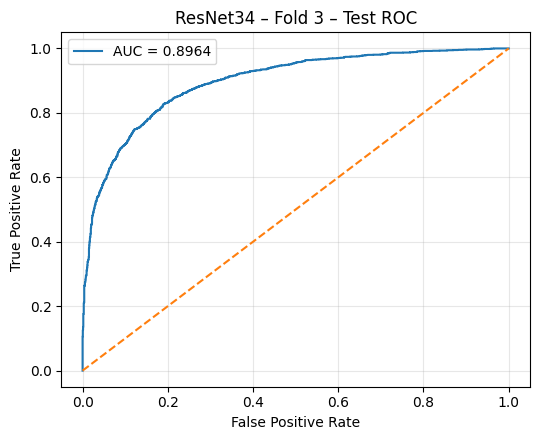

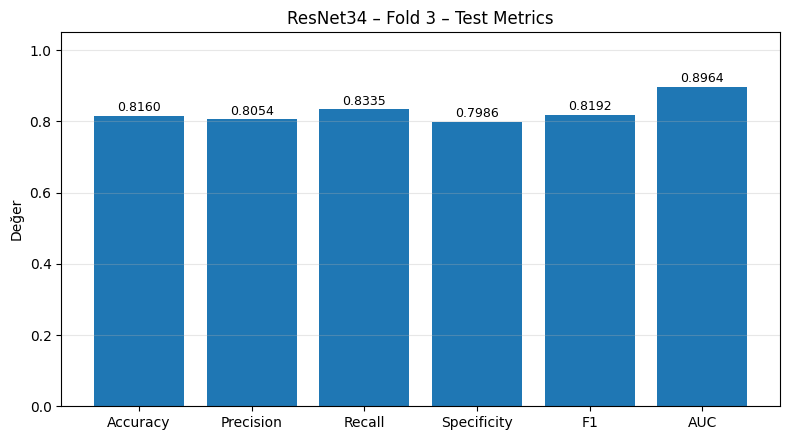

ResNet34 – Fold 3 sonuçları (best epoch = 10):


,N,TN,FP,FN,TP,Accuracy,Precision,Recall (Sensitivity),Specificity,F1-Score,ROC-AUC,Loss
Train,16826.0,6793.0,1620.0,1285.0,7128.0,0.827351,0.814815,0.847260,0.807441,0.830721,0.910724,0.388998
Validation,3594.0,1399.0,398.0,260.0,1537.0,0.816917,0.794315,0.855314,0.778520,0.823687,0.899345,0.411311
Test,3604.0,1439.0,363.0,300.0,1502.0,0.816038,0.805362,0.833518,0.798557,0.819198,0.896362,0.411131


✓ ResNet34 Fold 3: best epoch 10 | Test acc 0.8160
ResNet34 | Fold 4 | Epoch 01/10 | Train loss 0.5622 acc 0.7020 | Val loss 0.5204 acc 0.7418
ResNet34 | Fold 4 | Epoch 02/10 | Train loss 0.4895 acc 0.7645 | Val loss 0.4977 acc 0.7568
ResNet34 | Fold 4 | Epoch 03/10 | Train loss 0.4613 acc 0.7840 | Val loss 0.4681 acc 0.7760
ResNet34 | Fold 4 | Epoch 04/10 | Train loss 0.4434 acc 0.7961 | Val loss 0.4511 acc 0.7916
ResNet34 | Fold 4 | Epoch 05/10 | Train loss 0.4297 acc 0.8046 | Val loss 0.4395 acc 0.7963
ResNet34 | Fold 4 | Epoch 06/10 | Train loss 0.4191 acc 0.8117 | Val loss 0.4334 acc 0.7988
ResNet34 | Fold 4 | Epoch 07/10 | Train loss 0.4123 acc 0.8124 | Val loss 0.4491 acc 0.7799
ResNet34 | Fold 4 | Epoch 08/10 | Train loss 0.4062 acc 0.8164 | Val loss 0.4283 acc 0.8036
ResNet34 | Fold 4 | Epoch 09/10 | Train loss 0.3988 acc 0.8208 | Val loss 0.4168 acc 0.8091
ResNet34 | Fold 4 | Epoch 10/10 | Train loss 0.3966 acc 0.8203 | Val loss 0.4157 acc 0.8136


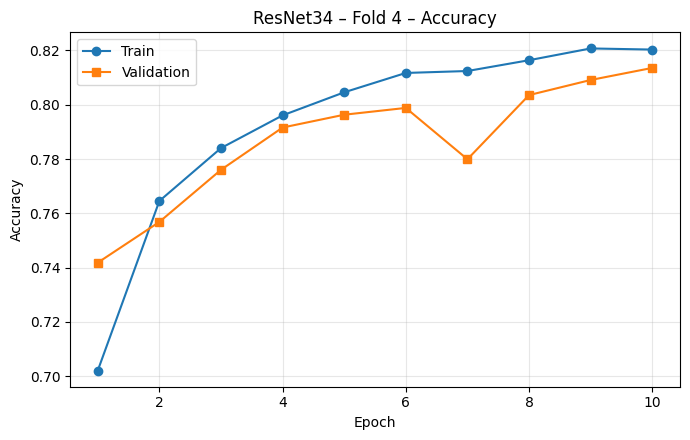

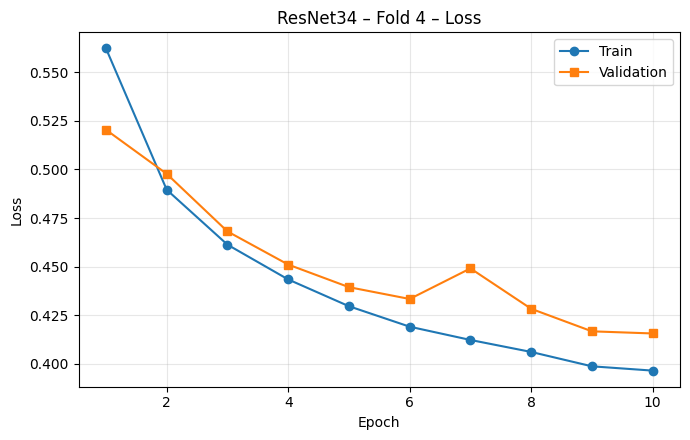

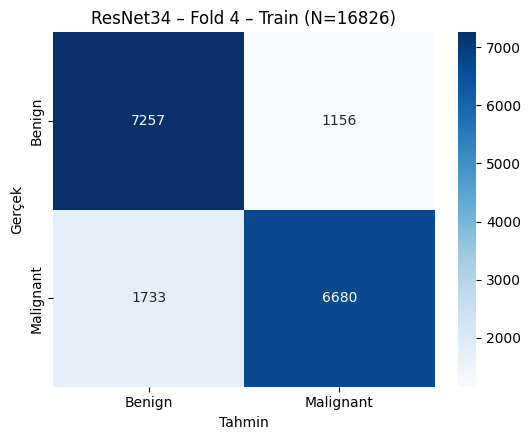

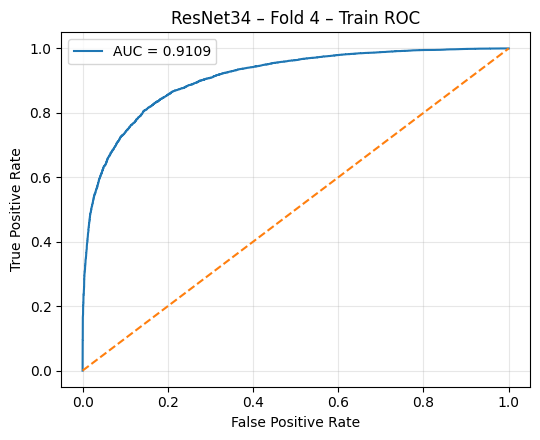

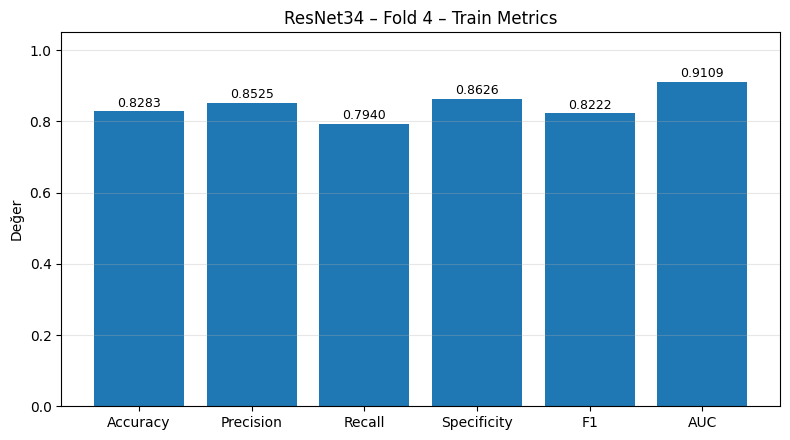

...

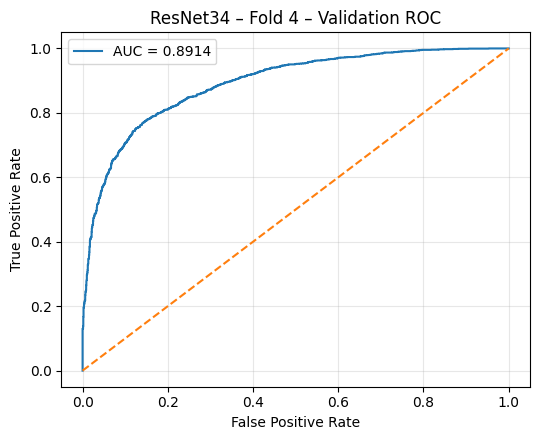

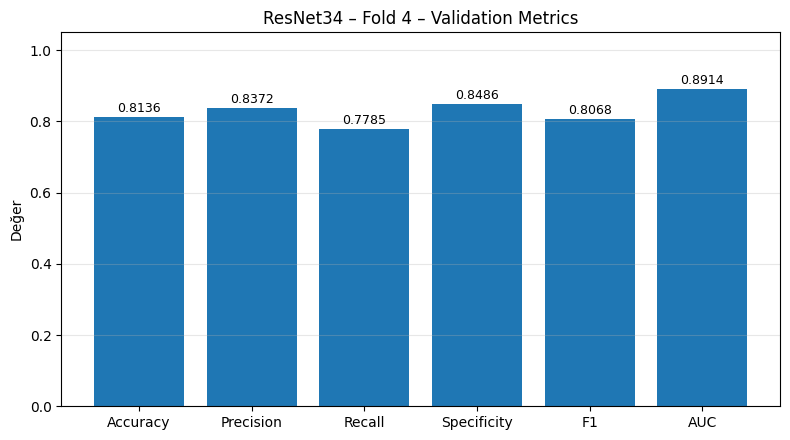

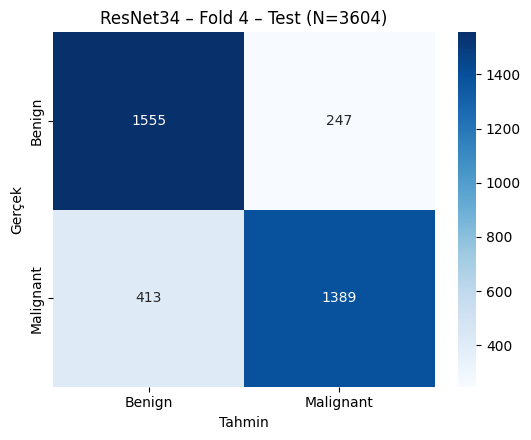

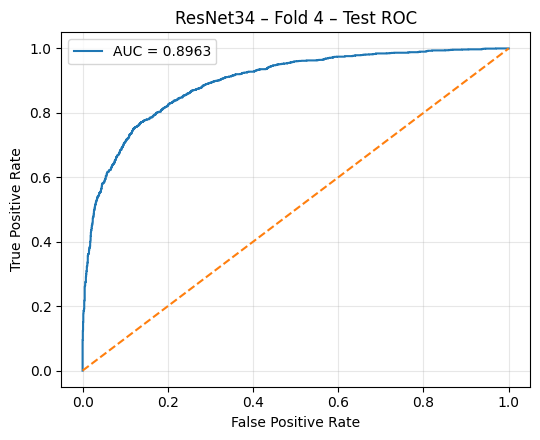

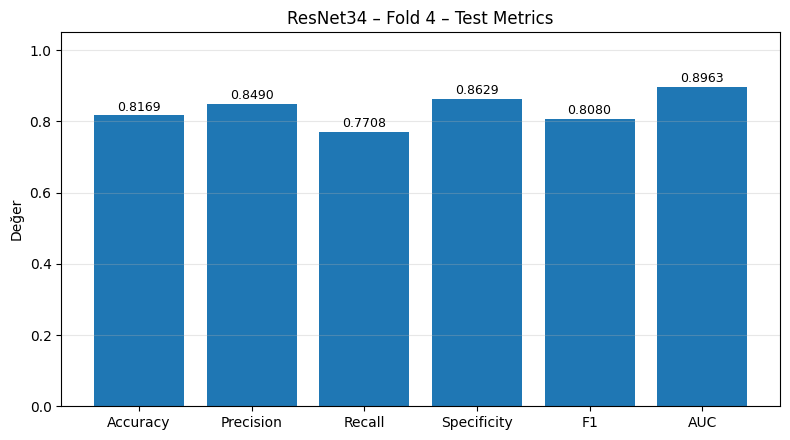

ResNet34 – Fold 4 sonuçları (best epoch = 10):


,N,TN,FP,FN,TP,Accuracy,Precision,Recall (Sensitivity),Specificity,F1-Score,ROC-AUC,Loss
Train,16826.0,7257.0,1156.0,1733.0,6680.0,0.828301,0.852476,0.794009,0.862594,0.822204,0.910924,0.384192
Validation,3594.0,1525.0,272.0,398.0,1399.0,0.813578,0.837223,0.778520,0.848637,0.806805,0.891369,0.415669
Test,3604.0,1555.0,247.0,413.0,1389.0,0.816870,0.849022,0.770810,0.862930,0.808028,0.896273,0.409938


✓ ResNet34 Fold 4: best epoch 10 | Test acc 0.8169
ResNet34 | Fold 5 | Epoch 01/10 | Train loss 0.5667 acc 0.6958 | Val loss 0.4908 acc 0.7679
ResNet34 | Fold 5 | Epoch 02/10 | Train loss 0.4953 acc 0.7635 | Val loss 0.4521 acc 0.7894
ResNet34 | Fold 5 | Epoch 03/10 | Train loss 0.4674 acc 0.7814 | Val loss 0.4369 acc 0.8002
ResNet34 | Fold 5 | Epoch 04/10 | Train loss 0.4518 acc 0.7915 | Val loss 0.4225 acc 0.8072
ResNet34 | Fold 5 | Epoch 05/10 | Train loss 0.4357 acc 0.8031 | Val loss 0.4123 acc 0.8116
ResNet34 | Fold 5 | Epoch 06/10 | Train loss 0.4253 acc 0.8095 | Val loss 0.4086 acc 0.8130
ResNet34 | Fold 5 | Epoch 07/10 | Train loss 0.4227 acc 0.8065 | Val loss 0.4352 acc 0.7935
ResNet34 | Fold 5 | Epoch 08/10 | Train loss 0.4102 acc 0.8150 | Val loss 0.3943 acc 0.8183
ResNet34 | Fold 5 | Epoch 09/10 | Train loss 0.4079 acc 0.8155 | Val loss 0.3915 acc 0.8255
ResNet34 | Fold 5 | Epoch 10/10 | Train loss 0.4023 acc 0.8180 | Val loss 0.3893 acc 0.8211


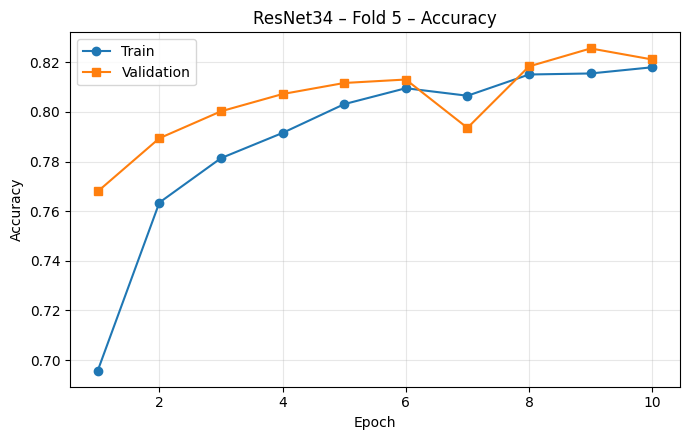

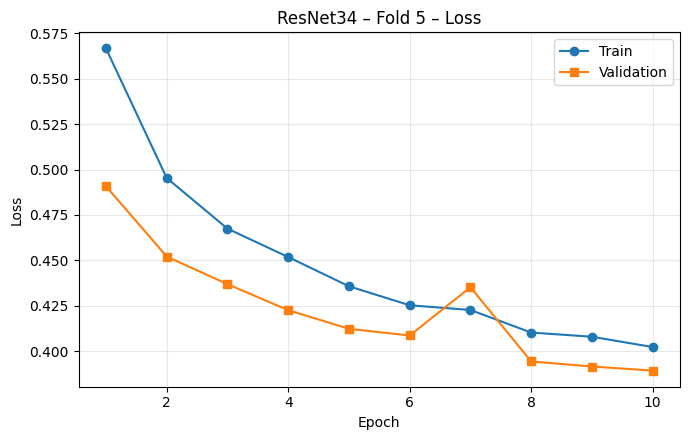

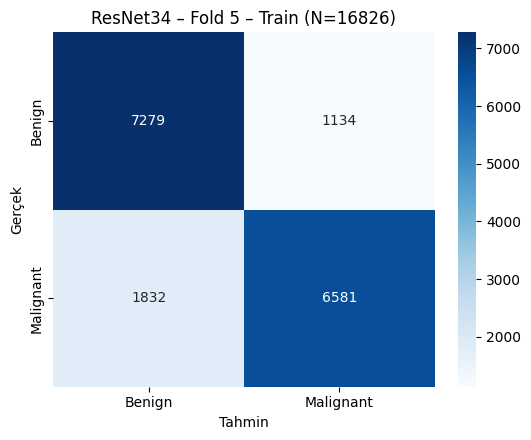

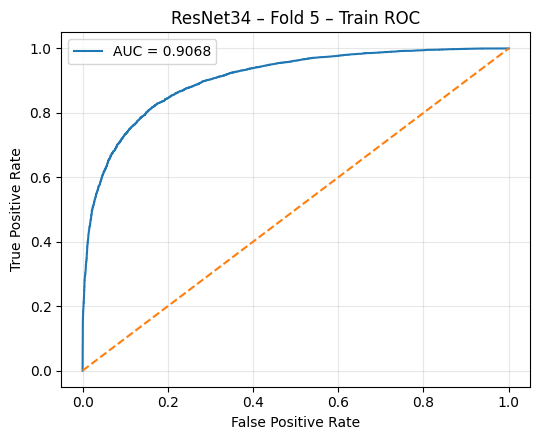

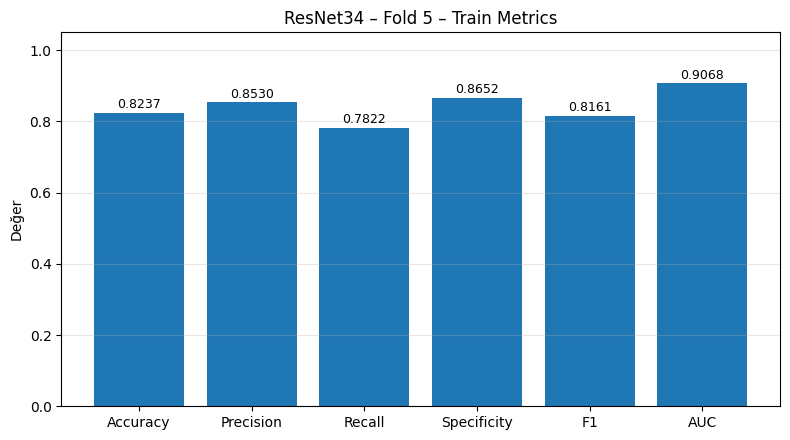

...

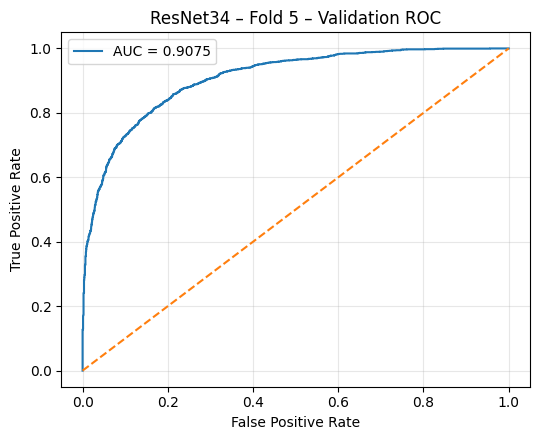

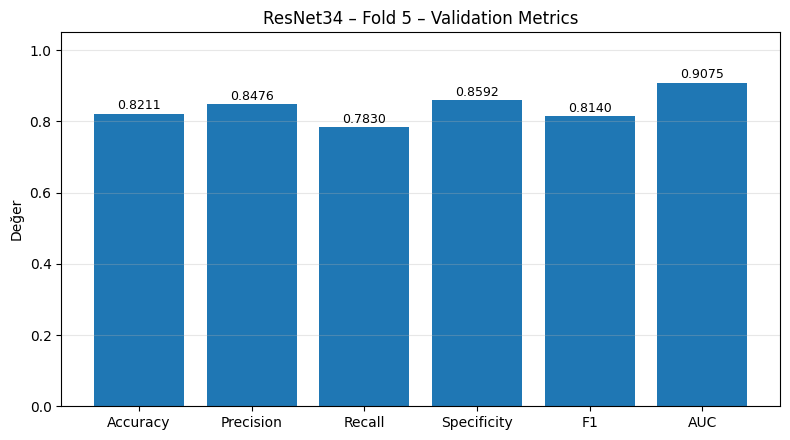

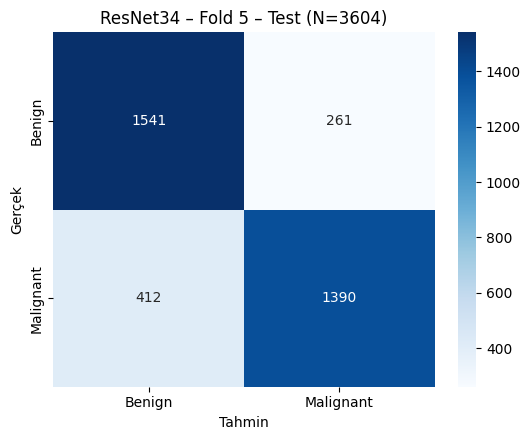

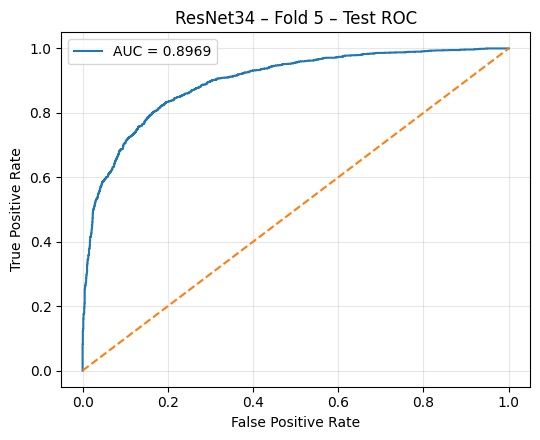

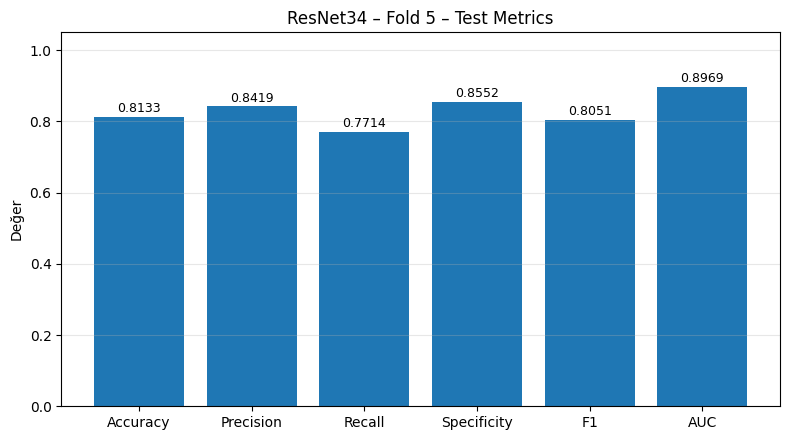

ResNet34 – Fold 5 sonuçları (best epoch = 10):


,N,TN,FP,FN,TP,Accuracy,Precision,Recall (Sensitivity),Specificity,F1-Score,ROC-AUC,Loss
Train,16826.0,7279.0,1134.0,1832.0,6581.0,0.823725,0.853014,0.782242,0.865209,0.816096,0.906845,0.392979
Validation,3594.0,1544.0,253.0,390.0,1407.0,0.821091,0.847590,0.782972,0.859210,0.814001,0.907549,0.389268
Test,3604.0,1541.0,261.0,412.0,1390.0,0.813263,0.841914,0.771365,0.855161,0.805097,0.896933,0.410439


✓ ResNet34 Fold 5: best epoch 10 | Test acc 0.8133
Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth


100%|██████████| 30.8M/30.8M [00:00<00:00, 220MB/s]


DenseNet121 | Fold 1 | Epoch 01/10 | Train loss 0.5519 acc 0.7172 | Val loss 0.4799 acc 0.7727
DenseNet121 | Fold 1 | Epoch 02/10 | Train loss 0.4639 acc 0.7796 | Val loss 0.4441 acc 0.7952
DenseNet121 | Fold 1 | Epoch 03/10 | Train loss 0.4320 acc 0.8025 | Val loss 0.4174 acc 0.8141
DenseNet121 | Fold 1 | Epoch 04/10 | Train loss 0.4137 acc 0.8058 | Val loss 0.3987 acc 0.8267
DenseNet121 | Fold 1 | Epoch 05/10 | Train loss 0.3990 acc 0.8177 | Val loss 0.3913 acc 0.8261
DenseNet121 | Fold 1 | Epoch 06/10 | Train loss 0.3892 acc 0.8266 | Val loss 0.3772 acc 0.8344
DenseNet121 | Fold 1 | Epoch 07/10 | Train loss 0.3854 acc 0.8260 | Val loss 0.3711 acc 0.8378
DenseNet121 | Fold 1 | Epoch 08/10 | Train loss 0.3776 acc 0.8301 | Val loss 0.3724 acc 0.8381
DenseNet121 | Fold 1 | Epoch 09/10 | Train loss 0.3707 acc 0.8340 | Val loss 0.3650 acc 0.8431
DenseNet121 | Fold 1 | Epoch 10/10 | Train loss 0.3710 acc 0.8340 | Val loss 0.3685 acc 0.8358


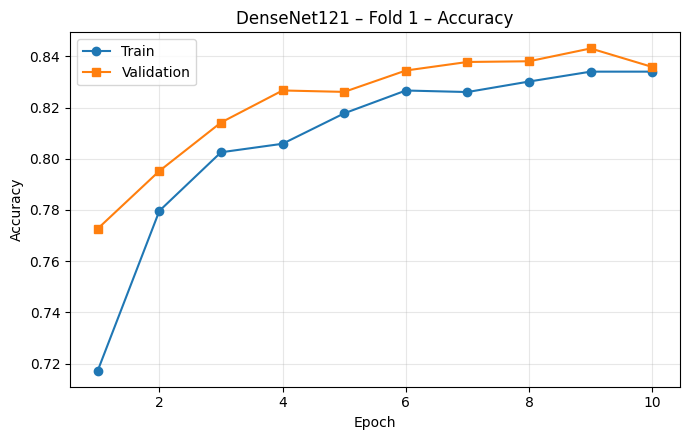

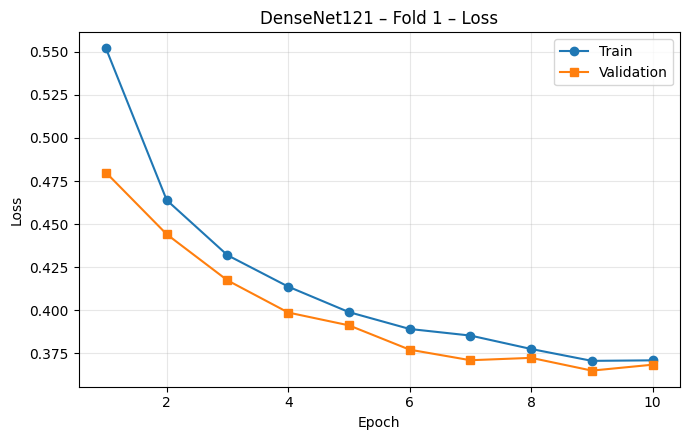

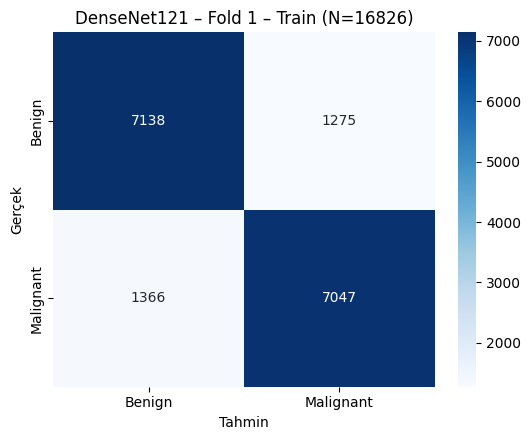

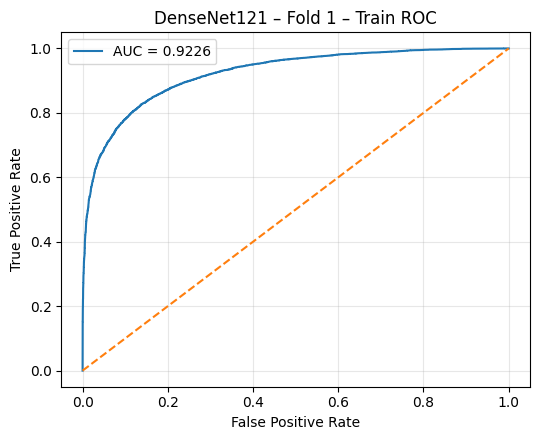

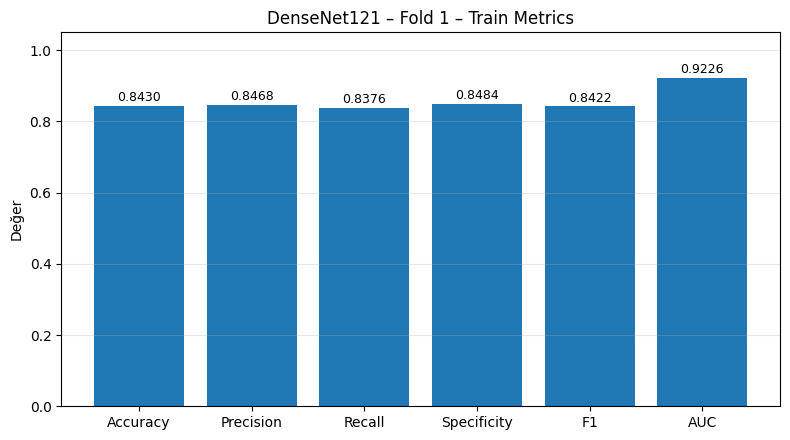

...

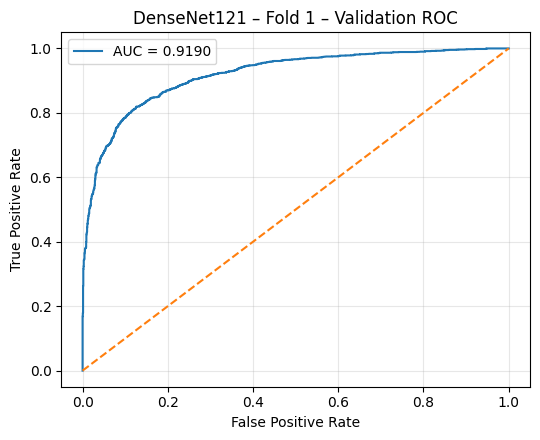

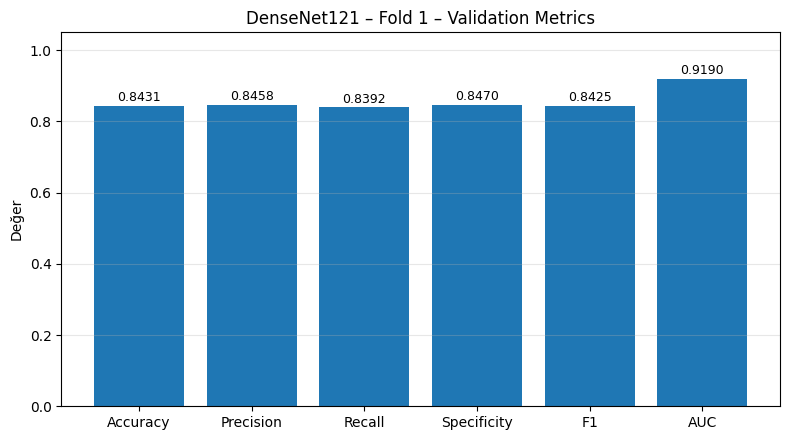

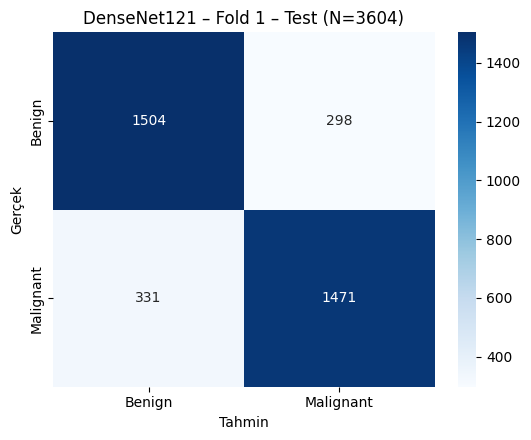

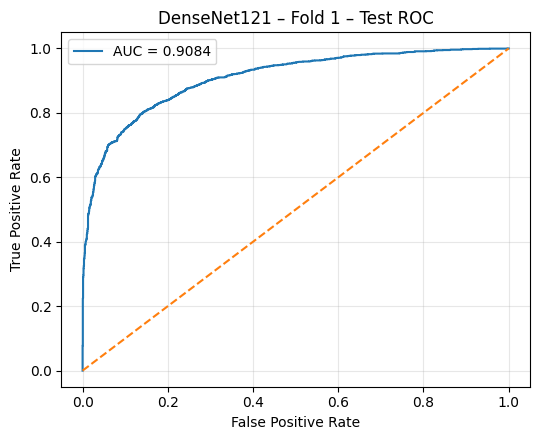

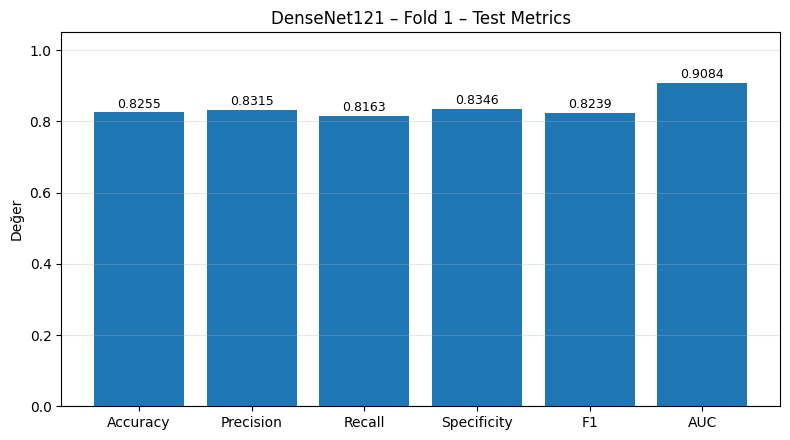

DenseNet121 – Fold 1 sonuçları (best epoch = 9):


,N,TN,FP,FN,TP,Accuracy,Precision,Recall (Sensitivity),Specificity,F1-Score,ROC-AUC,Loss
Train,16826.0,7138.0,1275.0,1366.0,7047.0,0.843041,0.846792,0.837632,0.848449,0.842187,0.922609,0.358370
Validation,3594.0,1522.0,275.0,289.0,1508.0,0.843072,0.845766,0.839176,0.846967,0.842458,0.918971,0.365031
Test,3604.0,1504.0,298.0,331.0,1471.0,0.825472,0.831543,0.816315,0.834628,0.823859,0.908391,0.382996


✓ DenseNet121 Fold 1: best epoch 9 | Test acc 0.8255
DenseNet121 | Fold 2 | Epoch 01/10 | Train loss 0.5529 acc 0.7115 | Val loss 0.4778 acc 0.7802
DenseNet121 | Fold 2 | Epoch 02/10 | Train loss 0.4638 acc 0.7833 | Val loss 0.4425 acc 0.7977
DenseNet121 | Fold 2 | Epoch 03/10 | Train loss 0.4325 acc 0.8000 | Val loss 0.4176 acc 0.8133
DenseNet121 | Fold 2 | Epoch 04/10 | Train loss 0.4140 acc 0.8115 | Val loss 0.4084 acc 0.8219
DenseNet121 | Fold 2 | Epoch 05/10 | Train loss 0.3986 acc 0.8187 | Val loss 0.4002 acc 0.8214
DenseNet121 | Fold 2 | Epoch 06/10 | Train loss 0.3879 acc 0.8245 | Val loss 0.3993 acc 0.8125
DenseNet121 | Fold 2 | Epoch 07/10 | Train loss 0.3832 acc 0.8251 | Val loss 0.3833 acc 0.8253
DenseNet121 | Fold 2 | Epoch 08/10 | Train loss 0.3749 acc 0.8326 | Val loss 0.3737 acc 0.8358
DenseNet121 | Fold 2 | Epoch 09/10 | Train loss 0.3712 acc 0.8339 | Val loss 0.3736 acc 0.8314
DenseNet121 | Fold 2 | Epoch 10/10 | Train loss 0.3654 acc 0.8385 | Val loss 0.3804 acc 0.83

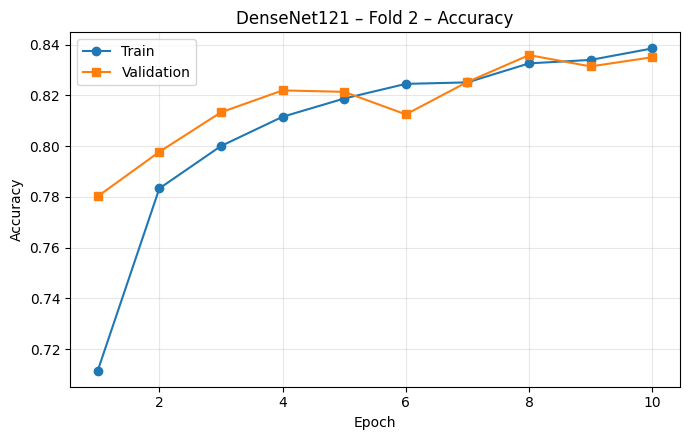

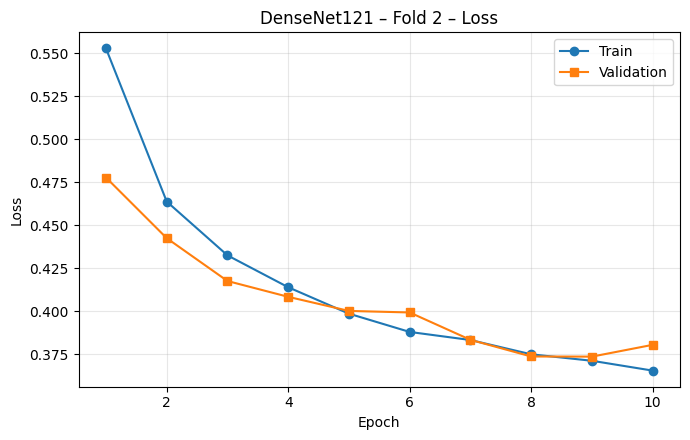

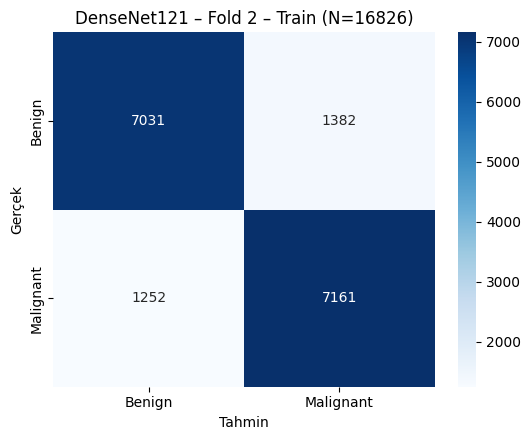

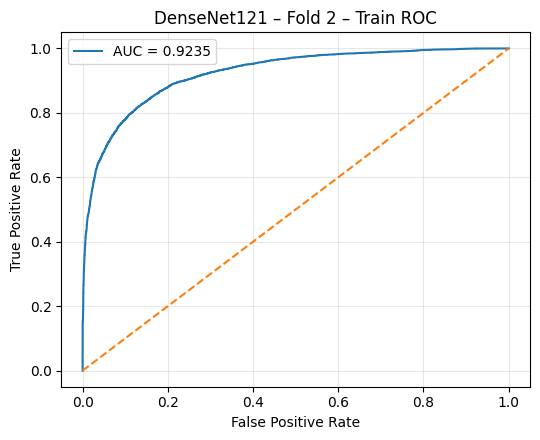

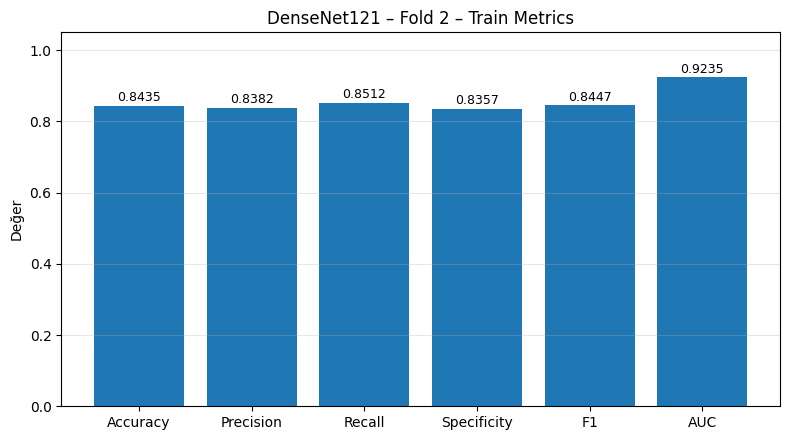

...

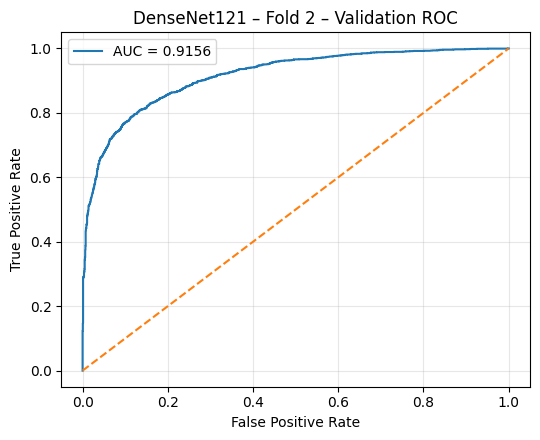

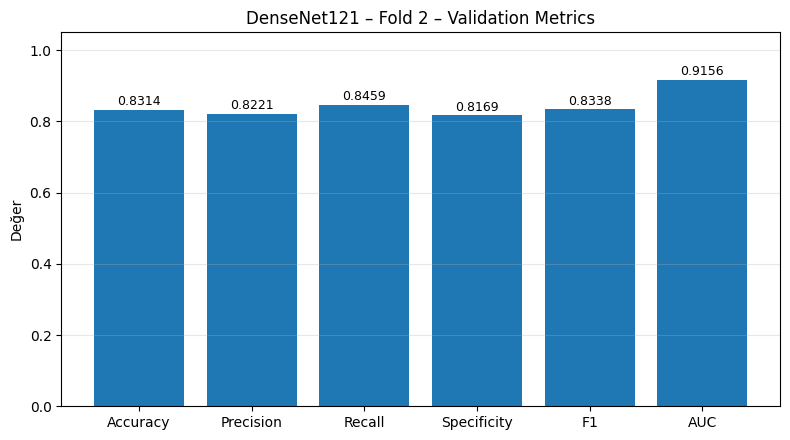

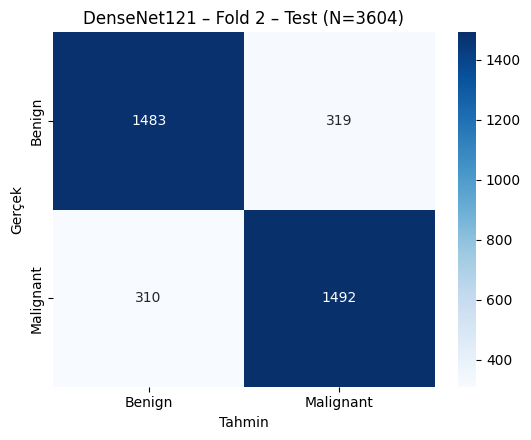

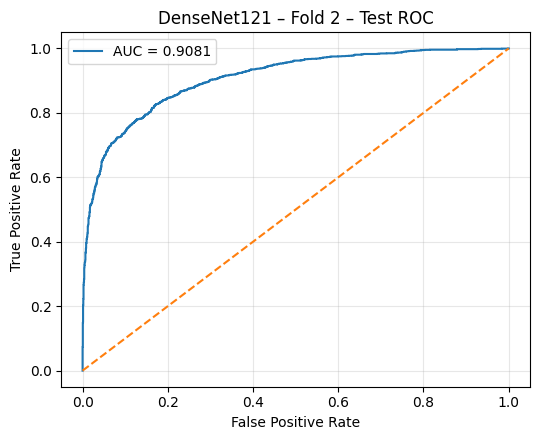

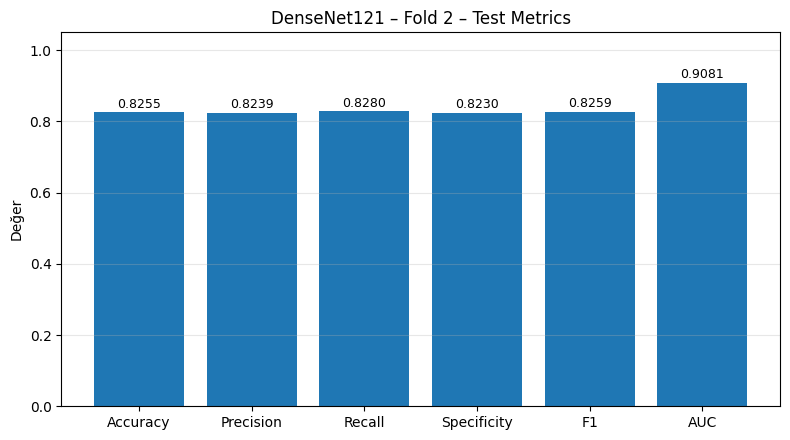

DenseNet121 – Fold 2 sonuçları (best epoch = 9):


,N,TN,FP,FN,TP,Accuracy,Precision,Recall (Sensitivity),Specificity,F1-Score,ROC-AUC,Loss
Train,16826.0,7031.0,1382.0,1252.0,7161.0,0.843457,0.838230,0.851183,0.835730,0.844657,0.923533,0.358126
Validation,3594.0,1468.0,329.0,277.0,1520.0,0.831386,0.822066,0.845854,0.816917,0.833790,0.915574,0.373584
Test,3604.0,1483.0,319.0,310.0,1492.0,0.825472,0.823854,0.827969,0.822974,0.825906,0.908100,0.384382


✓ DenseNet121 Fold 2: best epoch 9 | Test acc 0.8255
DenseNet121 | Fold 3 | Epoch 01/10 | Train loss 0.5487 acc 0.7159 | Val loss 0.4844 acc 0.7654
DenseNet121 | Fold 3 | Epoch 02/10 | Train loss 0.4596 acc 0.7846 | Val loss 0.4431 acc 0.7905
DenseNet121 | Fold 3 | Epoch 03/10 | Train loss 0.4279 acc 0.8036 | Val loss 0.4300 acc 0.7994
DenseNet121 | Fold 3 | Epoch 04/10 | Train loss 0.4115 acc 0.8132 | Val loss 0.4068 acc 0.8130
DenseNet121 | Fold 3 | Epoch 05/10 | Train loss 0.3968 acc 0.8203 | Val loss 0.4088 acc 0.8033
DenseNet121 | Fold 3 | Epoch 06/10 | Train loss 0.3894 acc 0.8232 | Val loss 0.3919 acc 0.8214
DenseNet121 | Fold 3 | Epoch 07/10 | Train loss 0.3808 acc 0.8278 | Val loss 0.3881 acc 0.8158
DenseNet121 | Fold 3 | Epoch 08/10 | Train loss 0.3755 acc 0.8307 | Val loss 0.3794 acc 0.8278
DenseNet121 | Fold 3 | Epoch 09/10 | Train loss 0.3714 acc 0.8326 | Val loss 0.3779 acc 0.8244
DenseNet121 | Fold 3 | Epoch 10/10 | Train loss 0.3665 acc 0.8364 | Val loss 0.3761 acc 0.82

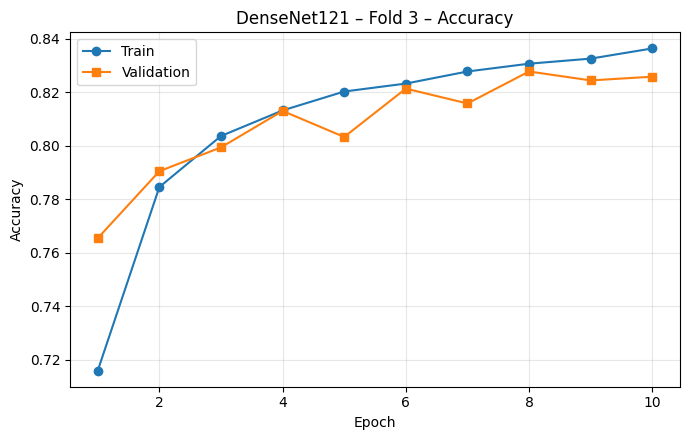

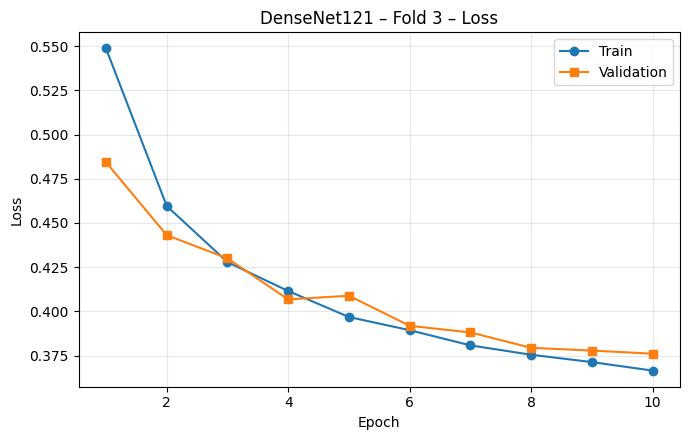

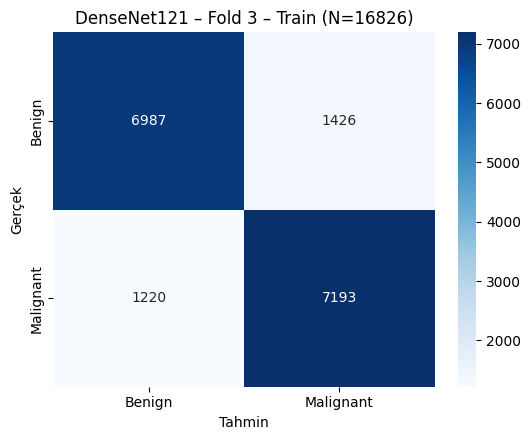

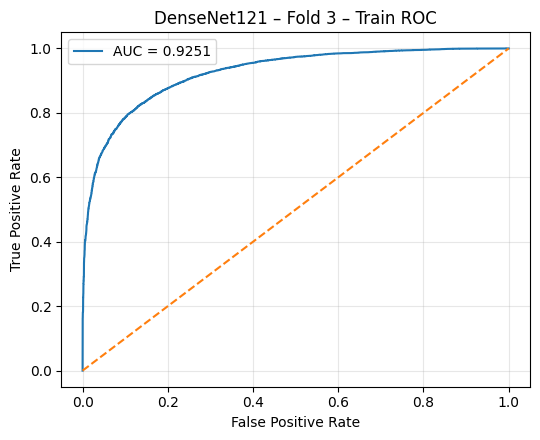

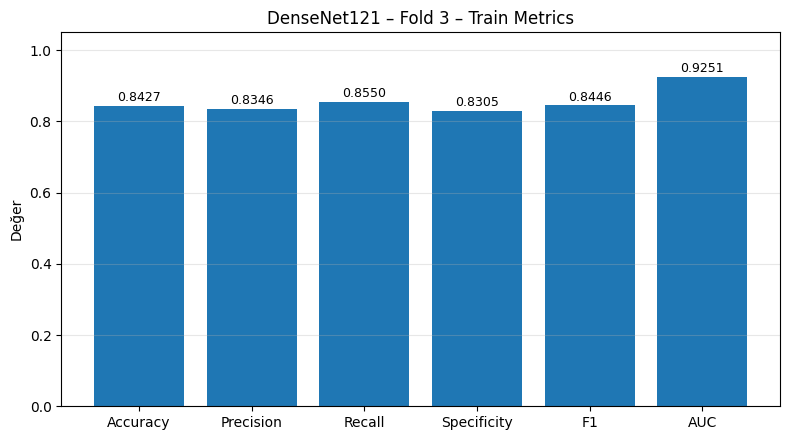

...

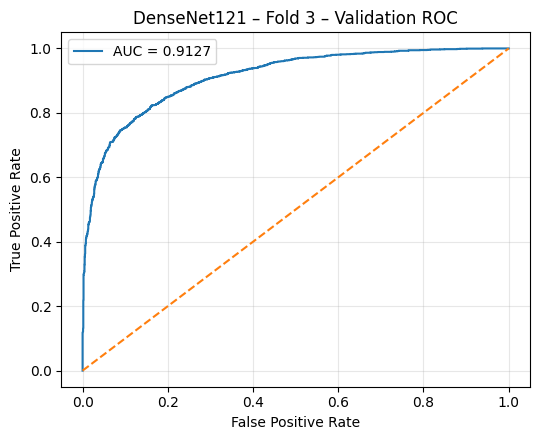

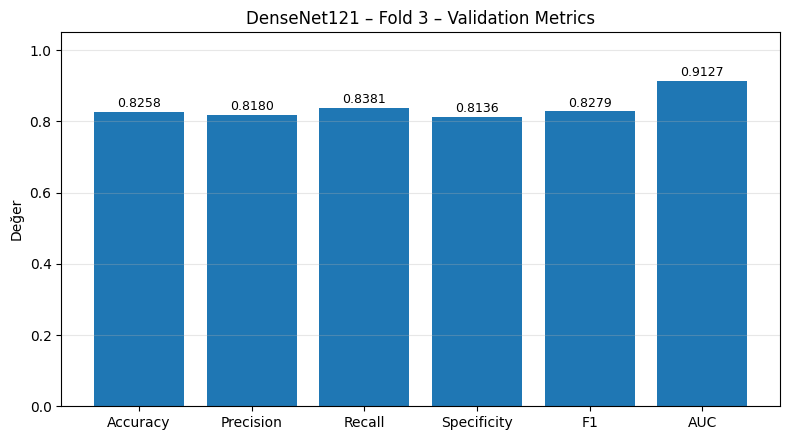

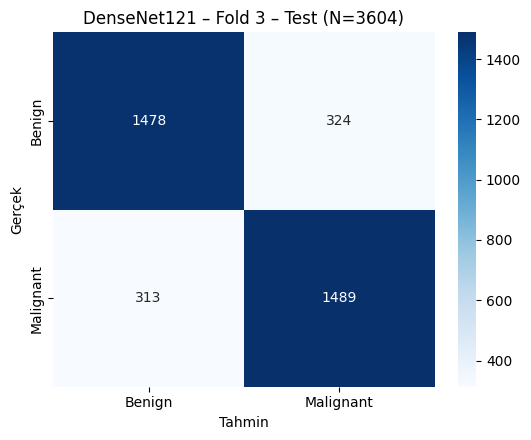

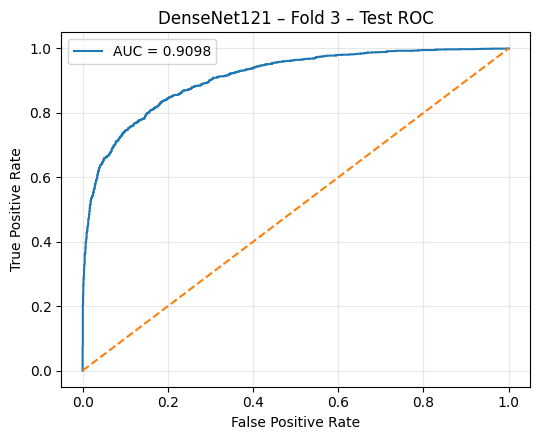

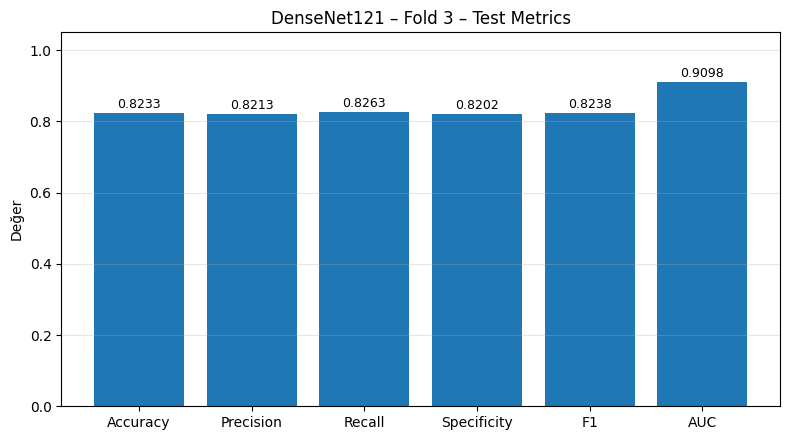

DenseNet121 – Fold 3 sonuçları (best epoch = 10):


,N,TN,FP,FN,TP,Accuracy,Precision,Recall (Sensitivity),Specificity,F1-Score,ROC-AUC,Loss
Train,16826.0,6987.0,1426.0,1220.0,7193.0,0.842743,0.834552,0.854986,0.830500,0.844645,0.925088,0.353929
Validation,3594.0,1462.0,335.0,291.0,1506.0,0.825821,0.818034,0.838063,0.813578,0.827927,0.912661,0.376091
Test,3604.0,1478.0,324.0,313.0,1489.0,0.823252,0.821291,0.826304,0.820200,0.823790,0.909767,0.380397


✓ DenseNet121 Fold 3: best epoch 10 | Test acc 0.8233
DenseNet121 | Fold 4 | Epoch 01/10 | Train loss 0.5470 acc 0.7203 | Val loss 0.4894 acc 0.7710
DenseNet121 | Fold 4 | Epoch 02/10 | Train loss 0.4598 acc 0.7822 | Val loss 0.4539 acc 0.7963
DenseNet121 | Fold 4 | Epoch 03/10 | Train loss 0.4277 acc 0.8042 | Val loss 0.4323 acc 0.8069
DenseNet121 | Fold 4 | Epoch 04/10 | Train loss 0.4089 acc 0.8143 | Val loss 0.4160 acc 0.8155
DenseNet121 | Fold 4 | Epoch 05/10 | Train loss 0.3955 acc 0.8196 | Val loss 0.4139 acc 0.8139
DenseNet121 | Fold 4 | Epoch 06/10 | Train loss 0.3852 acc 0.8267 | Val loss 0.4017 acc 0.8169
DenseNet121 | Fold 4 | Epoch 07/10 | Train loss 0.3788 acc 0.8288 | Val loss 0.4016 acc 0.8166
DenseNet121 | Fold 4 | Epoch 08/10 | Train loss 0.3710 acc 0.8335 | Val loss 0.3902 acc 0.8216
DenseNet121 | Fold 4 | Epoch 09/10 | Train loss 0.3656 acc 0.8378 | Val loss 0.3936 acc 0.8236
DenseNet121 | Fold 4 | Epoch 10/10 | Train loss 0.3630 acc 0.8383 | Val loss 0.3870 acc 0.8

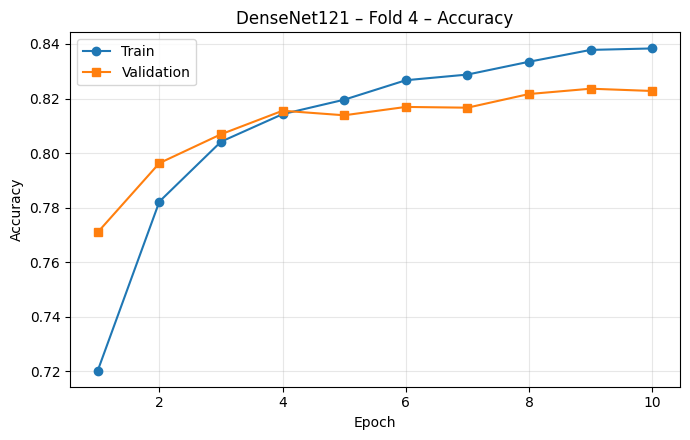

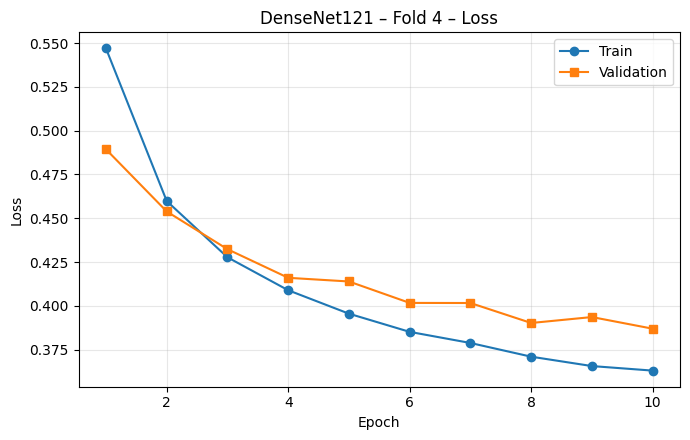

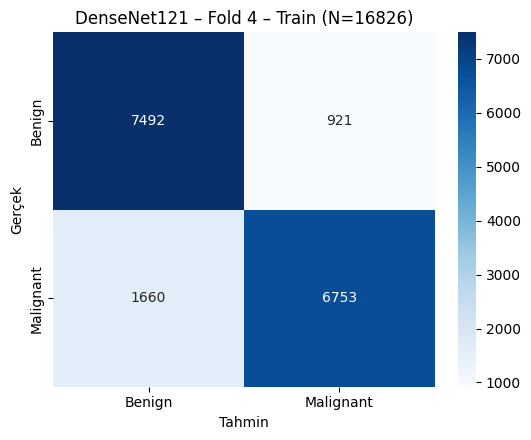

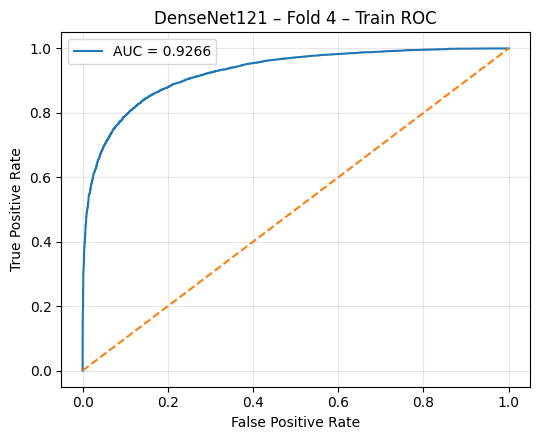

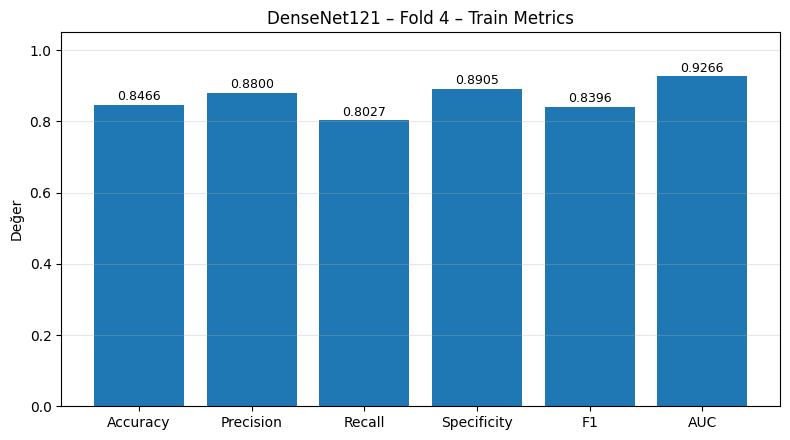

...

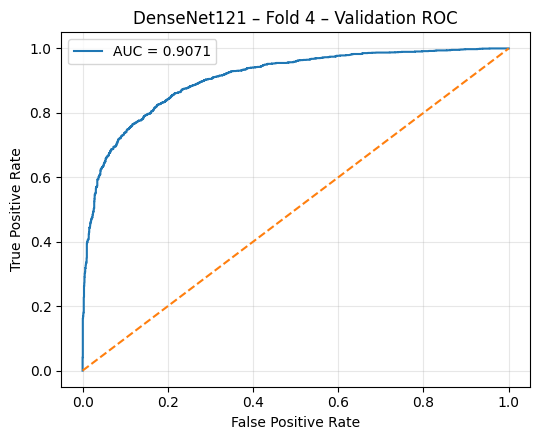

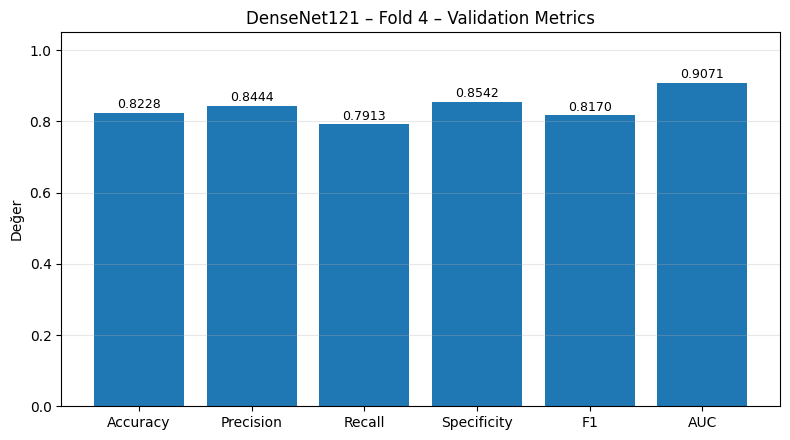

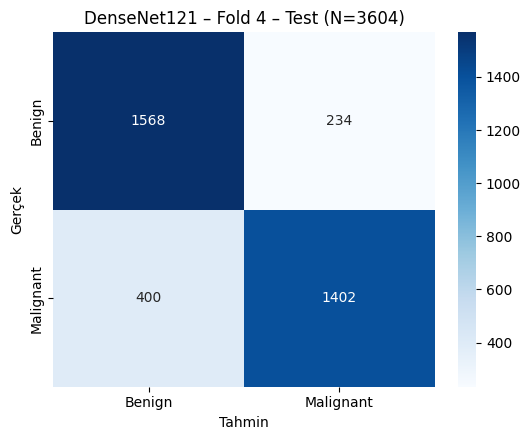

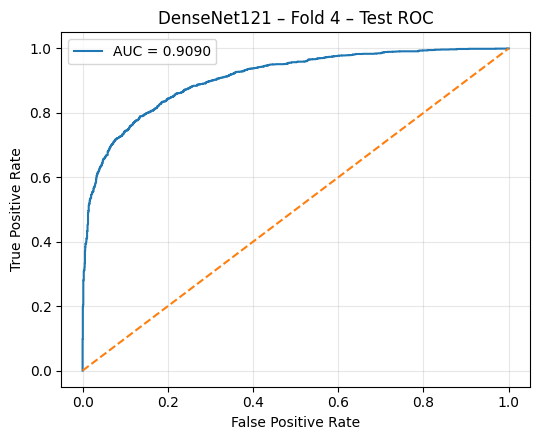

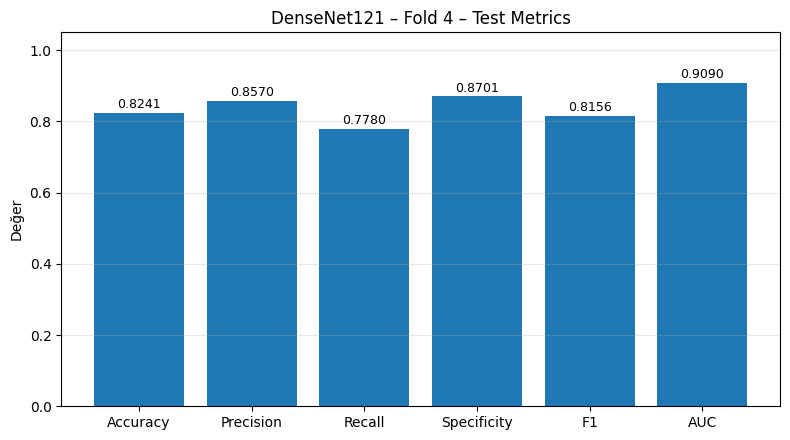

DenseNet121 – Fold 4 sonuçları (best epoch = 10):


,N,TN,FP,FN,TP,Accuracy,Precision,Recall (Sensitivity),Specificity,F1-Score,ROC-AUC,Loss
Train,16826.0,7492.0,921.0,1660.0,6753.0,0.846606,0.879984,0.802686,0.890527,0.839560,0.926577,0.349601
Validation,3594.0,1535.0,262.0,375.0,1422.0,0.822760,0.844418,0.791319,0.854201,0.817007,0.907145,0.386971
Test,3604.0,1568.0,234.0,400.0,1402.0,0.824084,0.856968,0.778024,0.870144,0.815590,0.909001,0.384184


✓ DenseNet121 Fold 4: best epoch 10 | Test acc 0.8241
DenseNet121 | Fold 5 | Epoch 01/10 | Train loss 0.5514 acc 0.7153 | Val loss 0.4632 acc 0.7938
DenseNet121 | Fold 5 | Epoch 02/10 | Train loss 0.4620 acc 0.7833 | Val loss 0.4306 acc 0.8108
DenseNet121 | Fold 5 | Epoch 03/10 | Train loss 0.4313 acc 0.8010 | Val loss 0.4107 acc 0.8178
DenseNet121 | Fold 5 | Epoch 04/10 | Train loss 0.4174 acc 0.8073 | Val loss 0.3882 acc 0.8311
DenseNet121 | Fold 5 | Epoch 05/10 | Train loss 0.4014 acc 0.8196 | Val loss 0.3781 acc 0.8408
DenseNet121 | Fold 5 | Epoch 06/10 | Train loss 0.3900 acc 0.8232 | Val loss 0.3721 acc 0.8328
DenseNet121 | Fold 5 | Epoch 07/10 | Train loss 0.3839 acc 0.8291 | Val loss 0.3865 acc 0.8233
DenseNet121 | Fold 5 | Epoch 08/10 | Train loss 0.3767 acc 0.8310 | Val loss 0.4083 acc 0.8191
DenseNet121 | Fold 5 | Epoch 09/10 | Train loss 0.3746 acc 0.8333 | Val loss 0.3643 acc 0.8472
DenseNet121 | Fold 5 | Epoch 10/10 | Train loss 0.3695 acc 0.8350 | Val loss 0.3662 acc 0.8

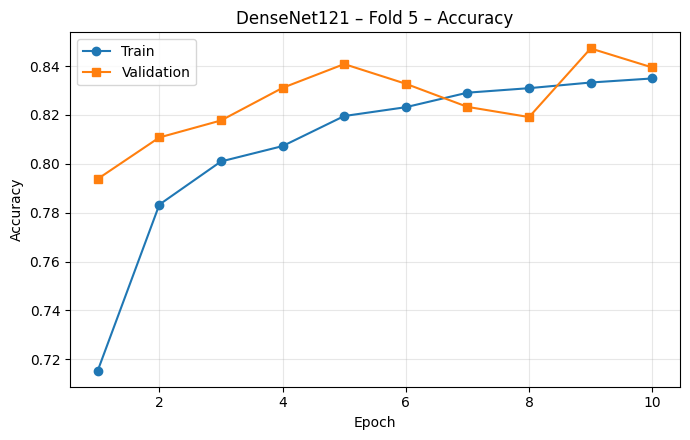

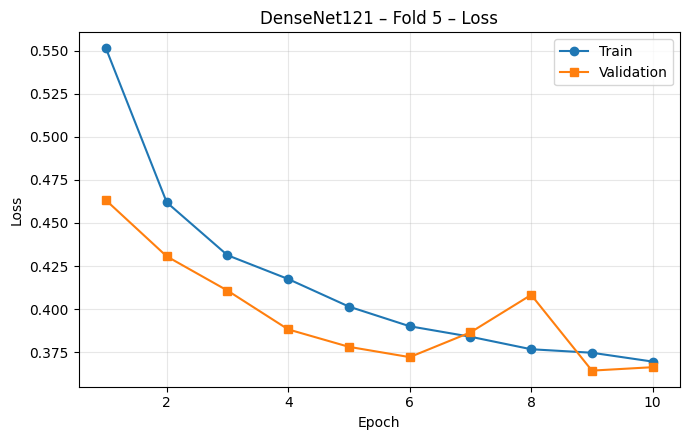

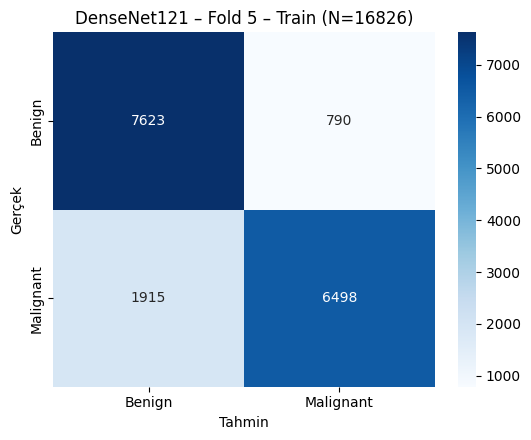

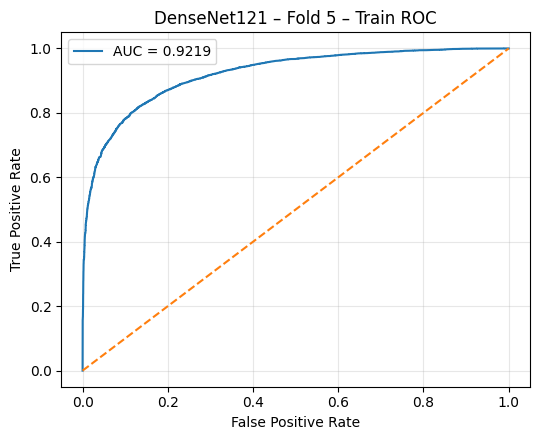

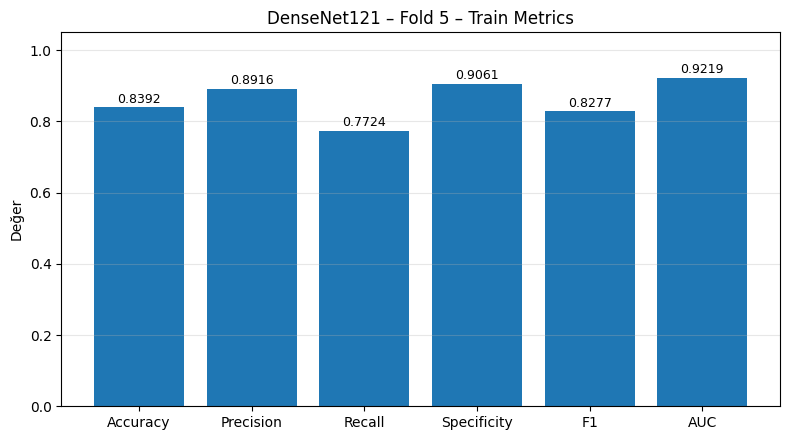

...

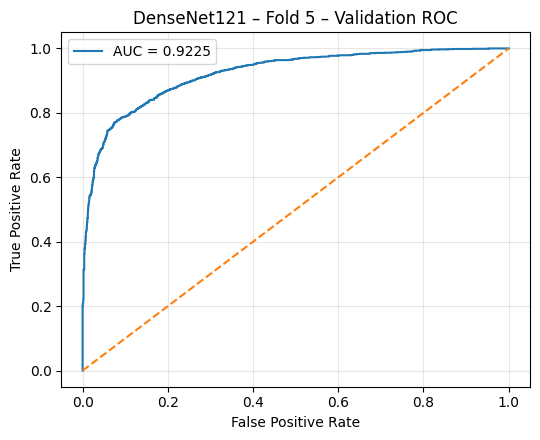

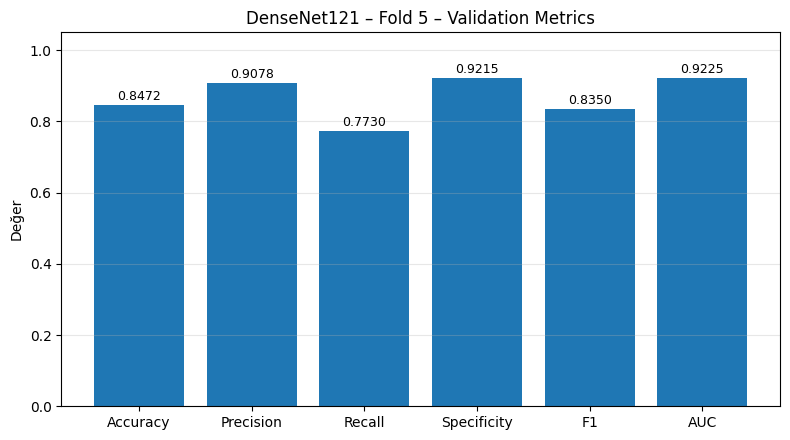

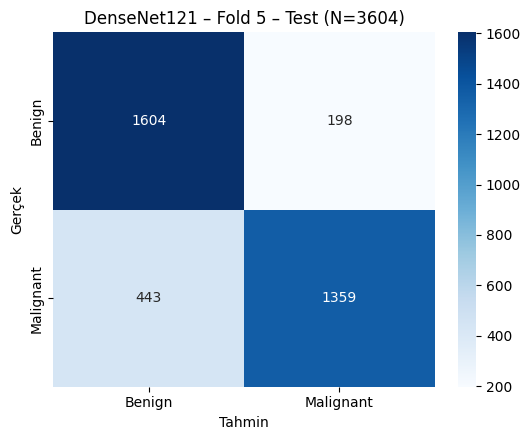

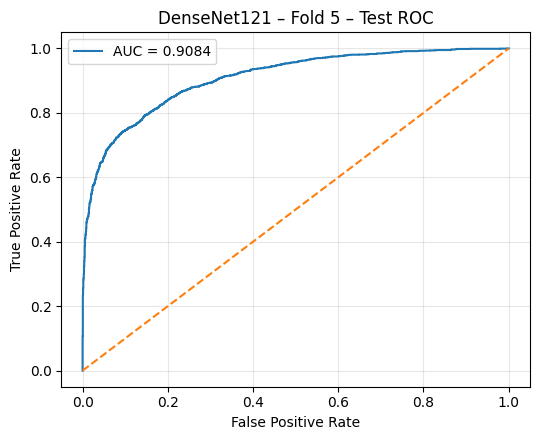

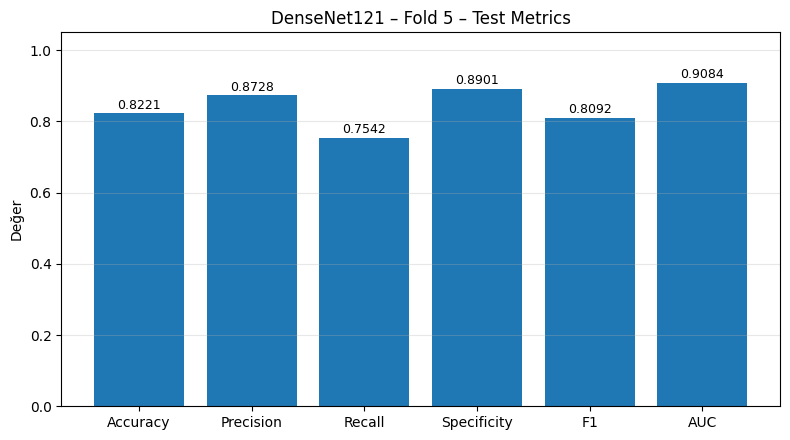

DenseNet121 – Fold 5 sonuçları (best epoch = 9):


,N,TN,FP,FN,TP,Accuracy,Precision,Recall (Sensitivity),Specificity,F1-Score,ROC-AUC,Loss
Train,16826.0,7623.0,790.0,1915.0,6498.0,0.839237,0.891603,0.772376,0.906098,0.827718,0.921876,0.365136
Validation,3594.0,1656.0,141.0,408.0,1389.0,0.847245,0.907843,0.772955,0.921536,0.834986,0.922487,0.364263
Test,3604.0,1604.0,198.0,443.0,1359.0,0.822142,0.872832,0.754162,0.890122,0.809169,0.908355,0.392125


✓ DenseNet121 Fold 5: best epoch 9 | Test acc 0.8221
Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 224MB/s]


EfficientNet-B0 | Fold 1 | Epoch 01/10 | Train loss 0.4879 acc 0.7650 | Val loss 0.4145 acc 0.8230
EfficientNet-B0 | Fold 1 | Epoch 02/10 | Train loss 0.3828 acc 0.8341 | Val loss 0.3626 acc 0.8425
EfficientNet-B0 | Fold 1 | Epoch 03/10 | Train loss 0.3427 acc 0.8540 | Val loss 0.3379 acc 0.8495
EfficientNet-B0 | Fold 1 | Epoch 04/10 | Train loss 0.3179 acc 0.8692 | Val loss 0.3106 acc 0.8723
EfficientNet-B0 | Fold 1 | Epoch 05/10 | Train loss 0.2977 acc 0.8783 | Val loss 0.2996 acc 0.8770
EfficientNet-B0 | Fold 1 | Epoch 06/10 | Train loss 0.2844 acc 0.8840 | Val loss 0.2870 acc 0.8820
EfficientNet-B0 | Fold 1 | Epoch 07/10 | Train loss 0.2718 acc 0.8914 | Val loss 0.2765 acc 0.8912
EfficientNet-B0 | Fold 1 | Epoch 08/10 | Train loss 0.2627 acc 0.8969 | Val loss 0.2682 acc 0.8915
EfficientNet-B0 | Fold 1 | Epoch 09/10 | Train loss 0.2557 acc 0.8994 | Val loss 0.2641 acc 0.8923
EfficientNet-B0 | Fold 1 | Epoch 10/10 | Train loss 0.2466 acc 0.9022 | Val loss 0.2600 acc 0.8943


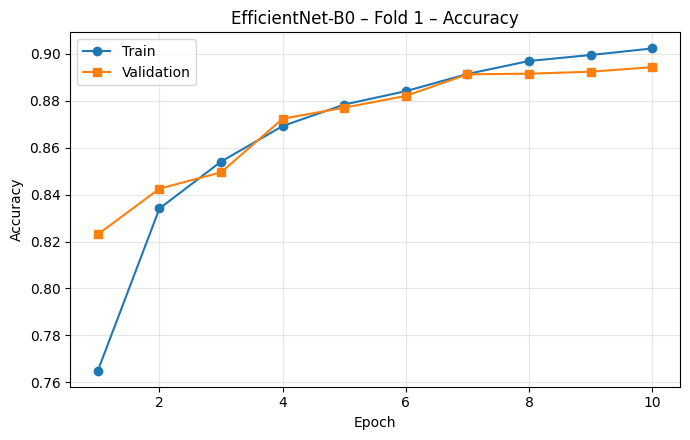

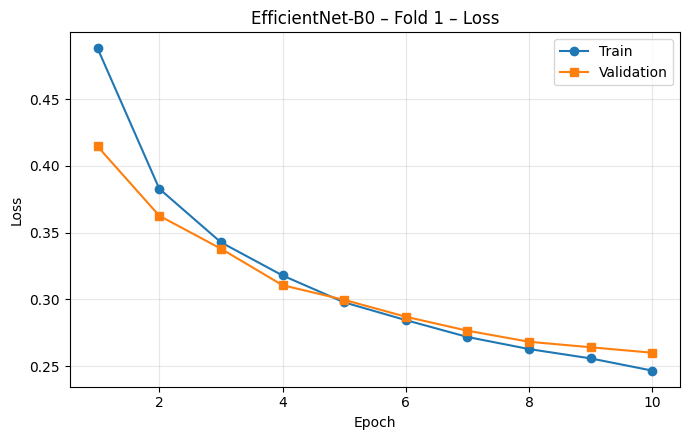

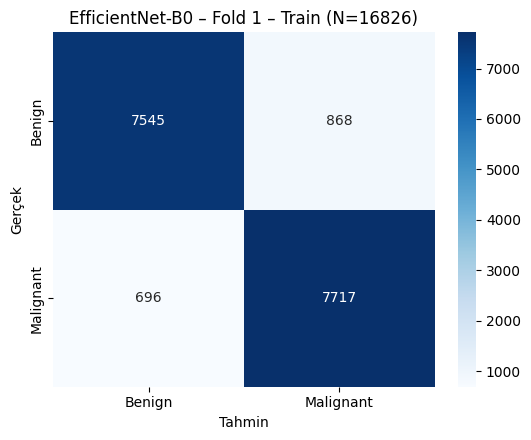

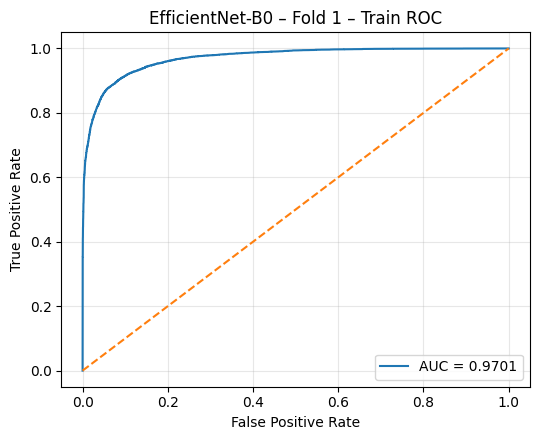

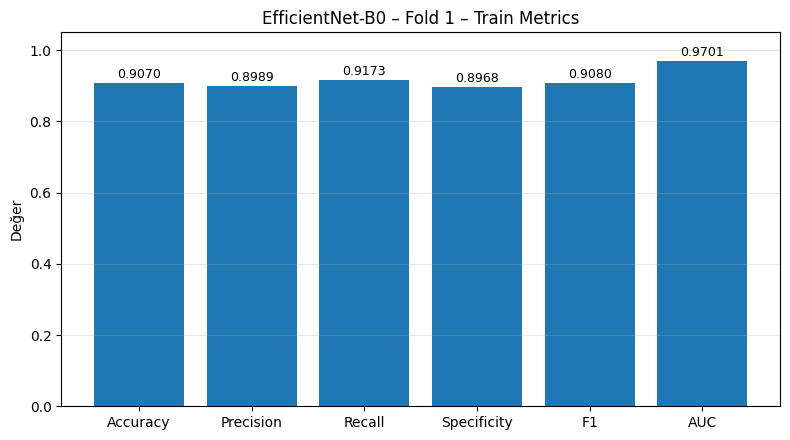

...

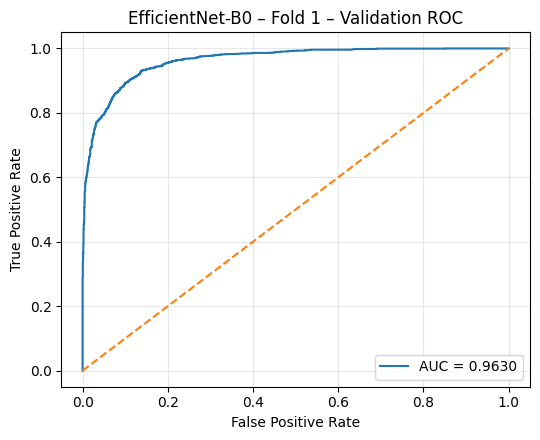

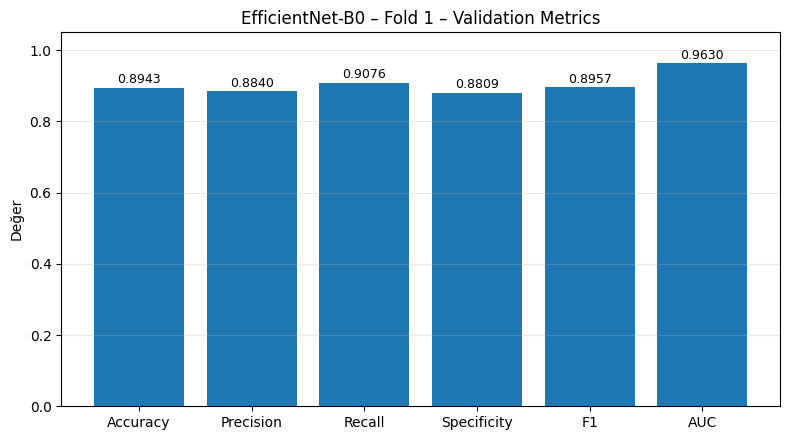

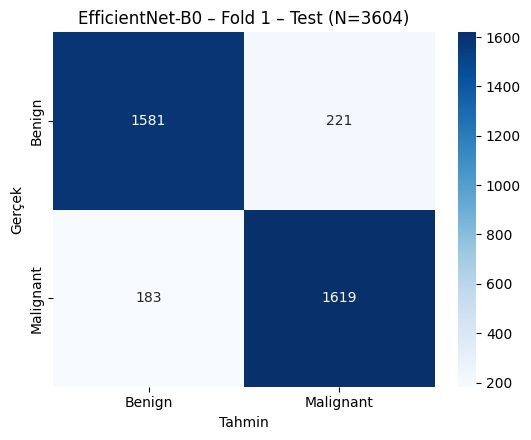

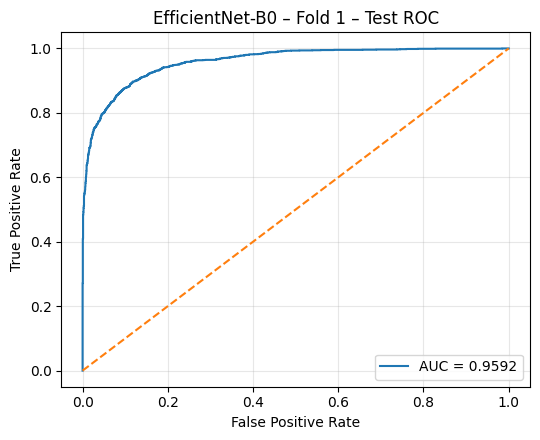

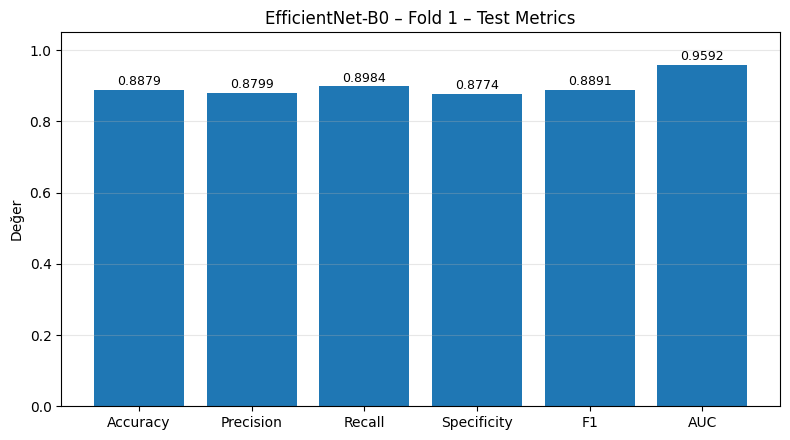

EfficientNet-B0 – Fold 1 sonuçları (best epoch = 10):


,N,TN,FP,FN,TP,Accuracy,Precision,Recall (Sensitivity),Specificity,F1-Score,ROC-AUC,Loss
Train,16826.0,7545.0,868.0,696.0,7717.0,0.907049,0.898893,0.917271,0.896826,0.907989,0.970100,0.239561
Validation,3594.0,1583.0,214.0,166.0,1631.0,0.894268,0.884011,0.907624,0.880913,0.895662,0.962964,0.259992
Test,3604.0,1581.0,221.0,183.0,1619.0,0.887902,0.879891,0.898446,0.877358,0.889072,0.959250,0.268174


✓ EfficientNet-B0 Fold 1: best epoch 10 | Test acc 0.8879
EfficientNet-B0 | Fold 2 | Epoch 01/10 | Train loss 0.4883 acc 0.7637 | Val loss 0.4134 acc 0.8200
EfficientNet-B0 | Fold 2 | Epoch 02/10 | Train loss 0.3814 acc 0.8354 | Val loss 0.3676 acc 0.8484
EfficientNet-B0 | Fold 2 | Epoch 03/10 | Train loss 0.3408 acc 0.8578 | Val loss 0.3515 acc 0.8478
EfficientNet-B0 | Fold 2 | Epoch 04/10 | Train loss 0.3154 acc 0.8694 | Val loss 0.3181 acc 0.8740
EfficientNet-B0 | Fold 2 | Epoch 05/10 | Train loss 0.2945 acc 0.8808 | Val loss 0.3063 acc 0.8715
EfficientNet-B0 | Fold 2 | Epoch 06/10 | Train loss 0.2801 acc 0.8844 | Val loss 0.2950 acc 0.8784
EfficientNet-B0 | Fold 2 | Epoch 07/10 | Train loss 0.2694 acc 0.8884 | Val loss 0.2869 acc 0.8843
EfficientNet-B0 | Fold 2 | Epoch 08/10 | Train loss 0.2591 acc 0.8979 | Val loss 0.2775 acc 0.8876
EfficientNet-B0 | Fold 2 | Epoch 09/10 | Train loss 0.2518 acc 0.9016 | Val loss 0.2705 acc 0.8895
EfficientNet-B0 | Fold 2 | Epoch 10/10 | Train loss

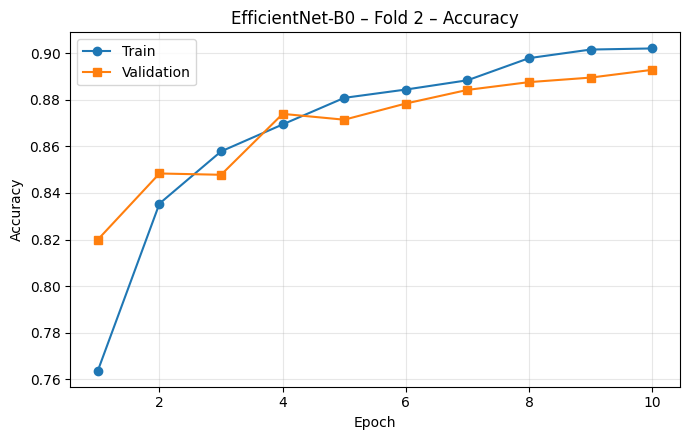

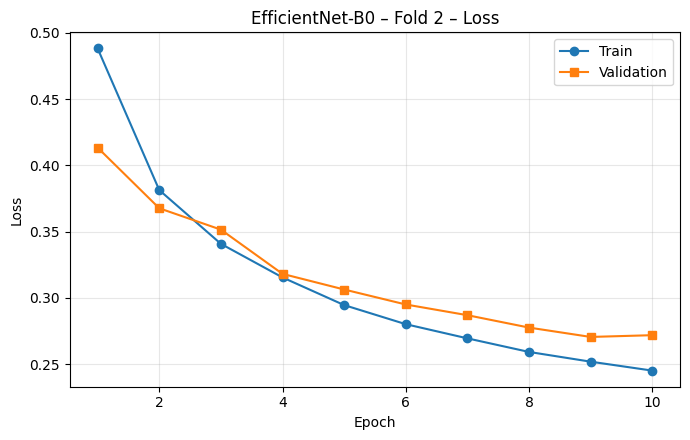

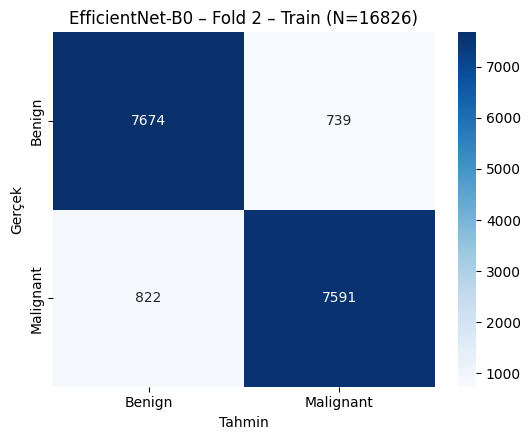

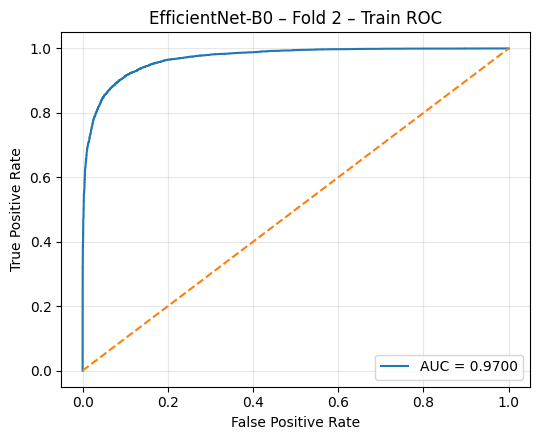

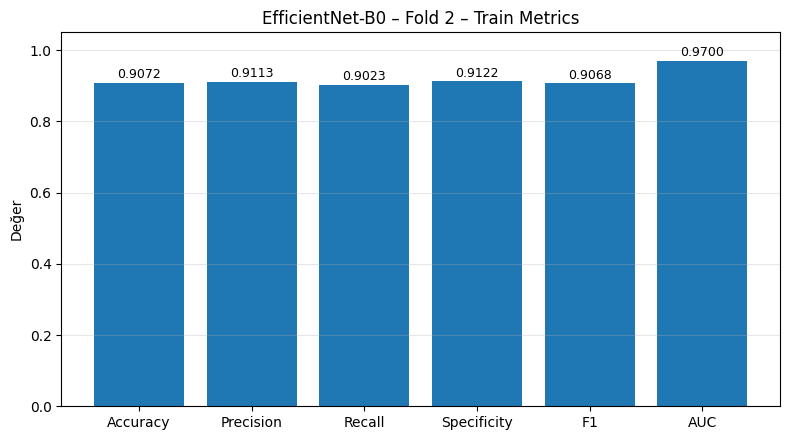

...

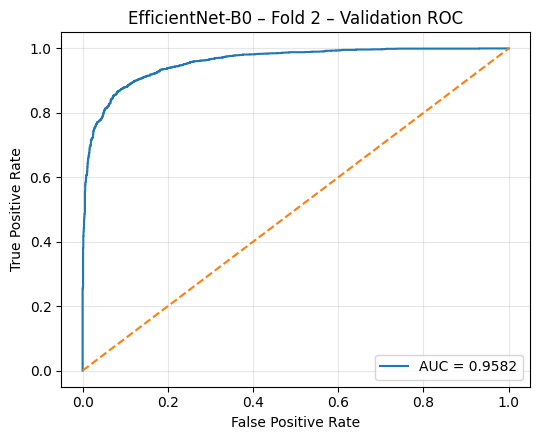

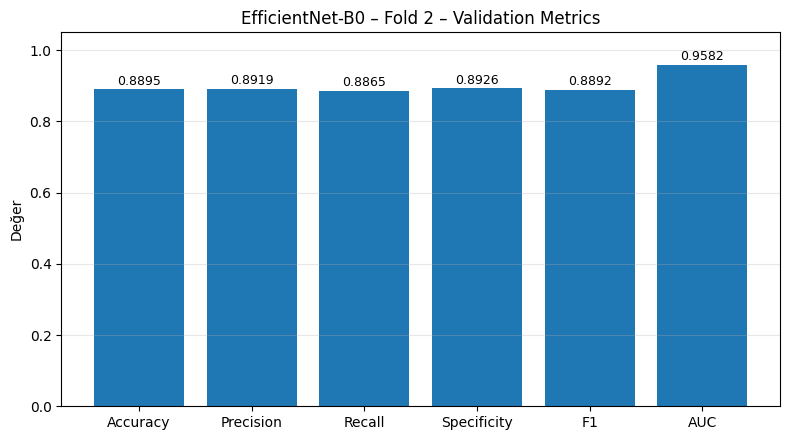

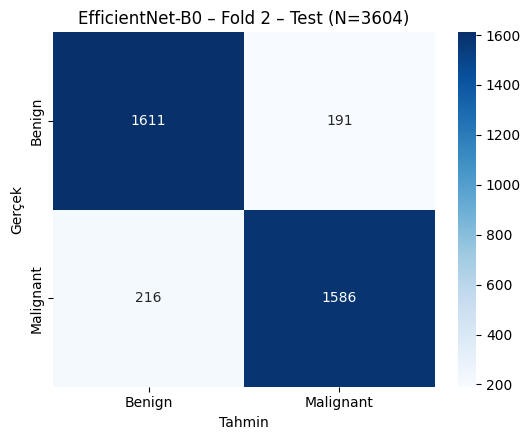

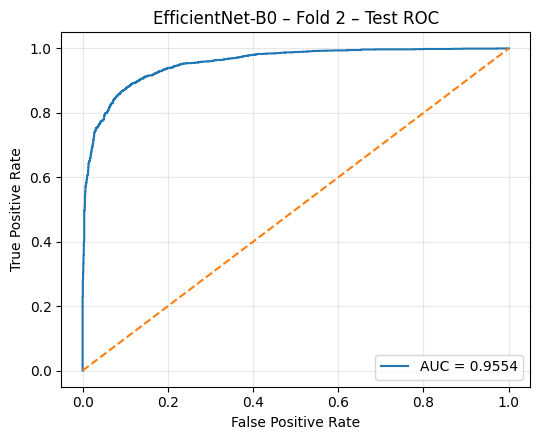

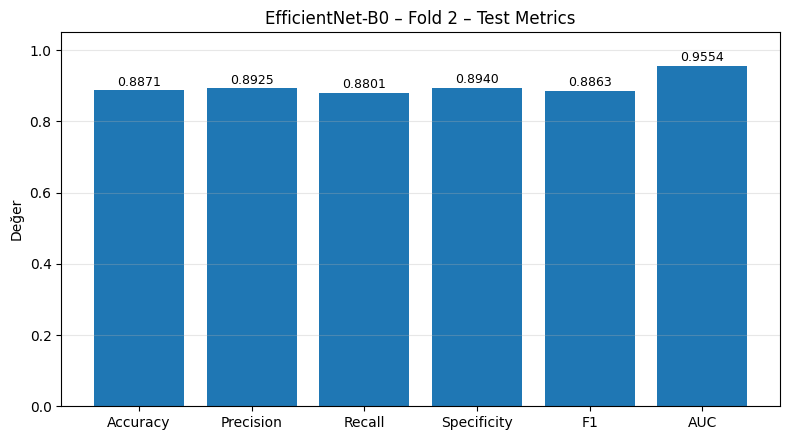

EfficientNet-B0 – Fold 2 sonuçları (best epoch = 9):


,N,TN,FP,FN,TP,Accuracy,Precision,Recall (Sensitivity),Specificity,F1-Score,ROC-AUC,Loss
Train,16826.0,7674.0,739.0,822.0,7591.0,0.907227,0.911285,0.902294,0.912160,0.906767,0.969980,0.239887
Validation,3594.0,1604.0,193.0,204.0,1593.0,0.889538,0.891937,0.886477,0.892599,0.889199,0.958217,0.270458
Test,3604.0,1611.0,191.0,216.0,1586.0,0.887070,0.892515,0.880133,0.894007,0.886281,0.955408,0.277089


✓ EfficientNet-B0 Fold 2: best epoch 9 | Test acc 0.8871
EfficientNet-B0 | Fold 3 | Epoch 01/10 | Train loss 0.4877 acc 0.7648 | Val loss 0.4150 acc 0.8155
EfficientNet-B0 | Fold 3 | Epoch 02/10 | Train loss 0.3837 acc 0.8325 | Val loss 0.3574 acc 0.8378
EfficientNet-B0 | Fold 3 | Epoch 03/10 | Train loss 0.3426 acc 0.8562 | Val loss 0.3334 acc 0.8589
EfficientNet-B0 | Fold 3 | Epoch 04/10 | Train loss 0.3173 acc 0.8683 | Val loss 0.3125 acc 0.8673
EfficientNet-B0 | Fold 3 | Epoch 05/10 | Train loss 0.2977 acc 0.8786 | Val loss 0.2984 acc 0.8731
EfficientNet-B0 | Fold 3 | Epoch 06/10 | Train loss 0.2830 acc 0.8871 | Val loss 0.2866 acc 0.8781
EfficientNet-B0 | Fold 3 | Epoch 07/10 | Train loss 0.2711 acc 0.8927 | Val loss 0.2785 acc 0.8840
EfficientNet-B0 | Fold 3 | Epoch 08/10 | Train loss 0.2626 acc 0.8953 | Val loss 0.2666 acc 0.8884
EfficientNet-B0 | Fold 3 | Epoch 09/10 | Train loss 0.2540 acc 0.9000 | Val loss 0.2588 acc 0.8920
EfficientNet-B0 | Fold 3 | Epoch 10/10 | Train loss 

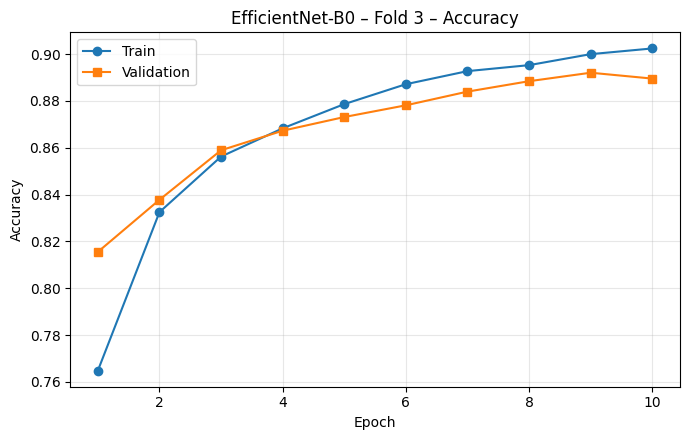

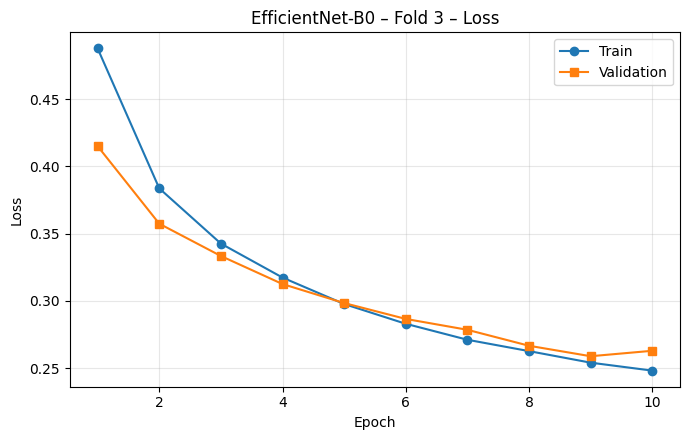

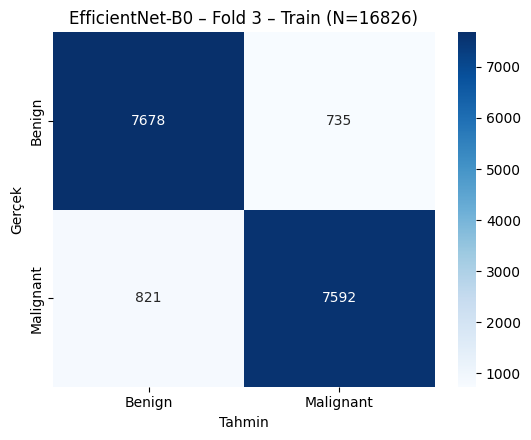

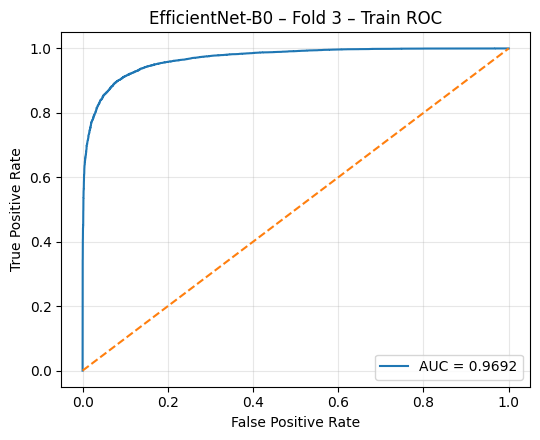

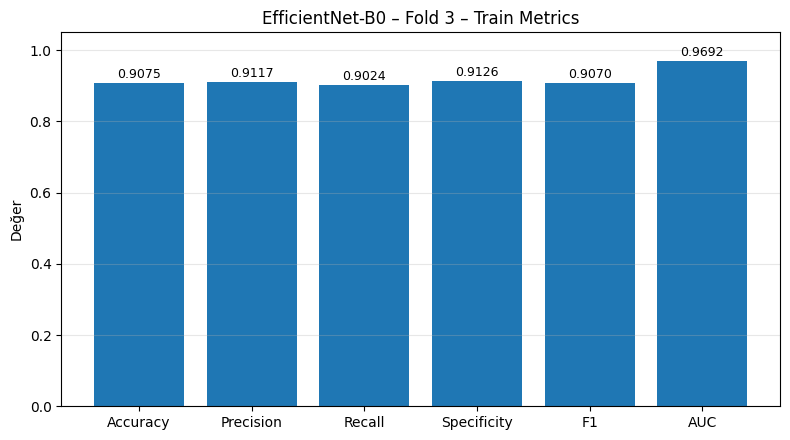

...

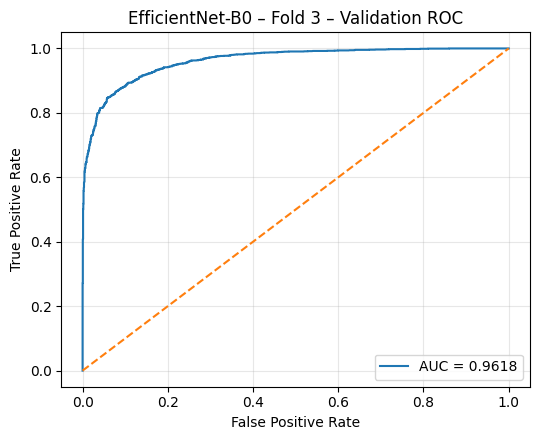

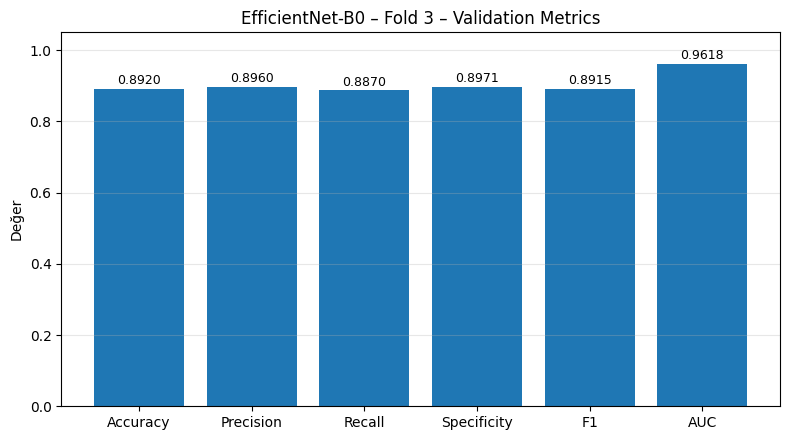

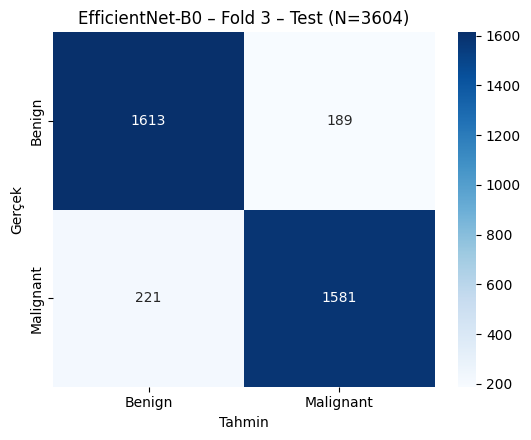

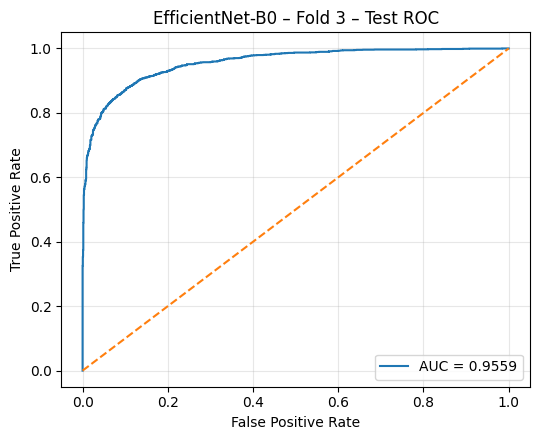

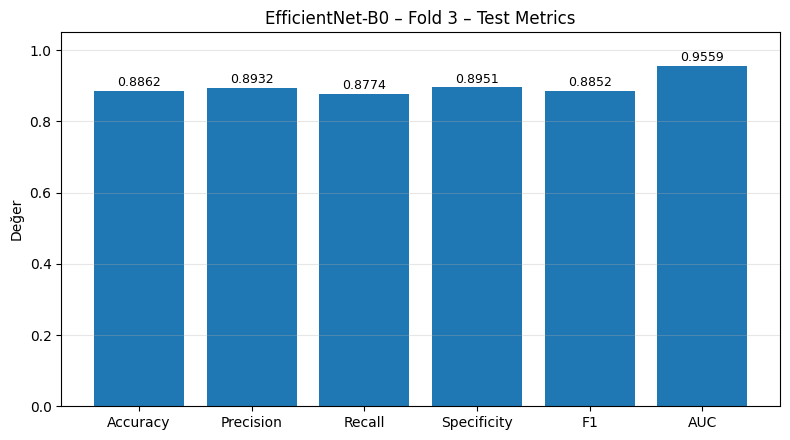

EfficientNet-B0 – Fold 3 sonuçları (best epoch = 9):


,N,TN,FP,FN,TP,Accuracy,Precision,Recall (Sensitivity),Specificity,F1-Score,ROC-AUC,Loss
Train,16826.0,7678.0,735.0,821.0,7592.0,0.907524,0.911733,0.902413,0.912635,0.907049,0.969173,0.242667
Validation,3594.0,1612.0,185.0,203.0,1594.0,0.892042,0.896009,0.887034,0.897051,0.891499,0.961821,0.258837
Test,3604.0,1613.0,189.0,221.0,1581.0,0.886238,0.893220,0.877358,0.895117,0.885218,0.955930,0.275185


✓ EfficientNet-B0 Fold 3: best epoch 9 | Test acc 0.8862
EfficientNet-B0 | Fold 4 | Epoch 01/10 | Train loss 0.4867 acc 0.7657 | Val loss 0.4229 acc 0.8036
EfficientNet-B0 | Fold 4 | Epoch 02/10 | Train loss 0.3790 acc 0.8366 | Val loss 0.3738 acc 0.8364
EfficientNet-B0 | Fold 4 | Epoch 03/10 | Train loss 0.3391 acc 0.8561 | Val loss 0.3555 acc 0.8389
EfficientNet-B0 | Fold 4 | Epoch 04/10 | Train loss 0.3152 acc 0.8682 | Val loss 0.3201 acc 0.8662
EfficientNet-B0 | Fold 4 | Epoch 05/10 | Train loss 0.2949 acc 0.8792 | Val loss 0.3080 acc 0.8715
EfficientNet-B0 | Fold 4 | Epoch 06/10 | Train loss 0.2813 acc 0.8879 | Val loss 0.2984 acc 0.8723
EfficientNet-B0 | Fold 4 | Epoch 07/10 | Train loss 0.2688 acc 0.8947 | Val loss 0.2976 acc 0.8767
EfficientNet-B0 | Fold 4 | Epoch 08/10 | Train loss 0.2598 acc 0.8959 | Val loss 0.2778 acc 0.8868
EfficientNet-B0 | Fold 4 | Epoch 09/10 | Train loss 0.2533 acc 0.9007 | Val loss 0.2730 acc 0.8876
EfficientNet-B0 | Fold 4 | Epoch 10/10 | Train loss 

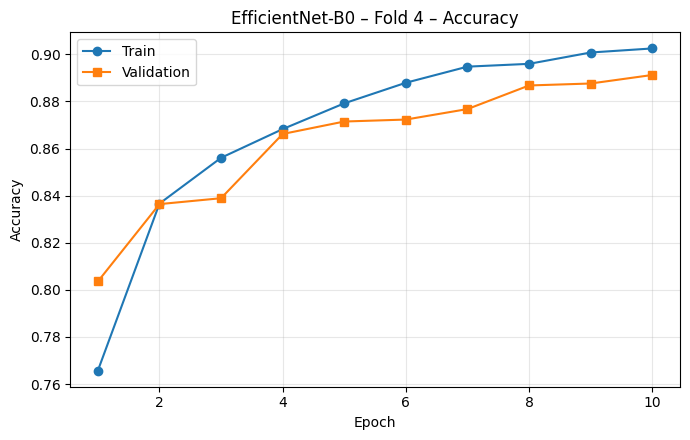

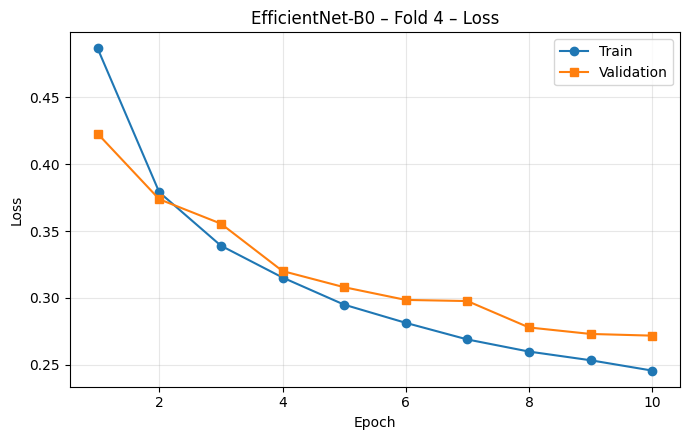

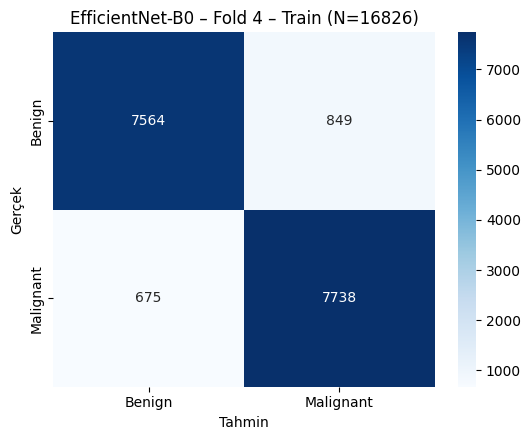

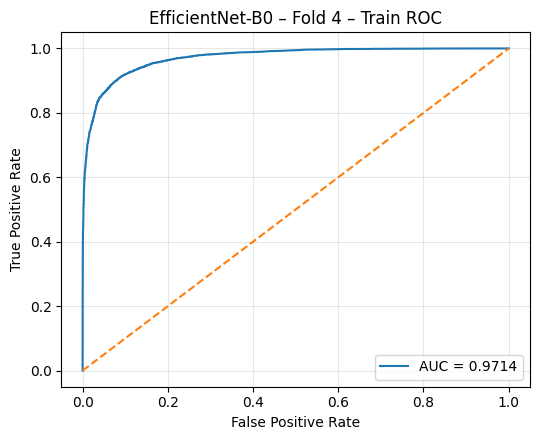

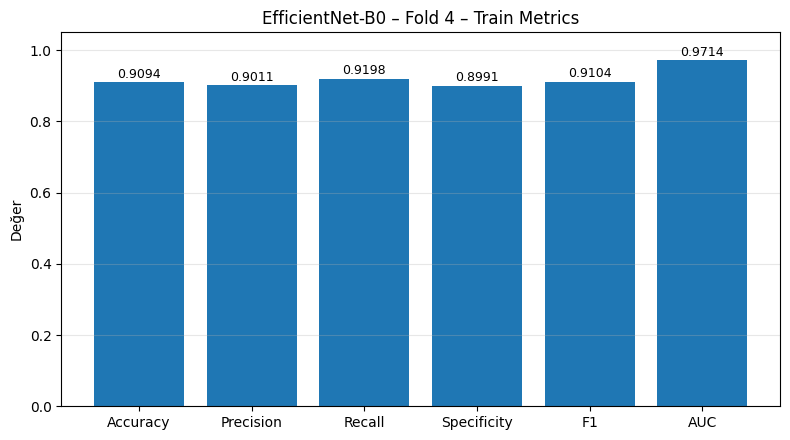

...

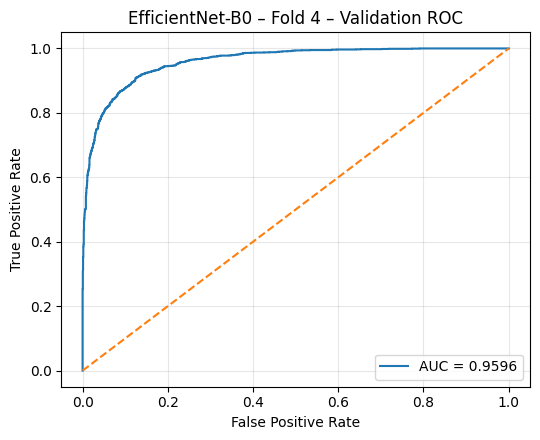

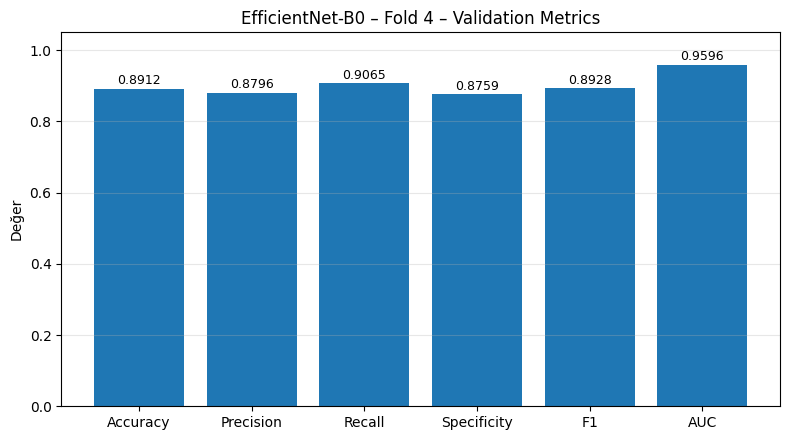

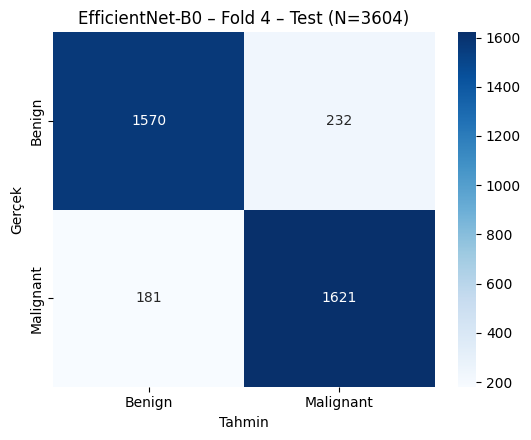

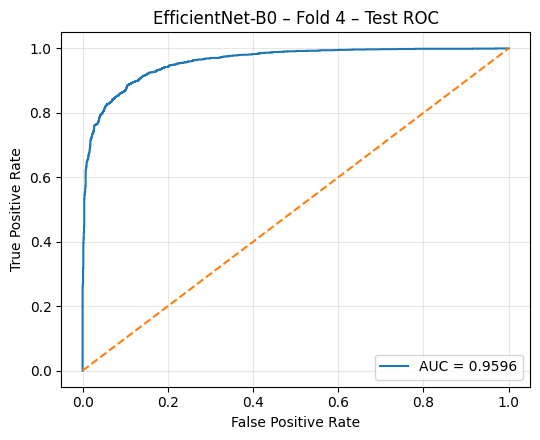

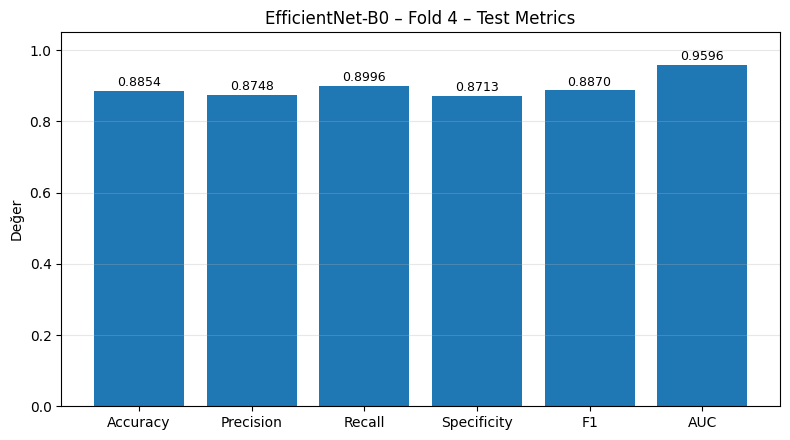

EfficientNet-B0 – Fold 4 sonuçları (best epoch = 10):


,N,TN,FP,FN,TP,Accuracy,Precision,Recall (Sensitivity),Specificity,F1-Score,ROC-AUC,Loss
Train,16826.0,7564.0,849.0,675.0,7738.0,0.909426,0.901130,0.919767,0.899085,0.910353,0.971386,0.236440
Validation,3594.0,1574.0,223.0,168.0,1629.0,0.891208,0.879590,0.906511,0.875904,0.892847,0.959595,0.271690
Test,3604.0,1570.0,232.0,181.0,1621.0,0.885405,0.874798,0.899556,0.871254,0.887004,0.959616,0.268558


✓ EfficientNet-B0 Fold 4: best epoch 10 | Test acc 0.8854
EfficientNet-B0 | Fold 5 | Epoch 01/10 | Train loss 0.4875 acc 0.7664 | Val loss 0.4067 acc 0.8200
EfficientNet-B0 | Fold 5 | Epoch 02/10 | Train loss 0.3809 acc 0.8367 | Val loss 0.3507 acc 0.8553
EfficientNet-B0 | Fold 5 | Epoch 03/10 | Train loss 0.3406 acc 0.8578 | Val loss 0.3266 acc 0.8612
EfficientNet-B0 | Fold 5 | Epoch 04/10 | Train loss 0.3160 acc 0.8701 | Val loss 0.3114 acc 0.8703
EfficientNet-B0 | Fold 5 | Epoch 05/10 | Train loss 0.2952 acc 0.8802 | Val loss 0.2963 acc 0.8748
EfficientNet-B0 | Fold 5 | Epoch 06/10 | Train loss 0.2802 acc 0.8884 | Val loss 0.2855 acc 0.8787
EfficientNet-B0 | Fold 5 | Epoch 07/10 | Train loss 0.2701 acc 0.8914 | Val loss 0.2805 acc 0.8812
EfficientNet-B0 | Fold 5 | Epoch 08/10 | Train loss 0.2610 acc 0.8959 | Val loss 0.2714 acc 0.8829
EfficientNet-B0 | Fold 5 | Epoch 09/10 | Train loss 0.2520 acc 0.9011 | Val loss 0.2702 acc 0.8884
EfficientNet-B0 | Fold 5 | Epoch 10/10 | Train loss

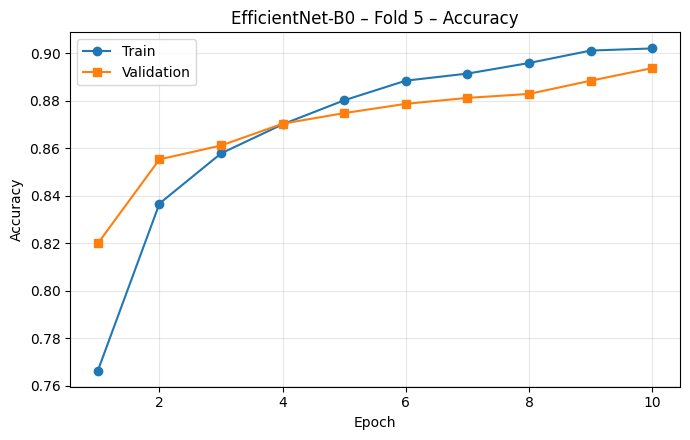

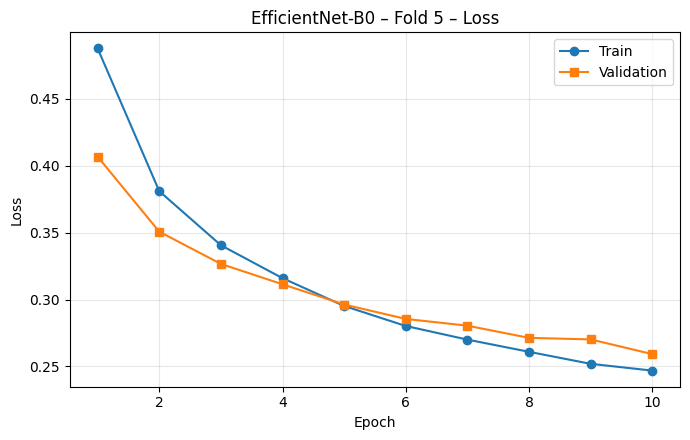

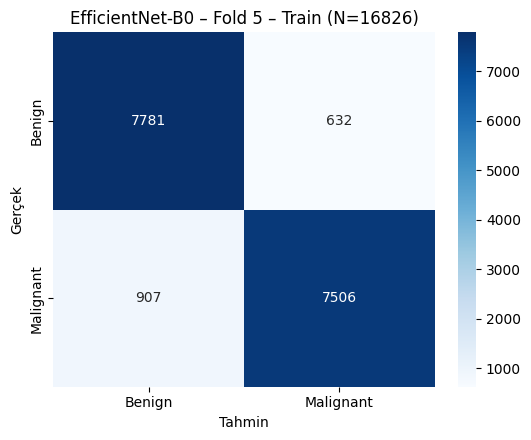

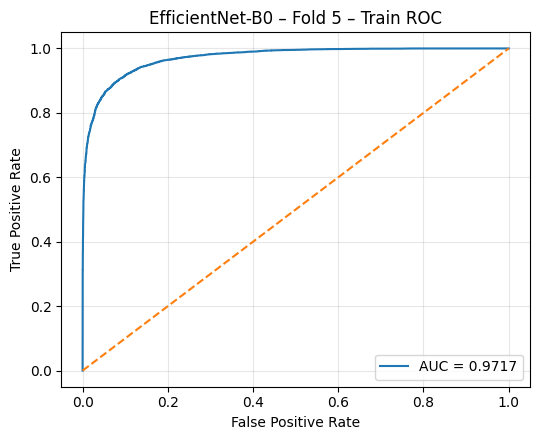

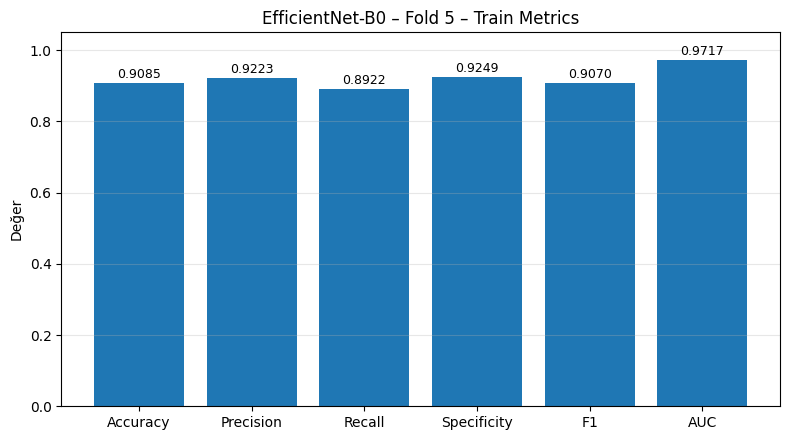

...

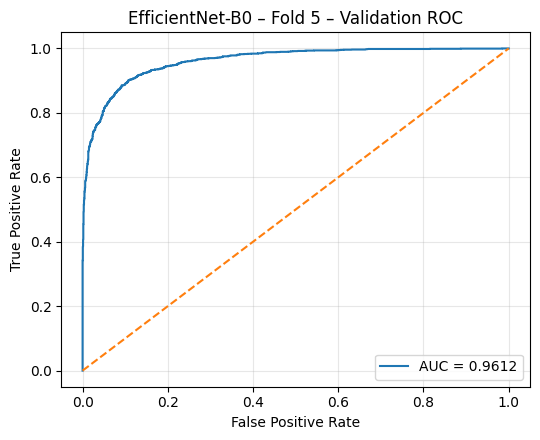

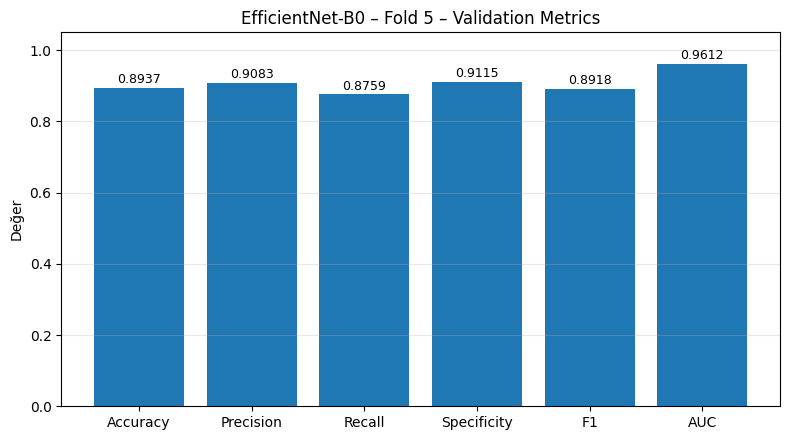

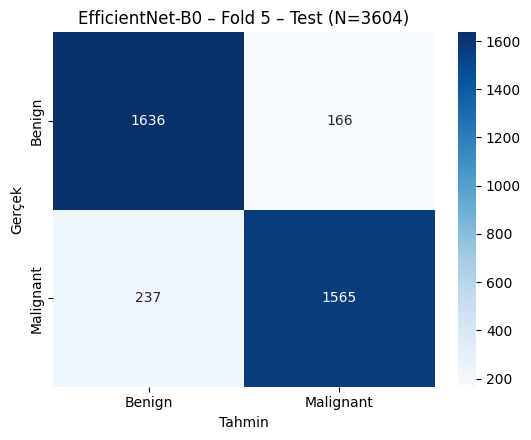

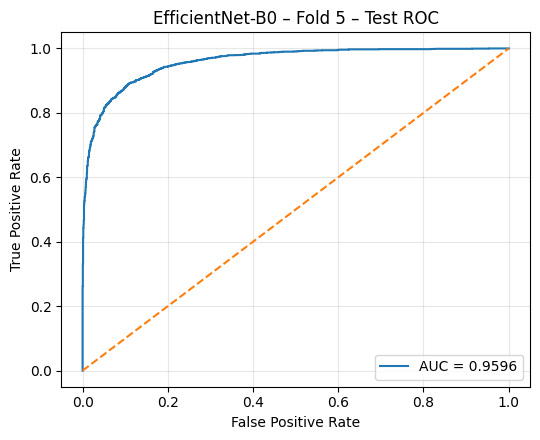

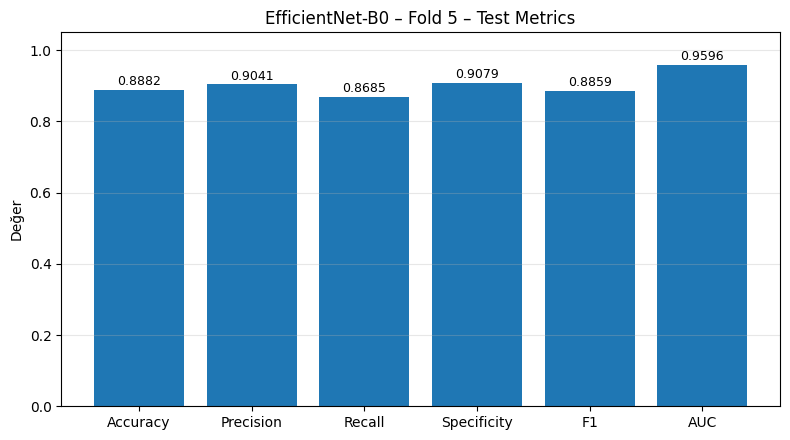

EfficientNet-B0 – Fold 5 sonuçları (best epoch = 10):


,N,TN,FP,FN,TP,Accuracy,Precision,Recall (Sensitivity),Specificity,F1-Score,ROC-AUC,Loss
Train,16826.0,7781.0,632.0,907.0,7506.0,0.908534,0.922340,0.892191,0.924878,0.907015,0.971676,0.233441
Validation,3594.0,1638.0,159.0,223.0,1574.0,0.893712,0.908252,0.875904,0.911519,0.891785,0.961202,0.259237
Test,3604.0,1636.0,166.0,237.0,1565.0,0.888180,0.904102,0.868479,0.907880,0.885933,0.959567,0.264907


✓ EfficientNet-B0 Fold 5: best epoch 10 | Test acc 0.8882
Downloading: "https://download.pytorch.org/models/mobilenet_v2-b0353104.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-b0353104.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 191MB/s]


MobileNetV2 | Fold 1 | Epoch 01/10 | Train loss 0.5106 acc 0.7431 | Val loss 0.4479 acc 0.7969
MobileNetV2 | Fold 1 | Epoch 02/10 | Train loss 0.4164 acc 0.8100 | Val loss 0.4016 acc 0.8194
MobileNetV2 | Fold 1 | Epoch 03/10 | Train loss 0.3787 acc 0.8304 | Val loss 0.3718 acc 0.8344
MobileNetV2 | Fold 1 | Epoch 04/10 | Train loss 0.3570 acc 0.8458 | Val loss 0.3480 acc 0.8486
MobileNetV2 | Fold 1 | Epoch 05/10 | Train loss 0.3393 acc 0.8529 | Val loss 0.3402 acc 0.8548
MobileNetV2 | Fold 1 | Epoch 06/10 | Train loss 0.3250 acc 0.8615 | Val loss 0.3246 acc 0.8550
MobileNetV2 | Fold 1 | Epoch 07/10 | Train loss 0.3190 acc 0.8624 | Val loss 0.3250 acc 0.8553
MobileNetV2 | Fold 1 | Epoch 08/10 | Train loss 0.3044 acc 0.8723 | Val loss 0.3134 acc 0.8620
MobileNetV2 | Fold 1 | Epoch 09/10 | Train loss 0.2968 acc 0.8731 | Val loss 0.3023 acc 0.8684
MobileNetV2 | Fold 1 | Epoch 10/10 | Train loss 0.2934 acc 0.8755 | Val loss 0.3007 acc 0.8709


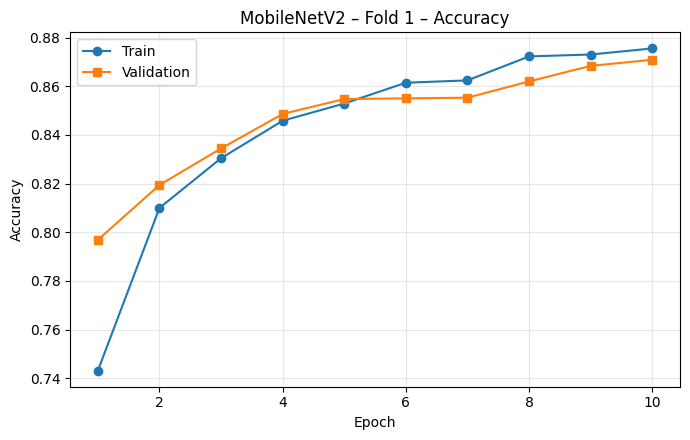

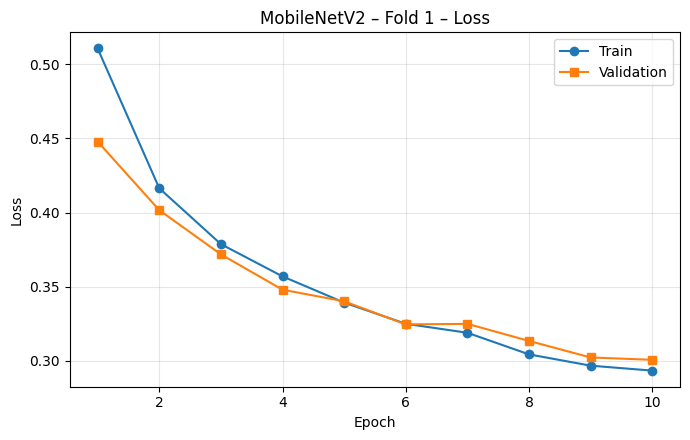

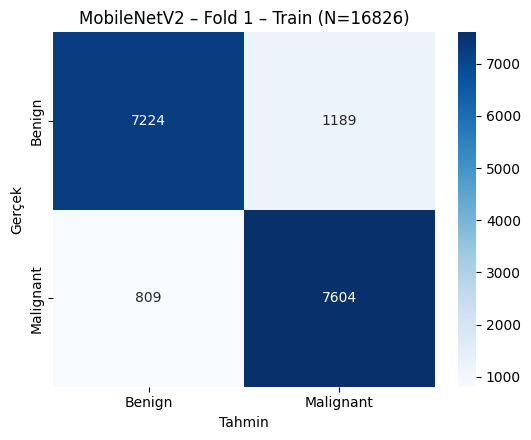

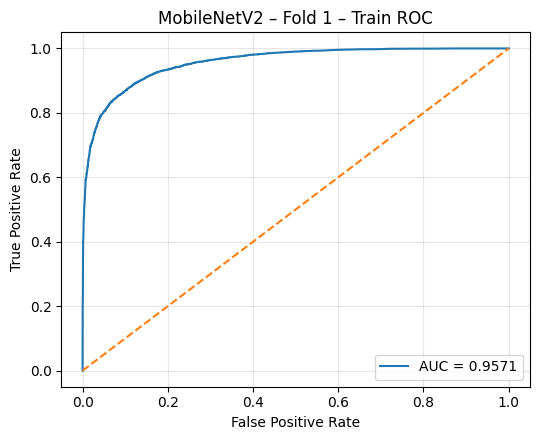

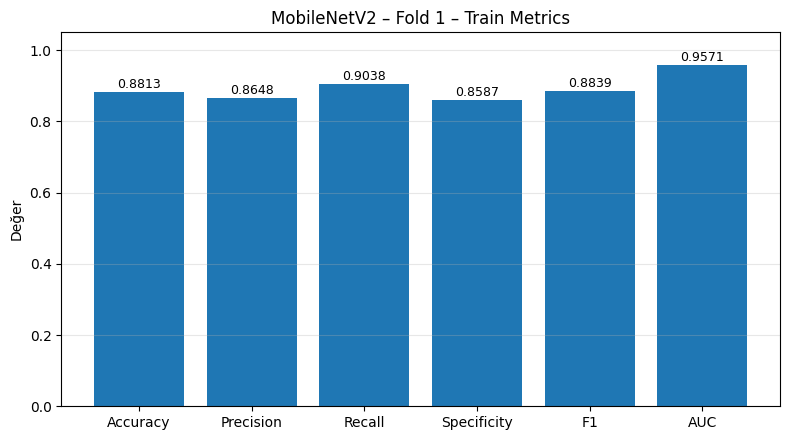

...

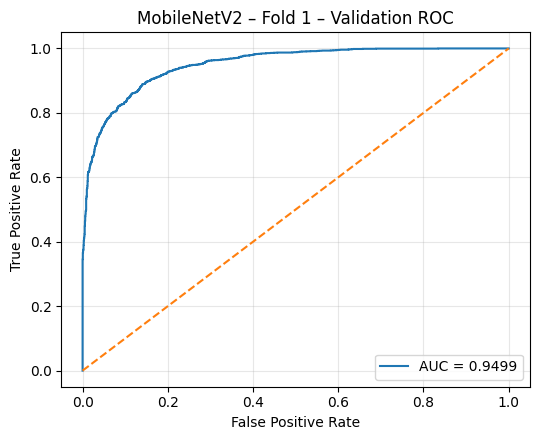

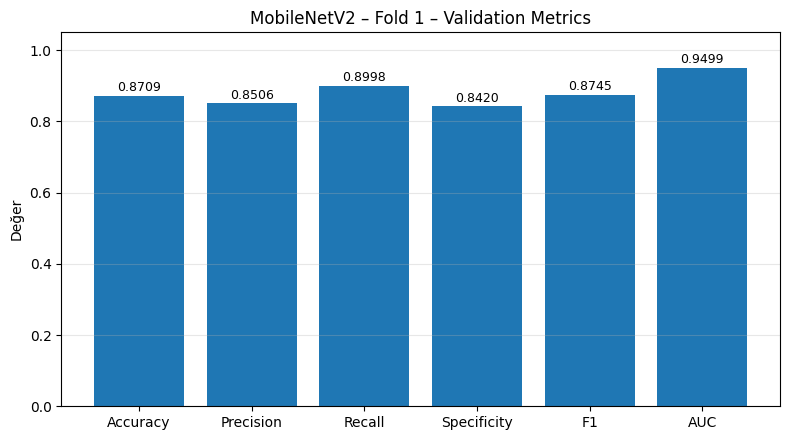

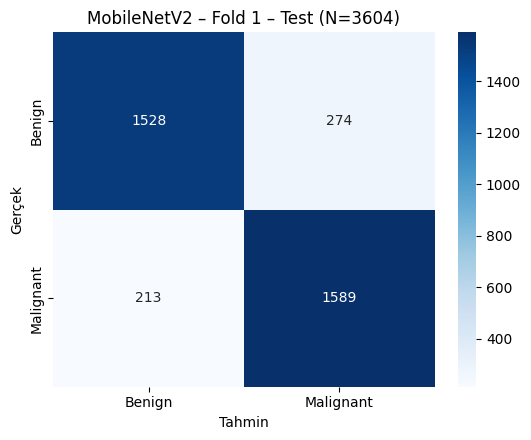

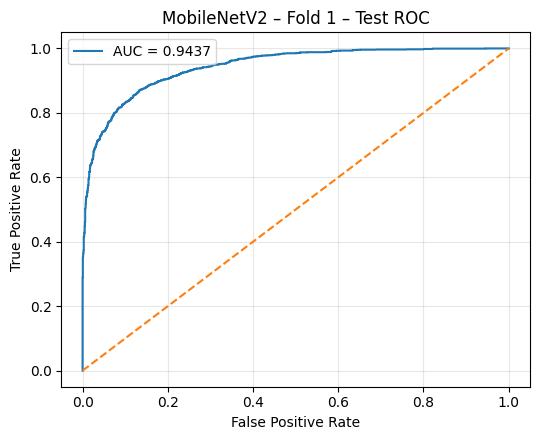

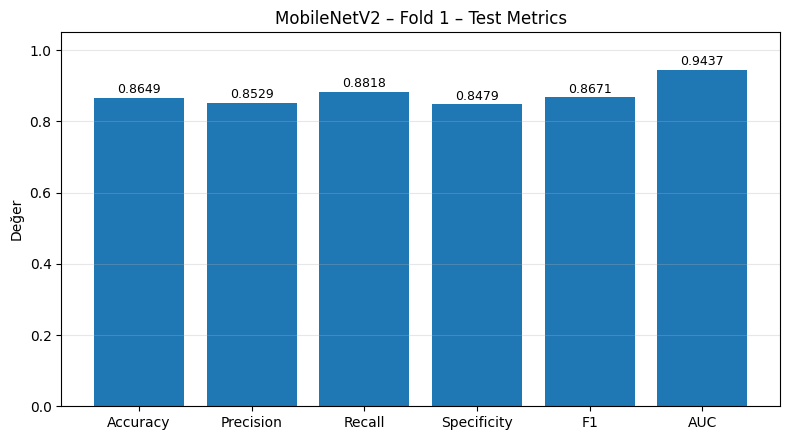

MobileNetV2 – Fold 1 sonuçları (best epoch = 10):


,N,TN,FP,FN,TP,Accuracy,Precision,Recall (Sensitivity),Specificity,F1-Score,ROC-AUC,Loss
Train,16826.0,7224.0,1189.0,809.0,7604.0,0.881255,0.864779,0.903839,0.858671,0.883878,0.957111,0.283128
Validation,3594.0,1513.0,284.0,180.0,1617.0,0.870896,0.850605,0.899833,0.841959,0.874527,0.949926,0.300715
Test,3604.0,1528.0,274.0,213.0,1589.0,0.864872,0.852925,0.881798,0.847947,0.867121,0.943658,0.309995


✓ MobileNetV2 Fold 1: best epoch 10 | Test acc 0.8649
MobileNetV2 | Fold 2 | Epoch 01/10 | Train loss 0.5081 acc 0.7457 | Val loss 0.4351 acc 0.8066
MobileNetV2 | Fold 2 | Epoch 02/10 | Train loss 0.4130 acc 0.8143 | Val loss 0.3917 acc 0.8275
MobileNetV2 | Fold 2 | Epoch 03/10 | Train loss 0.3765 acc 0.8329 | Val loss 0.3767 acc 0.8311
MobileNetV2 | Fold 2 | Epoch 04/10 | Train loss 0.3538 acc 0.8471 | Val loss 0.3860 acc 0.8214
MobileNetV2 | Fold 2 | Epoch 05/10 | Train loss 0.3383 acc 0.8553 | Val loss 0.3602 acc 0.8367
MobileNetV2 | Fold 2 | Epoch 06/10 | Train loss 0.3248 acc 0.8591 | Val loss 0.3528 acc 0.8436
MobileNetV2 | Fold 2 | Epoch 07/10 | Train loss 0.3137 acc 0.8660 | Val loss 0.3268 acc 0.8589
MobileNetV2 | Fold 2 | Epoch 08/10 | Train loss 0.3013 acc 0.8736 | Val loss 0.3155 acc 0.8623
MobileNetV2 | Fold 2 | Epoch 09/10 | Train loss 0.2950 acc 0.8761 | Val loss 0.3118 acc 0.8651
MobileNetV2 | Fold 2 | Epoch 10/10 | Train loss 0.2876 acc 0.8792 | Val loss 0.3041 acc 0.8

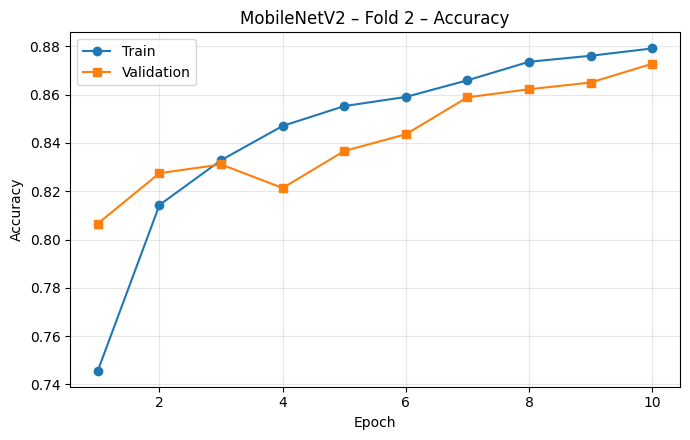

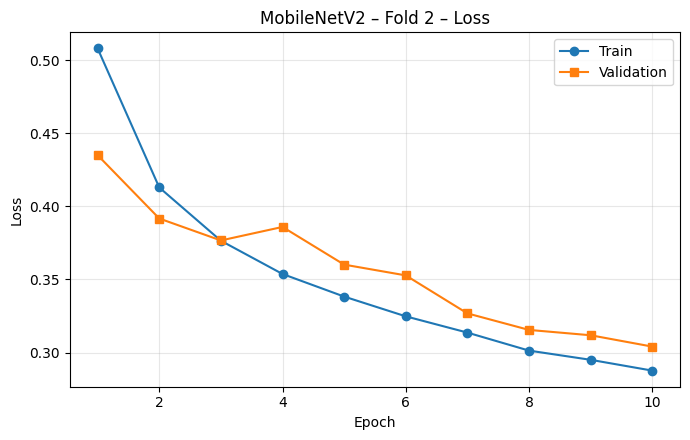

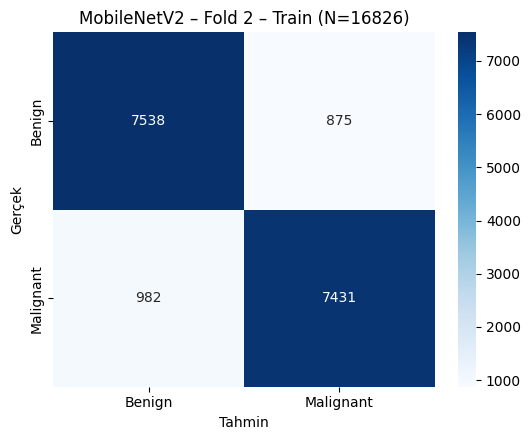

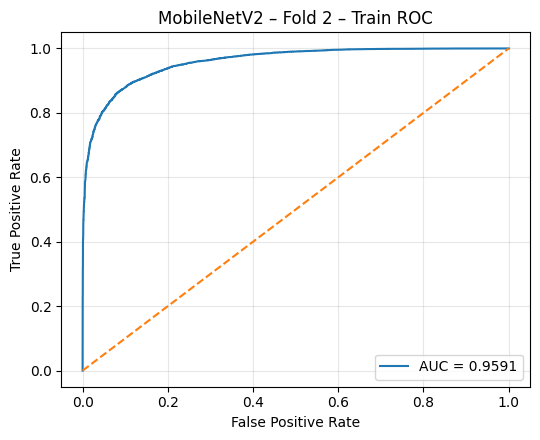

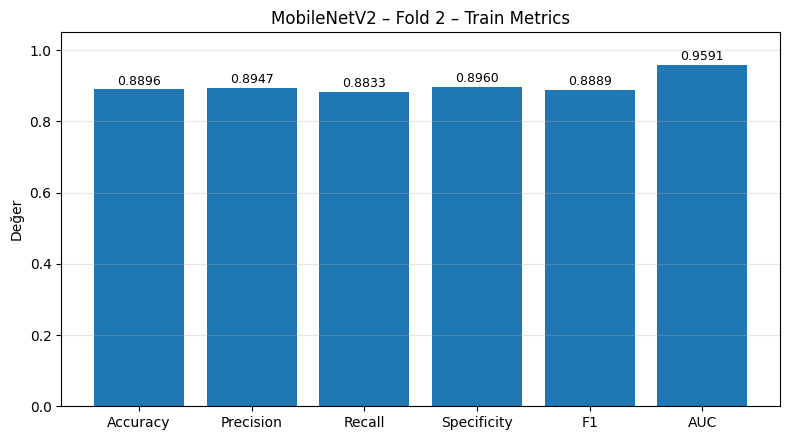

...

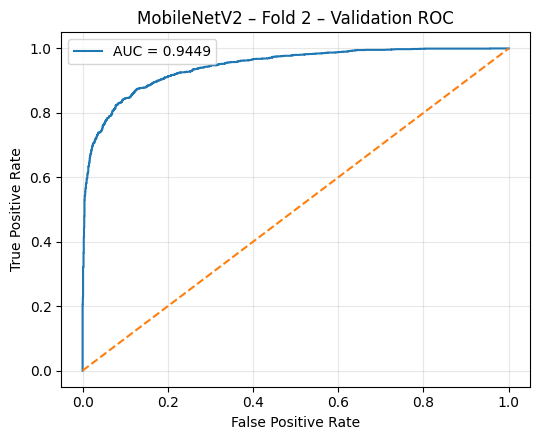

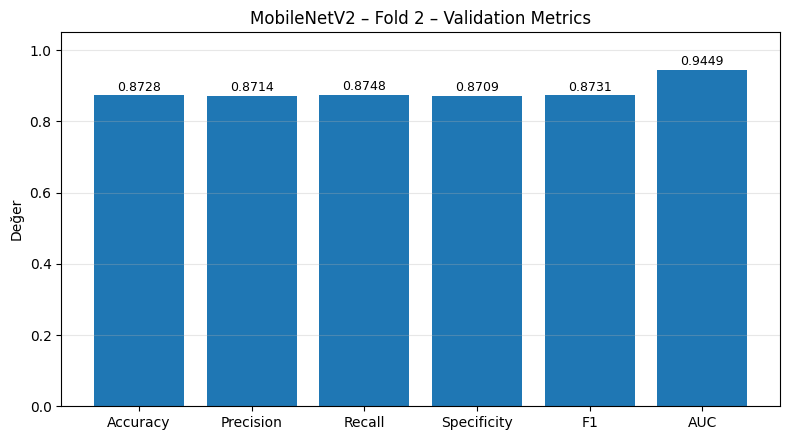

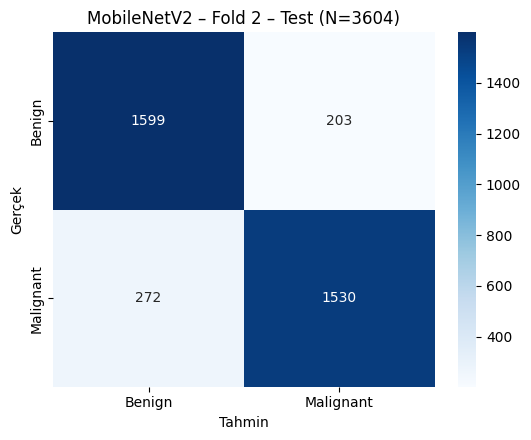

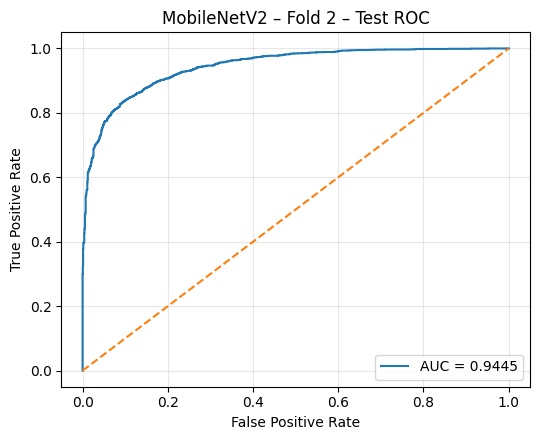

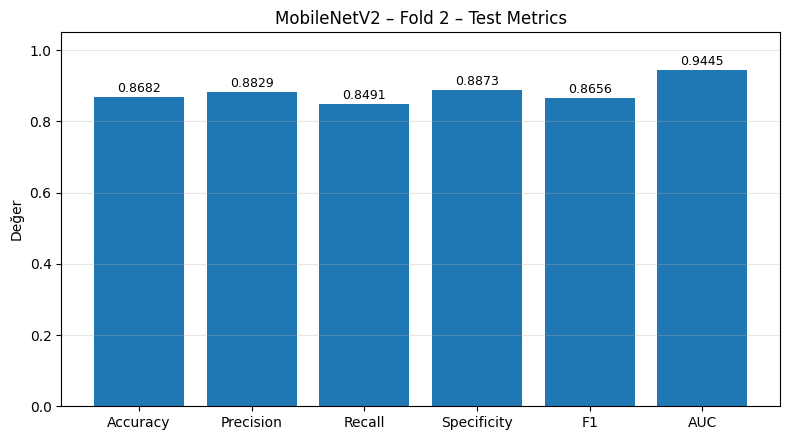

MobileNetV2 – Fold 2 sonuçları (best epoch = 10):


,N,TN,FP,FN,TP,Accuracy,Precision,Recall (Sensitivity),Specificity,F1-Score,ROC-AUC,Loss
Train,16826.0,7538.0,875.0,982.0,7431.0,0.889635,0.894654,0.883276,0.895994,0.888929,0.959116,0.273554
Validation,3594.0,1565.0,232.0,225.0,1572.0,0.872844,0.871397,0.874791,0.870896,0.873091,0.944931,0.304066
Test,3604.0,1599.0,203.0,272.0,1530.0,0.868202,0.882862,0.849057,0.887347,0.865629,0.944526,0.305735


✓ MobileNetV2 Fold 2: best epoch 10 | Test acc 0.8682
MobileNetV2 | Fold 3 | Epoch 01/10 | Train loss 0.5083 acc 0.7499 | Val loss 0.4503 acc 0.7835
MobileNetV2 | Fold 3 | Epoch 02/10 | Train loss 0.4128 acc 0.8126 | Val loss 0.4006 acc 0.8233
MobileNetV2 | Fold 3 | Epoch 03/10 | Train loss 0.3783 acc 0.8320 | Val loss 0.4046 acc 0.8119
MobileNetV2 | Fold 3 | Epoch 04/10 | Train loss 0.3549 acc 0.8450 | Val loss 0.3545 acc 0.8408
MobileNetV2 | Fold 3 | Epoch 05/10 | Train loss 0.3378 acc 0.8551 | Val loss 0.3411 acc 0.8489
MobileNetV2 | Fold 3 | Epoch 06/10 | Train loss 0.3237 acc 0.8610 | Val loss 0.3332 acc 0.8525
MobileNetV2 | Fold 3 | Epoch 07/10 | Train loss 0.3138 acc 0.8659 | Val loss 0.3392 acc 0.8450
MobileNetV2 | Fold 3 | Epoch 08/10 | Train loss 0.3028 acc 0.8710 | Val loss 0.3150 acc 0.8609
MobileNetV2 | Fold 3 | Epoch 09/10 | Train loss 0.2959 acc 0.8748 | Val loss 0.3151 acc 0.8620
MobileNetV2 | Fold 3 | Epoch 10/10 | Train loss 0.2895 acc 0.8772 | Val loss 0.3049 acc 0.8

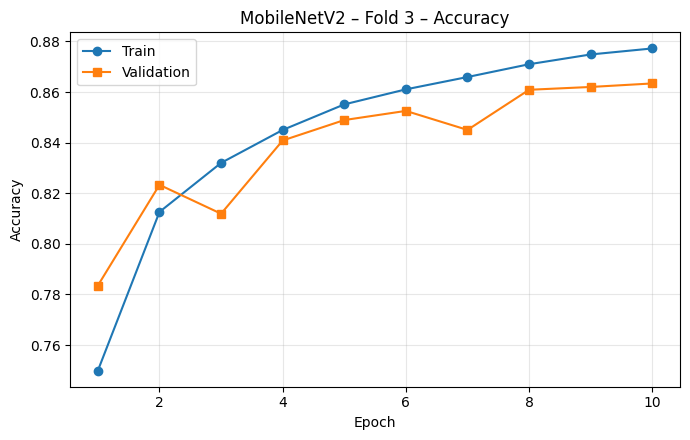

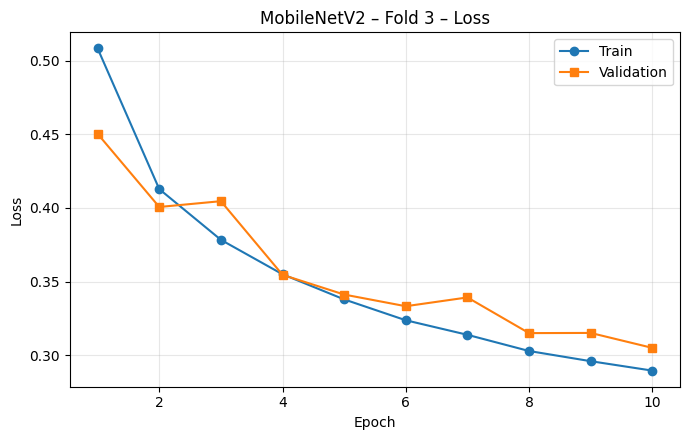

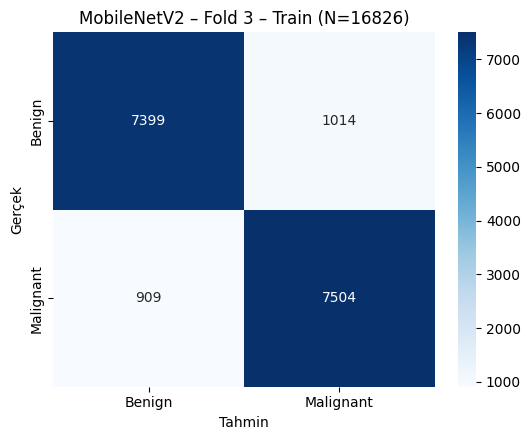

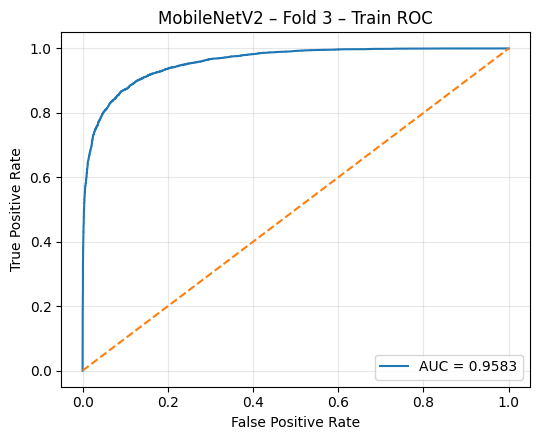

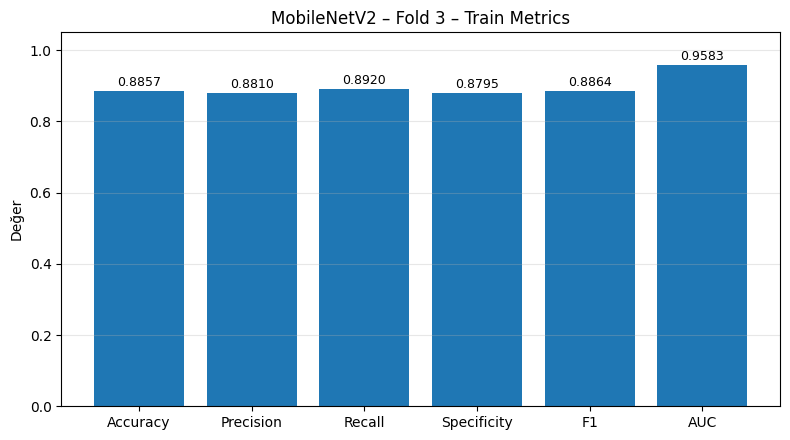

...

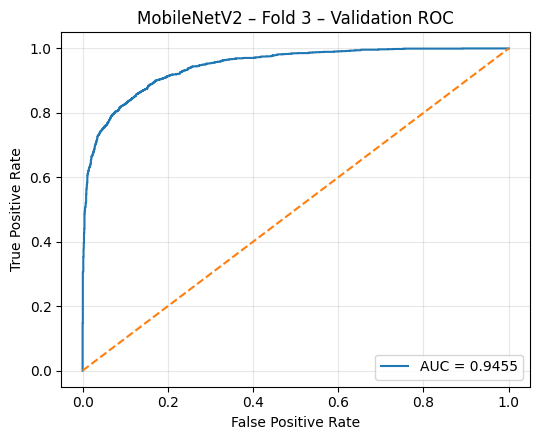

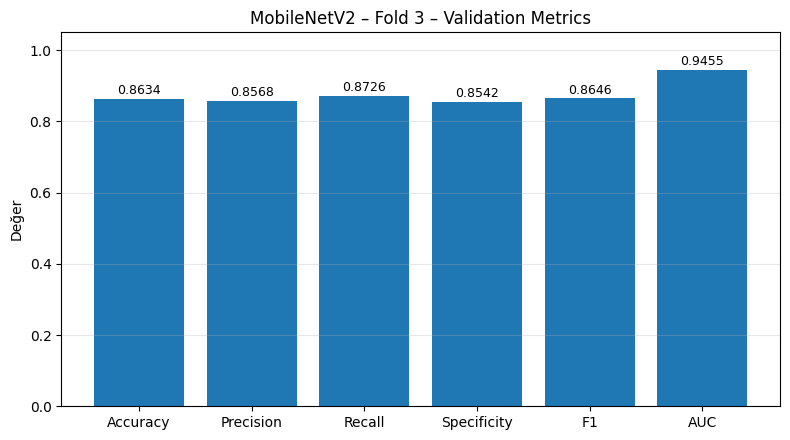

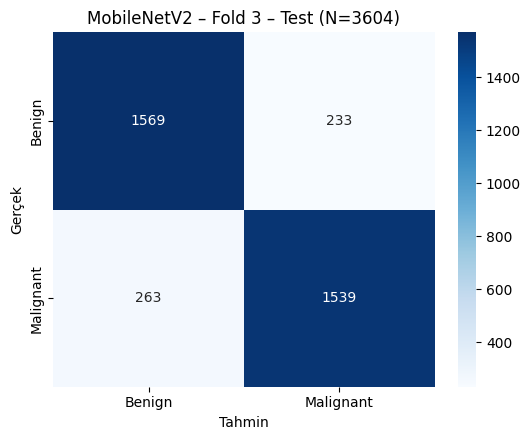

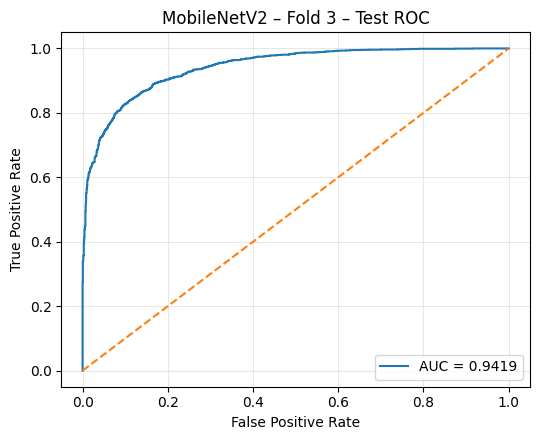

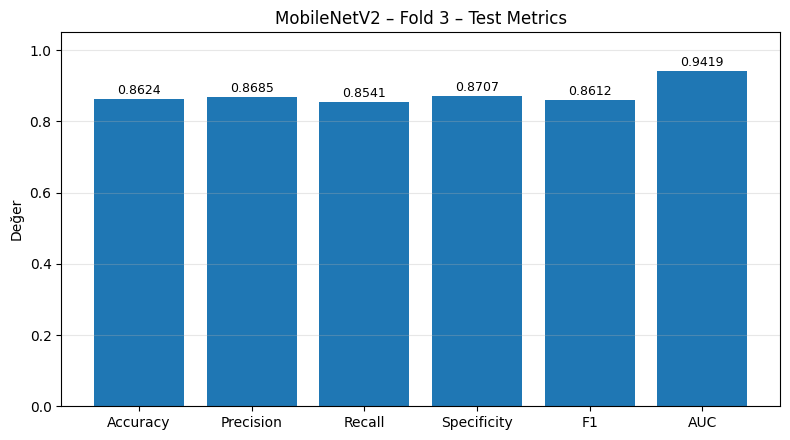

MobileNetV2 – Fold 3 sonuçları (best epoch = 10):


,N,TN,FP,FN,TP,Accuracy,Precision,Recall (Sensitivity),Specificity,F1-Score,ROC-AUC,Loss
Train,16826.0,7399.0,1014.0,909.0,7504.0,0.885713,0.880958,0.891953,0.879472,0.886421,0.958339,0.276056
Validation,3594.0,1535.0,262.0,229.0,1568.0,0.863383,0.856831,0.872565,0.854201,0.864626,0.945454,0.304923
Test,3604.0,1569.0,233.0,263.0,1539.0,0.862375,0.868510,0.854051,0.870699,0.861220,0.941852,0.310928


✓ MobileNetV2 Fold 3: best epoch 10 | Test acc 0.8624
MobileNetV2 | Fold 4 | Epoch 01/10 | Train loss 0.5083 acc 0.7521 | Val loss 0.4426 acc 0.7997
MobileNetV2 | Fold 4 | Epoch 02/10 | Train loss 0.4117 acc 0.8115 | Val loss 0.4346 acc 0.7949
MobileNetV2 | Fold 4 | Epoch 03/10 | Train loss 0.3741 acc 0.8311 | Val loss 0.3870 acc 0.8211
MobileNetV2 | Fold 4 | Epoch 04/10 | Train loss 0.3501 acc 0.8456 | Val loss 0.3629 acc 0.8414
MobileNetV2 | Fold 4 | Epoch 05/10 | Train loss 0.3353 acc 0.8552 | Val loss 0.3688 acc 0.8381
MobileNetV2 | Fold 4 | Epoch 06/10 | Train loss 0.3222 acc 0.8621 | Val loss 0.3649 acc 0.8356
MobileNetV2 | Fold 4 | Epoch 07/10 | Train loss 0.3119 acc 0.8678 | Val loss 0.3579 acc 0.8350
MobileNetV2 | Fold 4 | Epoch 08/10 | Train loss 0.3002 acc 0.8713 | Val loss 0.3252 acc 0.8598
MobileNetV2 | Fold 4 | Epoch 09/10 | Train loss 0.2926 acc 0.8766 | Val loss 0.3200 acc 0.8634
MobileNetV2 | Fold 4 | Epoch 10/10 | Train loss 0.2904 acc 0.8773 | Val loss 0.3115 acc 0.8

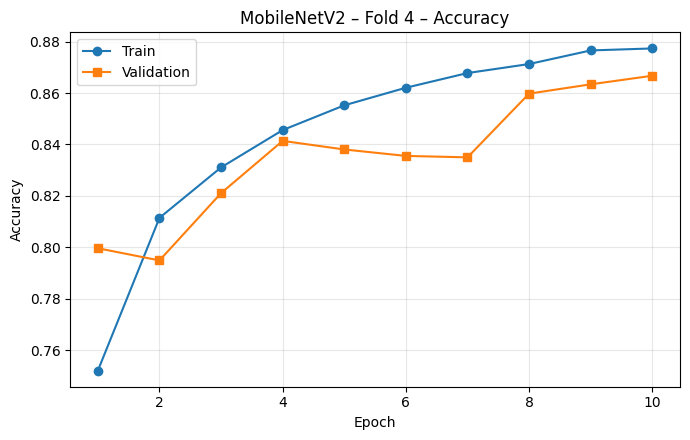

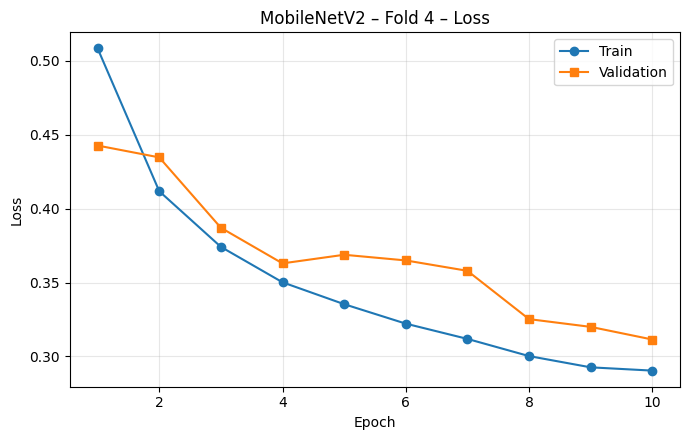

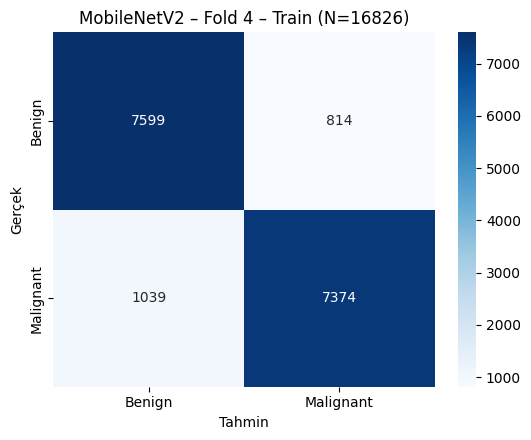

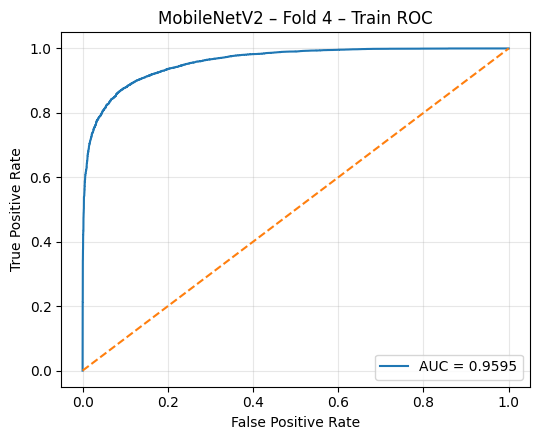

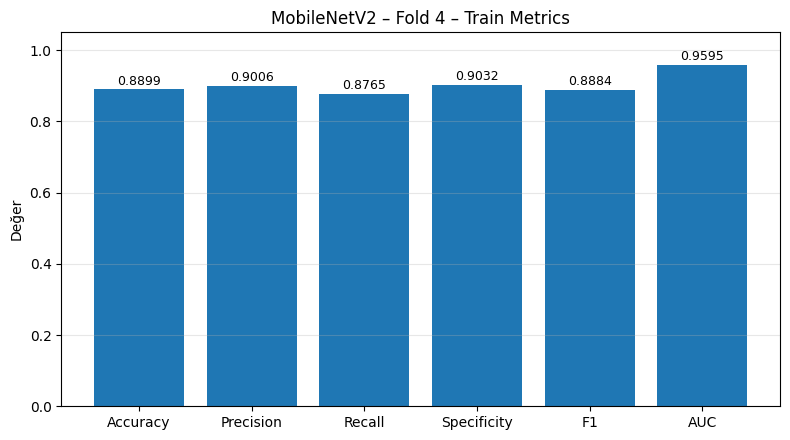

...

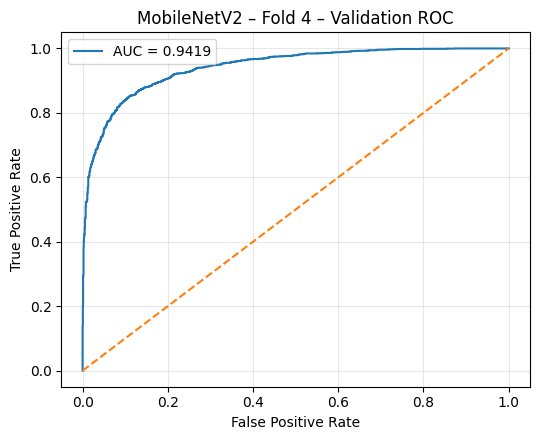

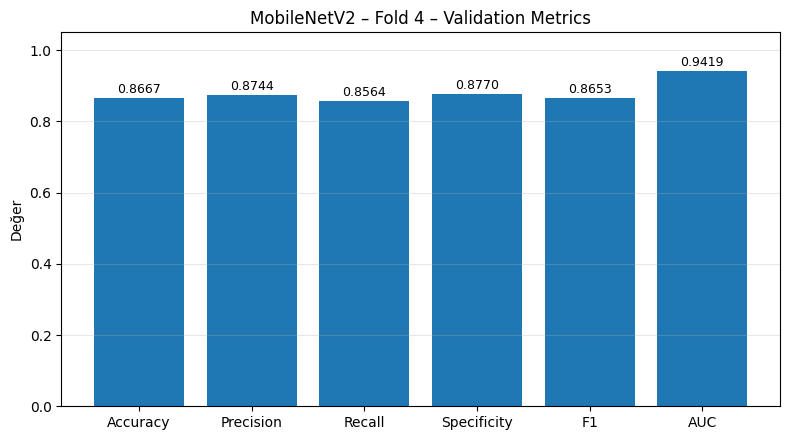

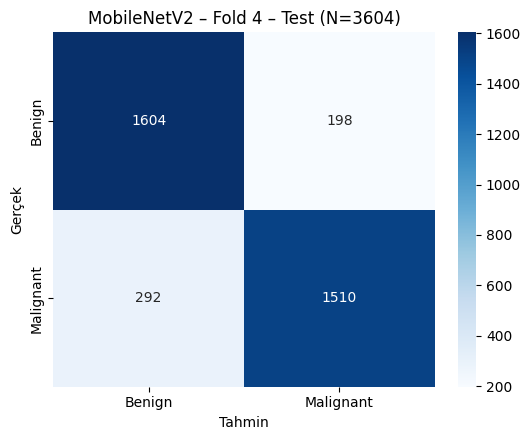

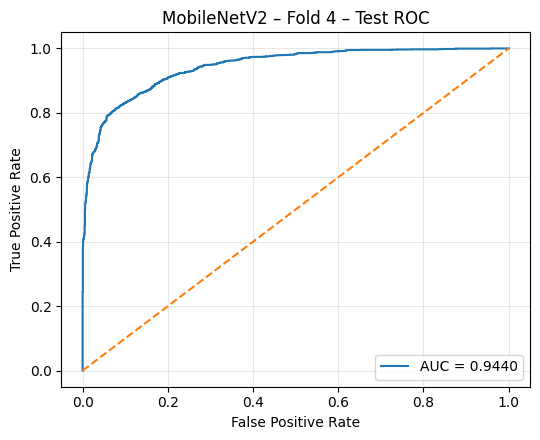

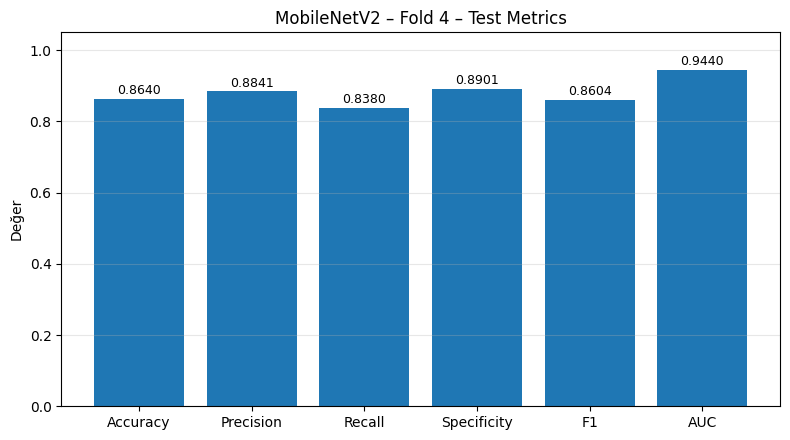

MobileNetV2 – Fold 4 sonuçları (best epoch = 10):


,N,TN,FP,FN,TP,Accuracy,Precision,Recall (Sensitivity),Specificity,F1-Score,ROC-AUC,Loss
Train,16826.0,7599.0,814.0,1039.0,7374.0,0.889873,0.900586,0.876501,0.903245,0.888380,0.959516,0.270756
Validation,3594.0,1576.0,221.0,258.0,1539.0,0.866722,0.874432,0.856427,0.877017,0.865336,0.941893,0.311453
Test,3604.0,1604.0,198.0,292.0,1510.0,0.864040,0.884075,0.837958,0.890122,0.860399,0.943967,0.306013


✓ MobileNetV2 Fold 4: best epoch 10 | Test acc 0.8640
MobileNetV2 | Fold 5 | Epoch 01/10 | Train loss 0.5071 acc 0.7495 | Val loss 0.4229 acc 0.8114
MobileNetV2 | Fold 5 | Epoch 02/10 | Train loss 0.4139 acc 0.8148 | Val loss 0.3802 acc 0.8328
MobileNetV2 | Fold 5 | Epoch 03/10 | Train loss 0.3794 acc 0.8321 | Val loss 0.3583 acc 0.8456
MobileNetV2 | Fold 5 | Epoch 04/10 | Train loss 0.3583 acc 0.8451 | Val loss 0.3390 acc 0.8520
MobileNetV2 | Fold 5 | Epoch 05/10 | Train loss 0.3400 acc 0.8556 | Val loss 0.3292 acc 0.8528
MobileNetV2 | Fold 5 | Epoch 06/10 | Train loss 0.3255 acc 0.8606 | Val loss 0.3193 acc 0.8612
MobileNetV2 | Fold 5 | Epoch 07/10 | Train loss 0.3156 acc 0.8659 | Val loss 0.3178 acc 0.8609
MobileNetV2 | Fold 5 | Epoch 08/10 | Train loss 0.3046 acc 0.8718 | Val loss 0.3020 acc 0.8703
MobileNetV2 | Fold 5 | Epoch 09/10 | Train loss 0.2976 acc 0.8734 | Val loss 0.3262 acc 0.8506
MobileNetV2 | Fold 5 | Epoch 10/10 | Train loss 0.2906 acc 0.8789 | Val loss 0.3059 acc 0.8

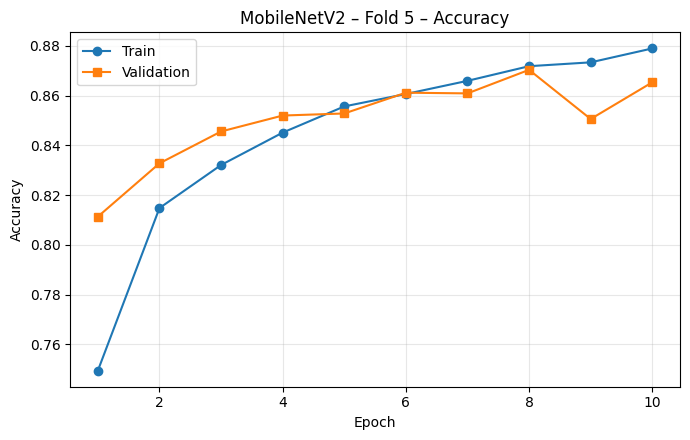

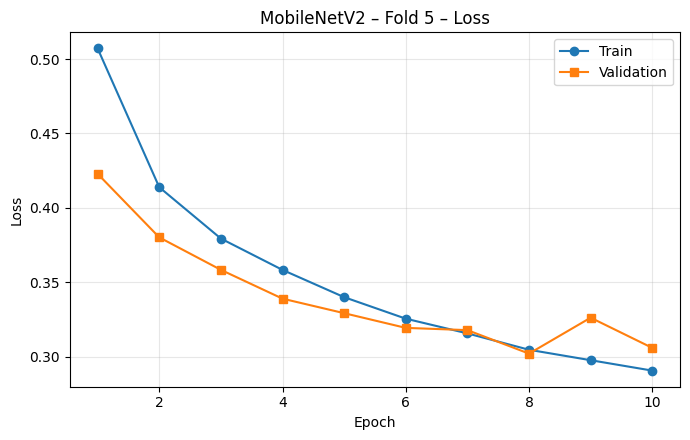

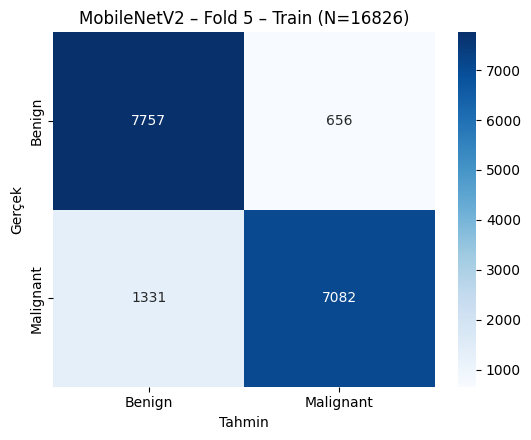

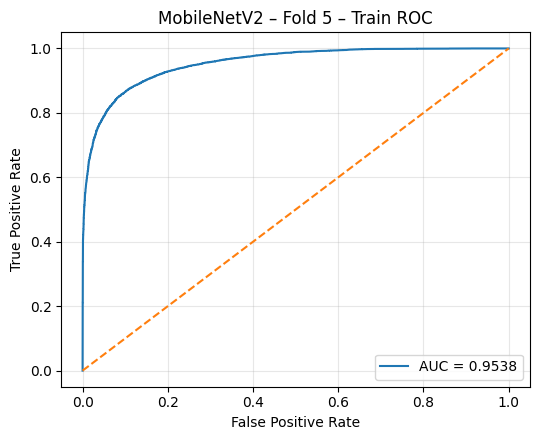

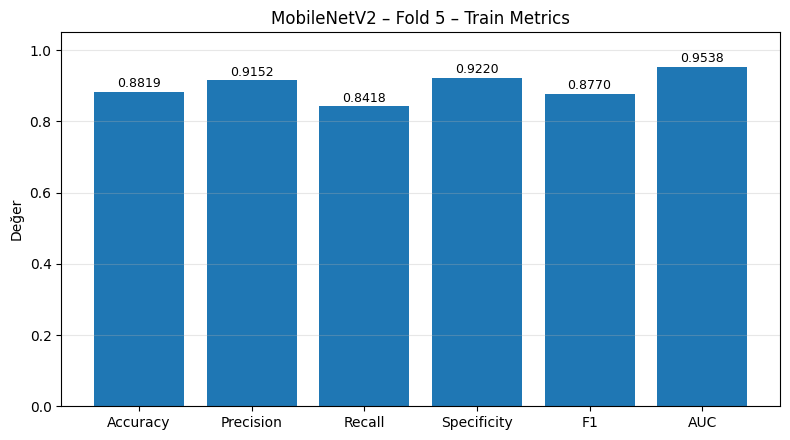

...

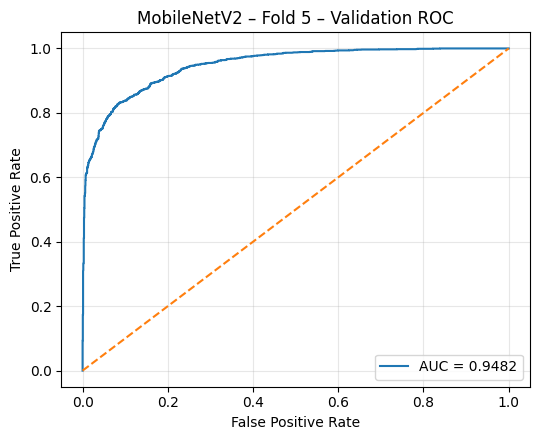

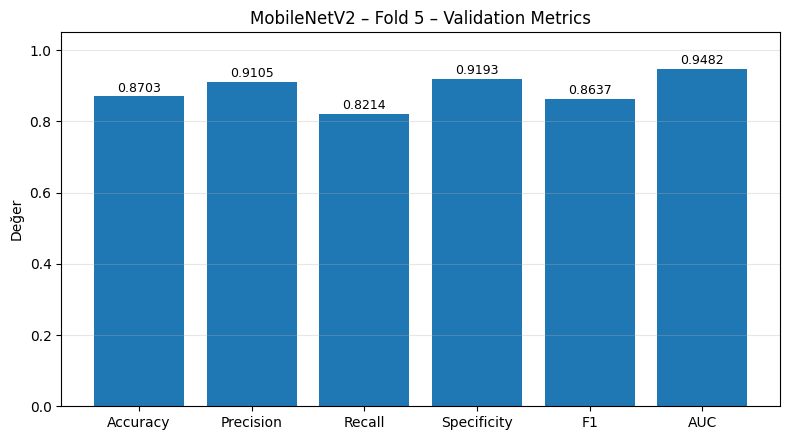

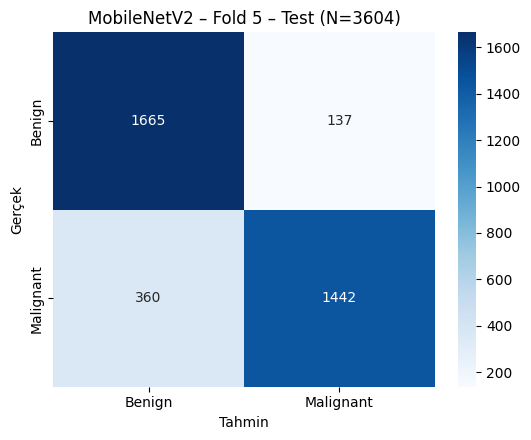

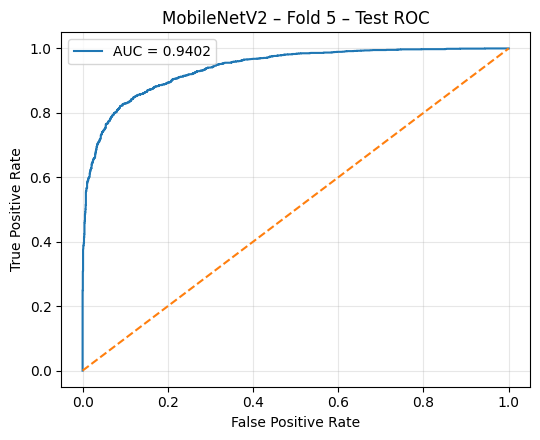

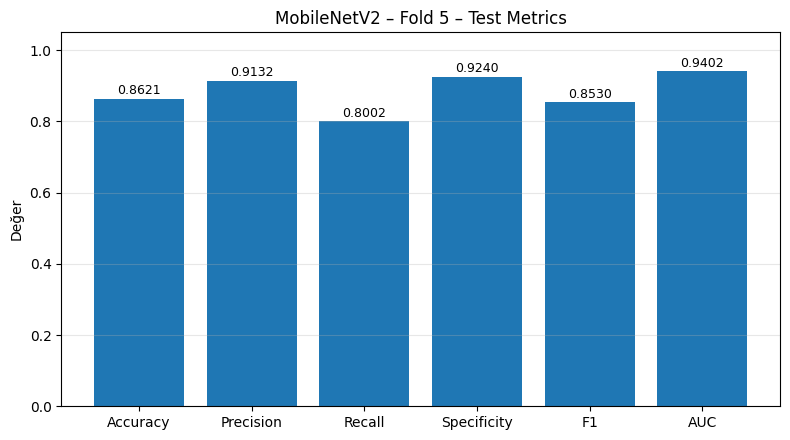

MobileNetV2 – Fold 5 sonuçları (best epoch = 8):


,N,TN,FP,FN,TP,Accuracy,Precision,Recall (Sensitivity),Specificity,F1-Score,ROC-AUC,Loss
Train,16826.0,7757.0,656.0,1331.0,7082.0,0.881909,0.915224,0.841792,0.922025,0.876974,0.953779,0.291452
Validation,3594.0,1652.0,145.0,321.0,1476.0,0.870339,0.910549,0.821369,0.919310,0.863663,0.948206,0.302038
Test,3604.0,1665.0,137.0,360.0,1442.0,0.862098,0.913236,0.800222,0.923973,0.853002,0.940170,0.322361


✓ MobileNetV2 Fold 5: best epoch 8 | Test acc 0.8621
Downloading: "https://download.pytorch.org/models/inception_v3_google-0cc3c7bd.pth" to /root/.cache/torch/hub/checkpoints/inception_v3_google-0cc3c7bd.pth


100%|██████████| 104M/104M [00:00<00:00, 235MB/s] 


InceptionV3 | Fold 1 | Epoch 01/10 | Train loss 0.5358 acc 0.7226 | Val loss 0.5002 acc 0.7449
InceptionV3 | Fold 1 | Epoch 02/10 | Train loss 0.4373 acc 0.7978 | Val loss 0.4598 acc 0.7749
InceptionV3 | Fold 1 | Epoch 03/10 | Train loss 0.3930 acc 0.8218 | Val loss 0.4742 acc 0.7657
InceptionV3 | Fold 1 | Epoch 04/10 | Train loss 0.3732 acc 0.8364 | Val loss 0.3861 acc 0.8314
InceptionV3 | Fold 1 | Epoch 05/10 | Train loss 0.3488 acc 0.8482 | Val loss 0.3652 acc 0.8353
InceptionV3 | Fold 1 | Epoch 06/10 | Train loss 0.3405 acc 0.8553 | Val loss 0.3619 acc 0.8303
InceptionV3 | Fold 1 | Epoch 07/10 | Train loss 0.3250 acc 0.8615 | Val loss 0.3581 acc 0.8417
InceptionV3 | Fold 1 | Epoch 08/10 | Train loss 0.3162 acc 0.8651 | Val loss 0.3516 acc 0.8434
InceptionV3 | Fold 1 | Epoch 09/10 | Train loss 0.3077 acc 0.8720 | Val loss 0.3451 acc 0.8506
InceptionV3 | Fold 1 | Epoch 10/10 | Train loss 0.2999 acc 0.8732 | Val loss 0.3331 acc 0.8534


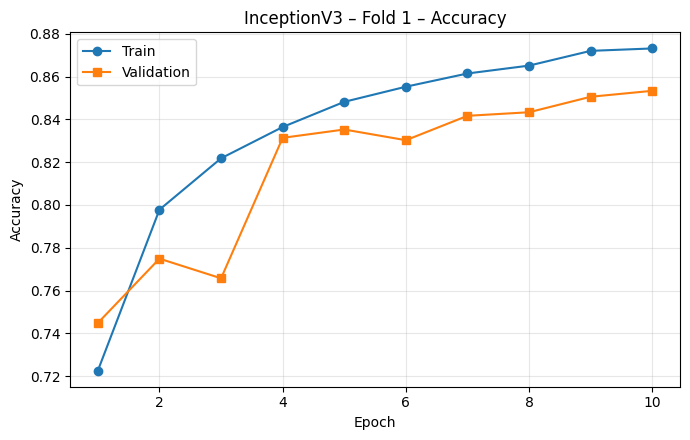

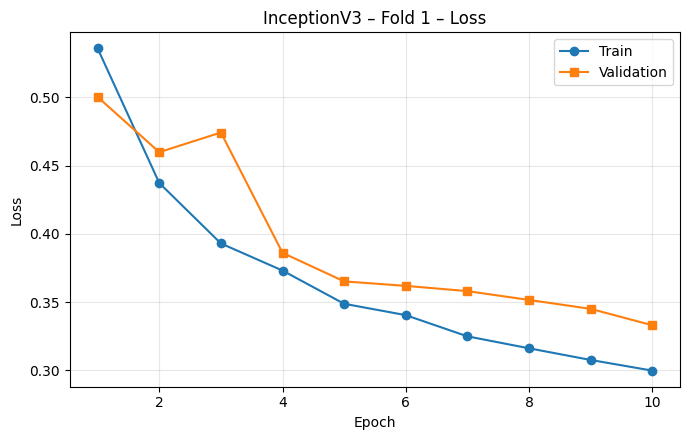

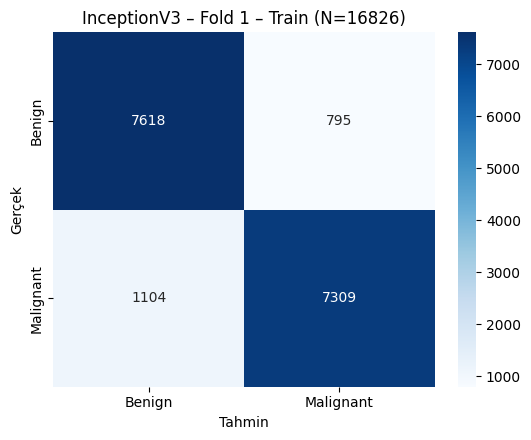

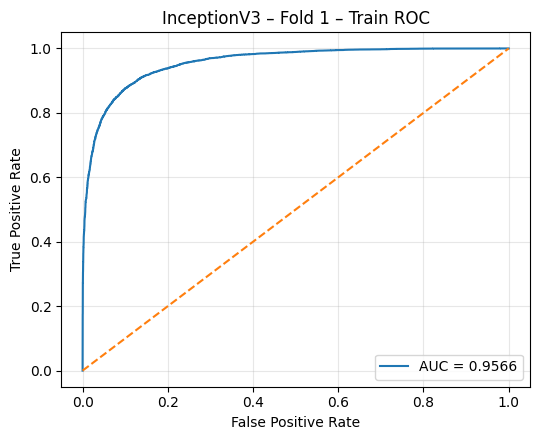

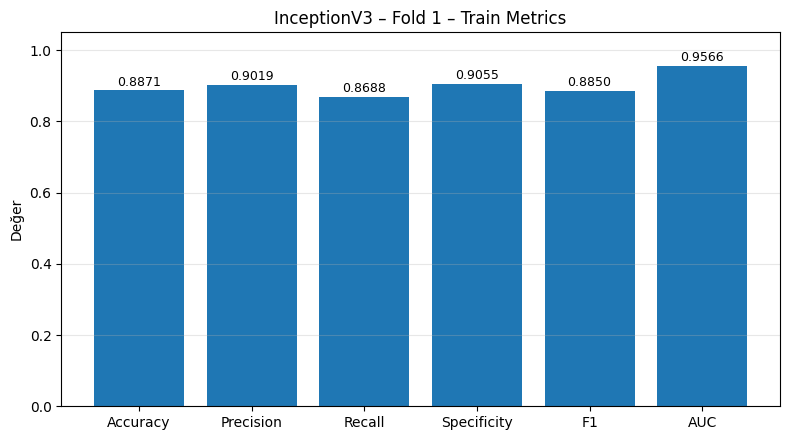

...

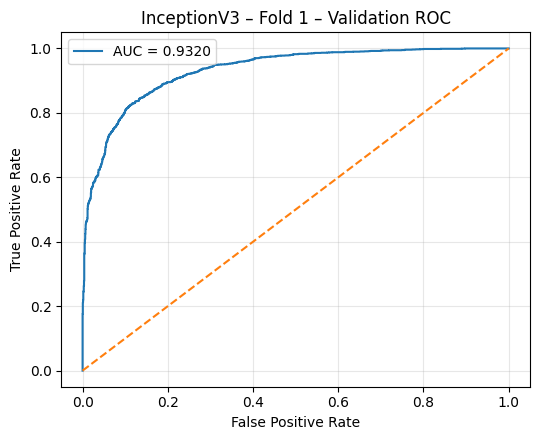

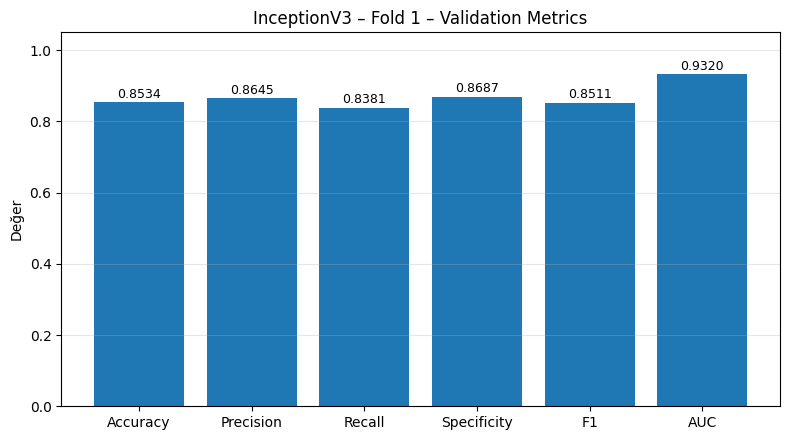

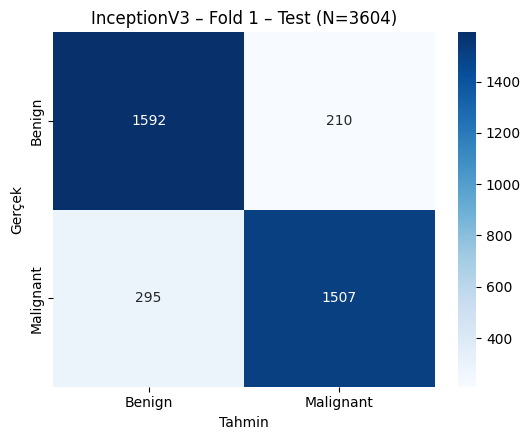

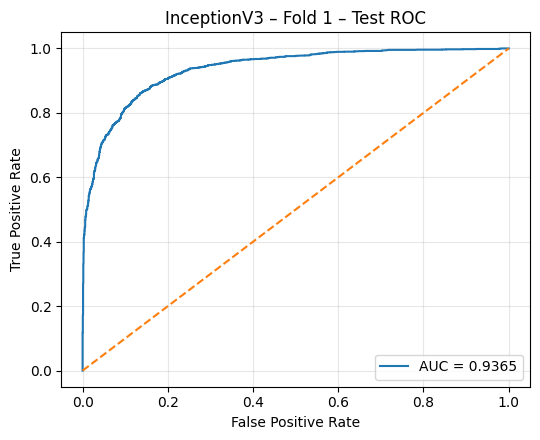

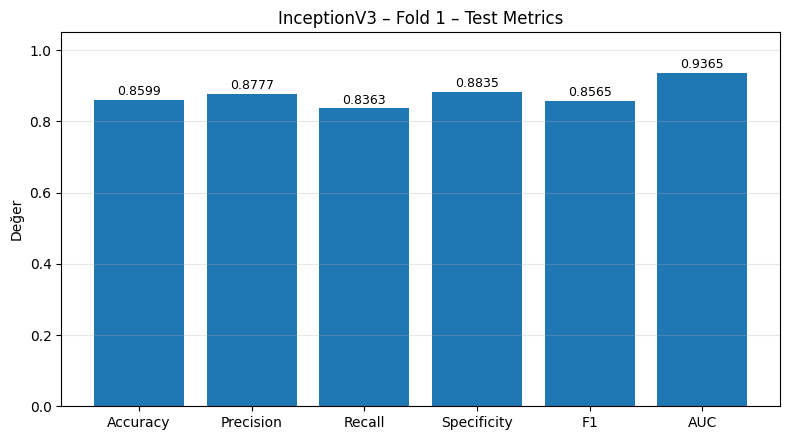

InceptionV3 – Fold 1 sonuçları (best epoch = 10):


,N,TN,FP,FN,TP,Accuracy,Precision,Recall (Sensitivity),Specificity,F1-Score,ROC-AUC,Loss
Train,16826.0,7618.0,795.0,1104.0,7309.0,0.887139,0.901900,0.868775,0.905503,0.885028,0.956593,0.277657
Validation,3594.0,1561.0,236.0,291.0,1506.0,0.853367,0.864524,0.838063,0.868670,0.851088,0.931973,0.333107
Test,3604.0,1592.0,210.0,295.0,1507.0,0.859878,0.877694,0.836293,0.883463,0.856493,0.936491,0.324987


✓ InceptionV3 Fold 1: best epoch 10 | Test acc 0.8599
InceptionV3 | Fold 2 | Epoch 01/10 | Train loss 0.5351 acc 0.7263 | Val loss 0.4675 acc 0.7819
InceptionV3 | Fold 2 | Epoch 02/10 | Train loss 0.4386 acc 0.7922 | Val loss 0.4381 acc 0.7888
InceptionV3 | Fold 2 | Epoch 03/10 | Train loss 0.3938 acc 0.8223 | Val loss 0.4214 acc 0.8063
InceptionV3 | Fold 2 | Epoch 04/10 | Train loss 0.3752 acc 0.8342 | Val loss 0.3772 acc 0.8342
InceptionV3 | Fold 2 | Epoch 05/10 | Train loss 0.3506 acc 0.8452 | Val loss 0.4132 acc 0.8080
InceptionV3 | Fold 2 | Epoch 06/10 | Train loss 0.3419 acc 0.8496 | Val loss 0.3566 acc 0.8445
InceptionV3 | Fold 2 | Epoch 07/10 | Train loss 0.3277 acc 0.8591 | Val loss 0.4140 acc 0.8027
InceptionV3 | Fold 2 | Epoch 08/10 | Train loss 0.3190 acc 0.8637 | Val loss 0.3426 acc 0.8523
InceptionV3 | Fold 2 | Epoch 09/10 | Train loss 0.3080 acc 0.8703 | Val loss 0.3685 acc 0.8361
InceptionV3 | Fold 2 | Epoch 10/10 | Train loss 0.2986 acc 0.8752 | Val loss 0.3381 acc 0.8

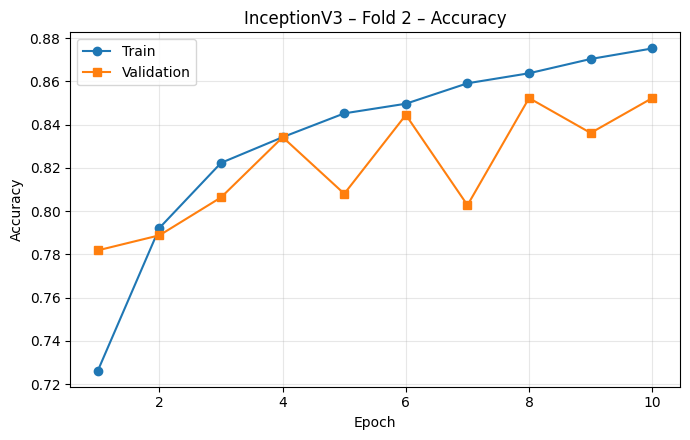

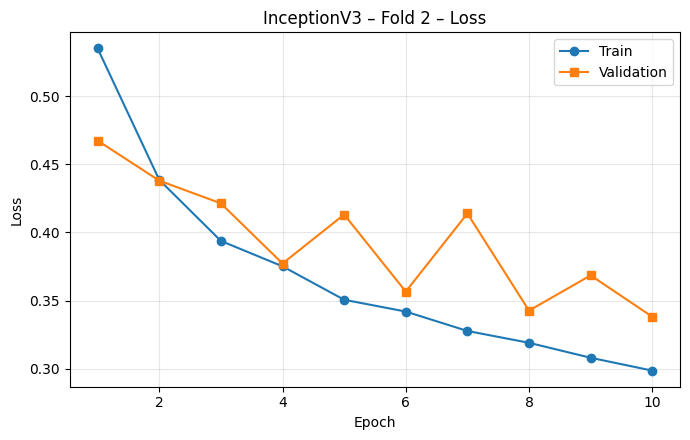

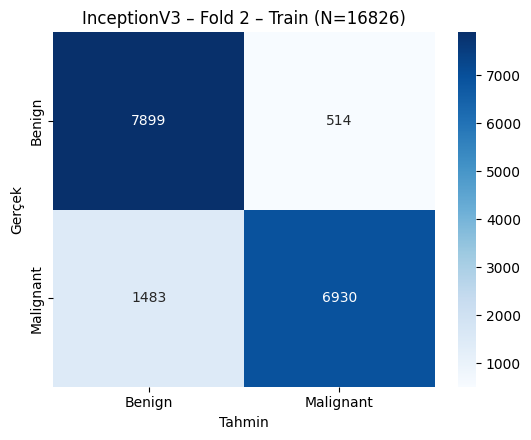

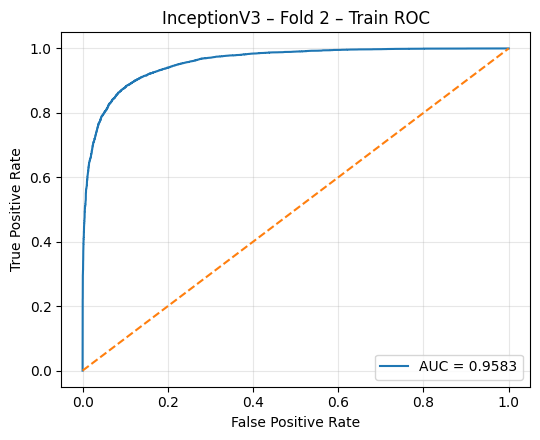

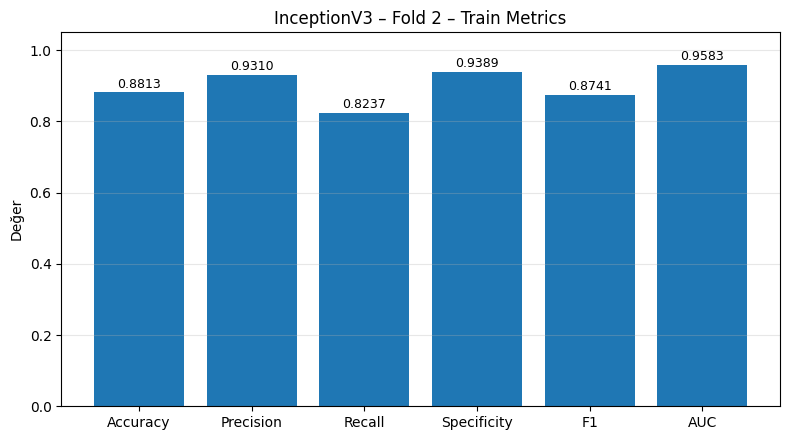

...

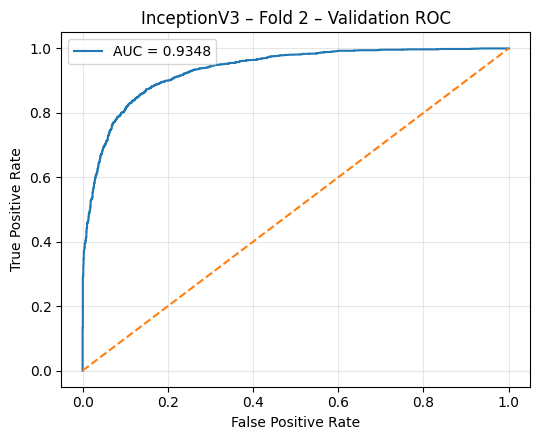

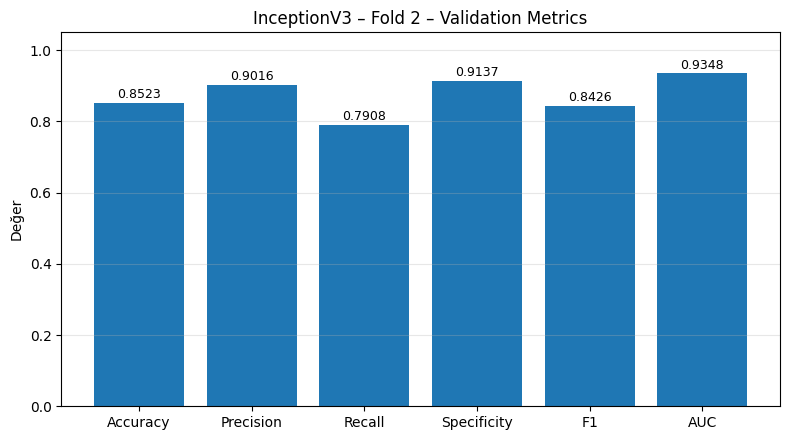

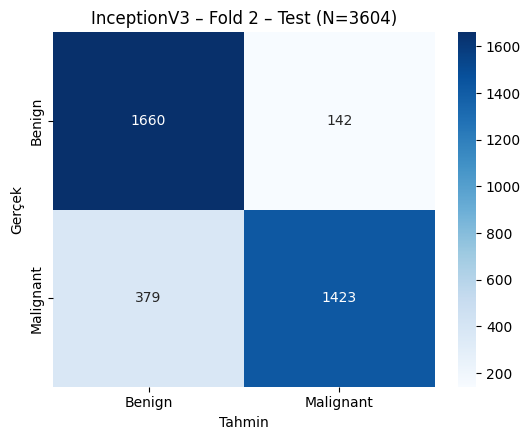

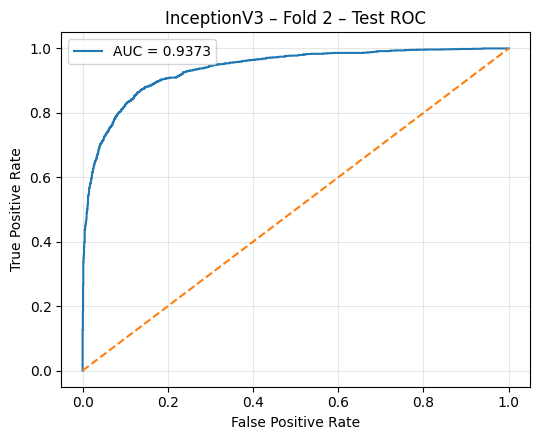

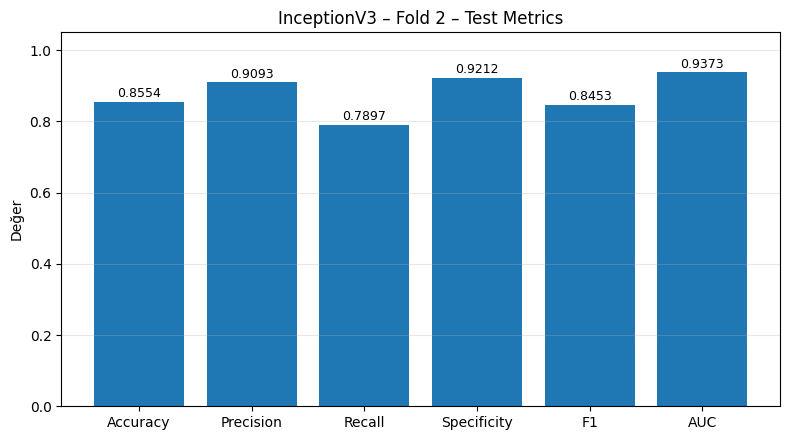

InceptionV3 – Fold 2 sonuçları (best epoch = 10):


,N,TN,FP,FN,TP,Accuracy,Precision,Recall (Sensitivity),Specificity,F1-Score,ROC-AUC,Loss
Train,16826.0,7899.0,514.0,1483.0,6930.0,0.881315,0.930951,0.823725,0.938904,0.874062,0.958267,0.284632
Validation,3594.0,1642.0,155.0,376.0,1421.0,0.852254,0.901650,0.790762,0.913745,0.842573,0.934773,0.338123
Test,3604.0,1660.0,142.0,379.0,1423.0,0.855438,0.909265,0.789678,0.921199,0.845263,0.937311,0.335036


✓ InceptionV3 Fold 2: best epoch 10 | Test acc 0.8554
InceptionV3 | Fold 3 | Epoch 01/10 | Train loss 0.5412 acc 0.7245 | Val loss 0.4571 acc 0.7863
InceptionV3 | Fold 3 | Epoch 02/10 | Train loss 0.4412 acc 0.7963 | Val loss 0.4182 acc 0.8080
InceptionV3 | Fold 3 | Epoch 03/10 | Train loss 0.3975 acc 0.8234 | Val loss 0.4004 acc 0.8211
InceptionV3 | Fold 3 | Epoch 04/10 | Train loss 0.3799 acc 0.8298 | Val loss 0.3694 acc 0.8361
InceptionV3 | Fold 3 | Epoch 05/10 | Train loss 0.3576 acc 0.8430 | Val loss 0.3665 acc 0.8389
InceptionV3 | Fold 3 | Epoch 06/10 | Train loss 0.3461 acc 0.8489 | Val loss 0.3423 acc 0.8523
InceptionV3 | Fold 3 | Epoch 07/10 | Train loss 0.3354 acc 0.8534 | Val loss 0.4008 acc 0.8086
InceptionV3 | Fold 3 | Epoch 08/10 | Train loss 0.3258 acc 0.8589 | Val loss 0.3188 acc 0.8695
InceptionV3 | Fold 3 | Epoch 09/10 | Train loss 0.3121 acc 0.8679 | Val loss 0.3083 acc 0.8756
InceptionV3 | Fold 3 | Epoch 10/10 | Train loss 0.3040 acc 0.8727 | Val loss 0.3226 acc 0.8

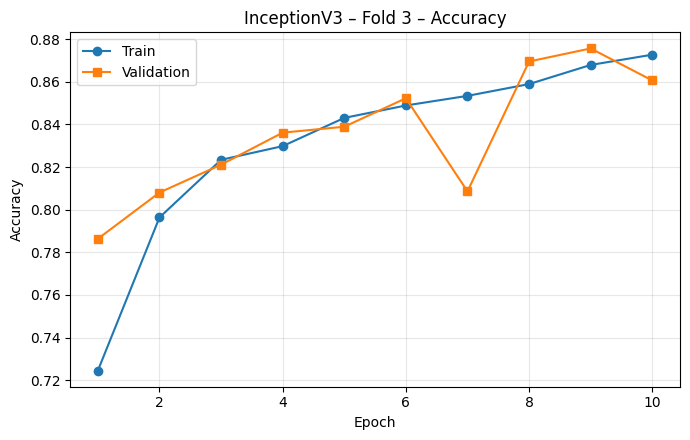

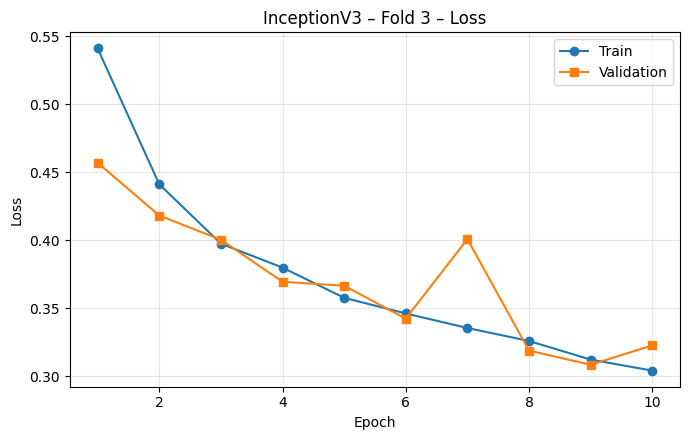

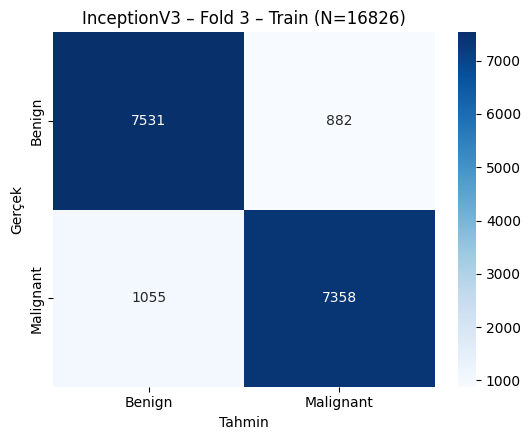

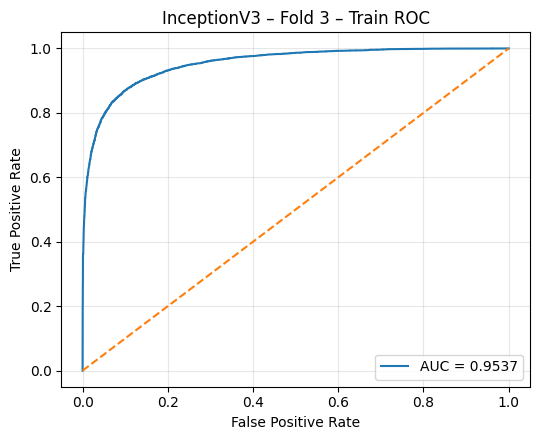

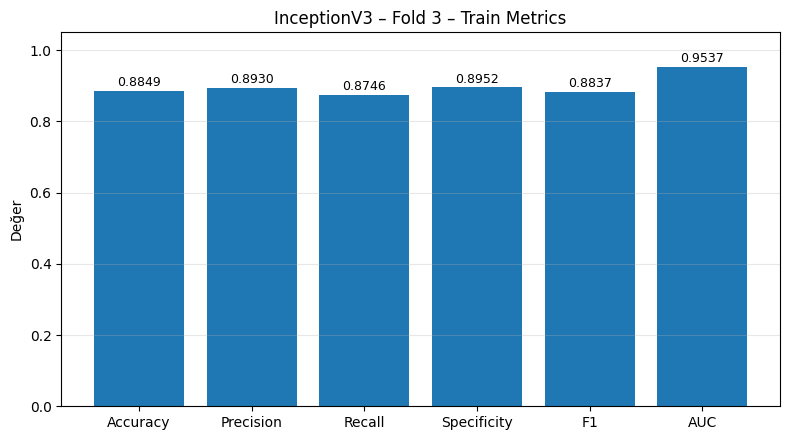

...

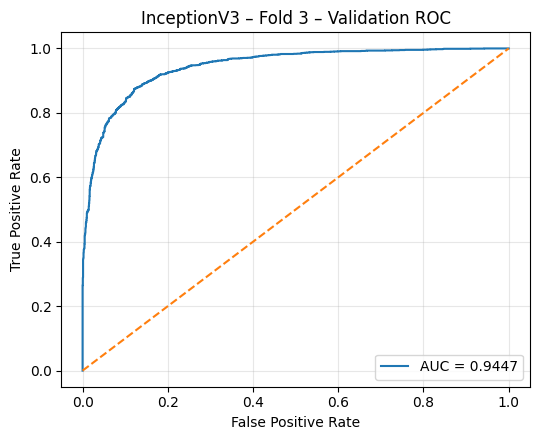

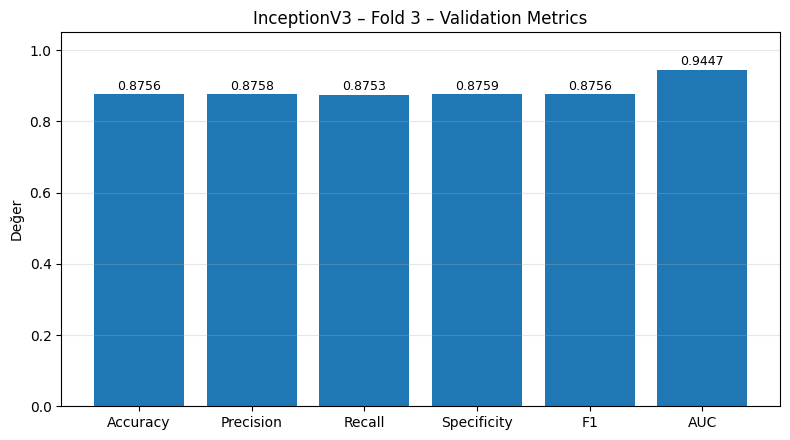

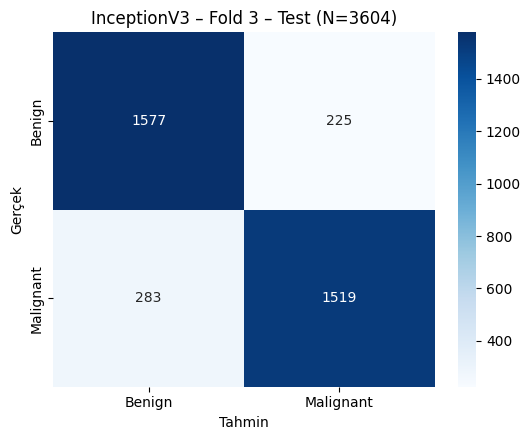

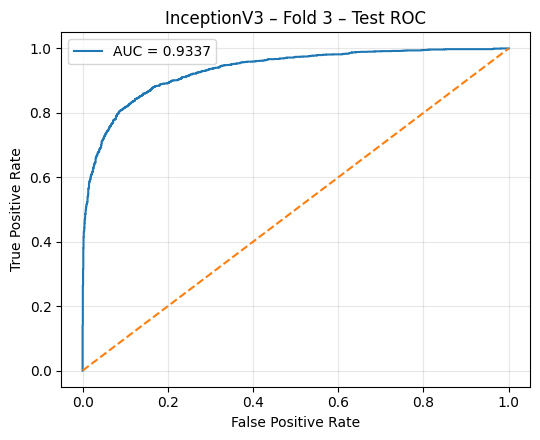

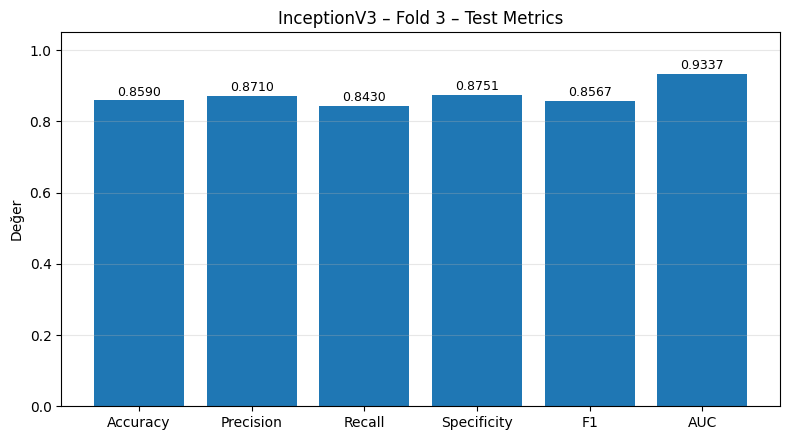

InceptionV3 – Fold 3 sonuçları (best epoch = 9):


,N,TN,FP,FN,TP,Accuracy,Precision,Recall (Sensitivity),Specificity,F1-Score,ROC-AUC,Loss
Train,16826.0,7531.0,882.0,1055.0,7358.0,0.884881,0.892961,0.874599,0.895162,0.883685,0.953721,0.287717
Validation,3594.0,1574.0,223.0,224.0,1573.0,0.875626,0.875835,0.875348,0.875904,0.875591,0.944671,0.308307
Test,3604.0,1577.0,225.0,283.0,1519.0,0.859046,0.870986,0.842952,0.875139,0.856740,0.933676,0.330082


✓ InceptionV3 Fold 3: best epoch 9 | Test acc 0.8590
InceptionV3 | Fold 4 | Epoch 01/10 | Train loss 0.5388 acc 0.7217 | Val loss 0.5081 acc 0.7437
InceptionV3 | Fold 4 | Epoch 02/10 | Train loss 0.4398 acc 0.7931 | Val loss 0.4565 acc 0.7849
InceptionV3 | Fold 4 | Epoch 03/10 | Train loss 0.3917 acc 0.8240 | Val loss 0.4027 acc 0.8139
InceptionV3 | Fold 4 | Epoch 04/10 | Train loss 0.3765 acc 0.8319 | Val loss 0.3898 acc 0.8172
InceptionV3 | Fold 4 | Epoch 05/10 | Train loss 0.3481 acc 0.8502 | Val loss 0.4144 acc 0.8044
InceptionV3 | Fold 4 | Epoch 06/10 | Train loss 0.3432 acc 0.8498 | Val loss 0.3580 acc 0.8395
InceptionV3 | Fold 4 | Epoch 07/10 | Train loss 0.3271 acc 0.8592 | Val loss 0.3634 acc 0.8417
InceptionV3 | Fold 4 | Epoch 08/10 | Train loss 0.3168 acc 0.8654 | Val loss 0.3570 acc 0.8386
InceptionV3 | Fold 4 | Epoch 09/10 | Train loss 0.3072 acc 0.8711 | Val loss 0.3502 acc 0.8475
InceptionV3 | Fold 4 | Epoch 10/10 | Train loss 0.3035 acc 0.8714 | Val loss 0.4219 acc 0.80

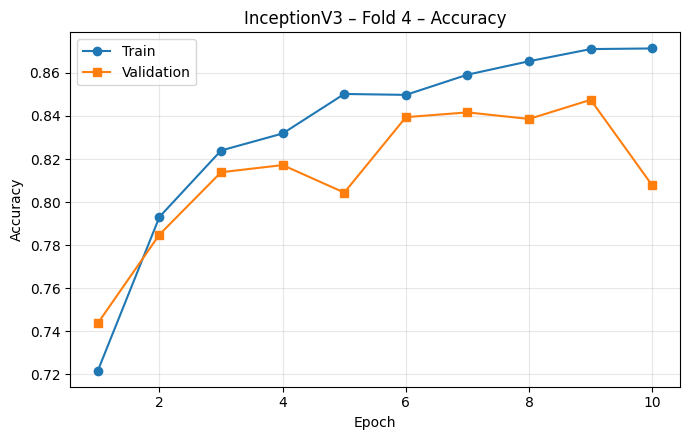

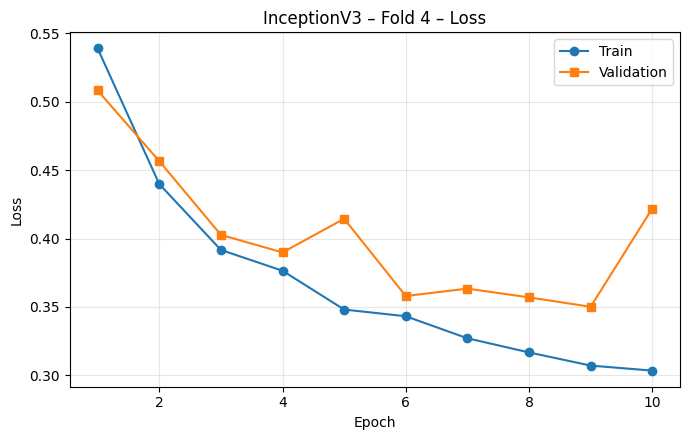

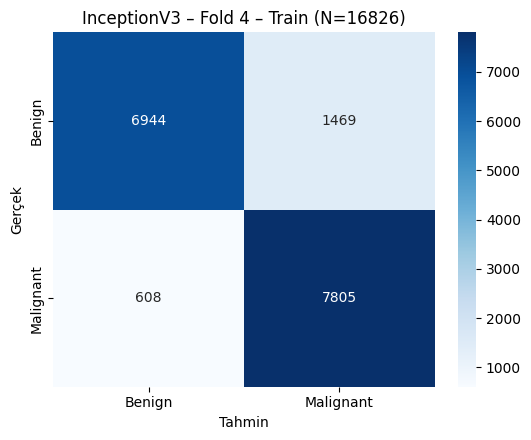

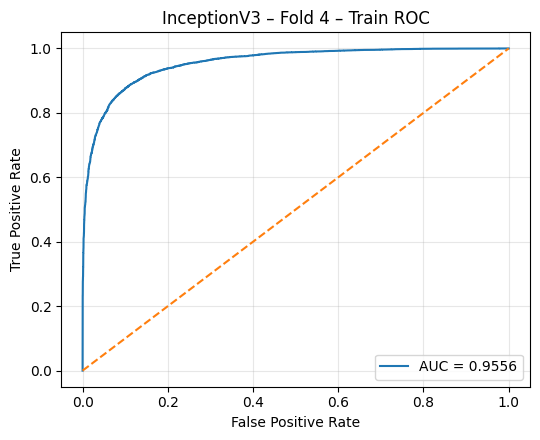

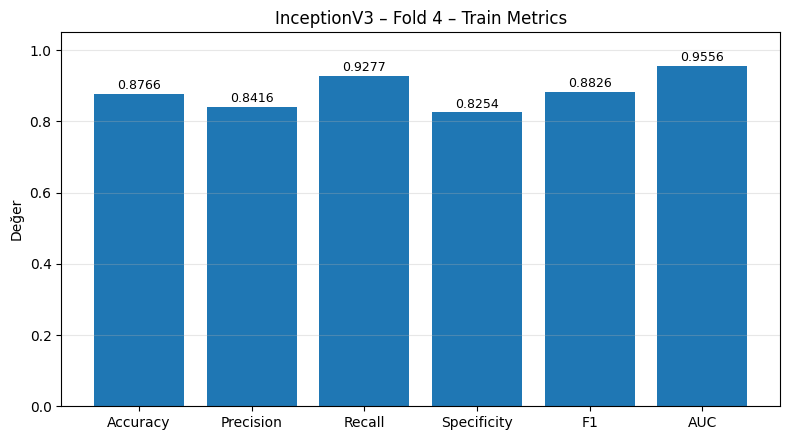

...

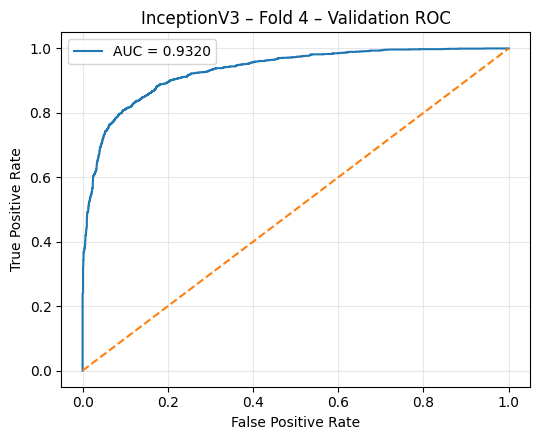

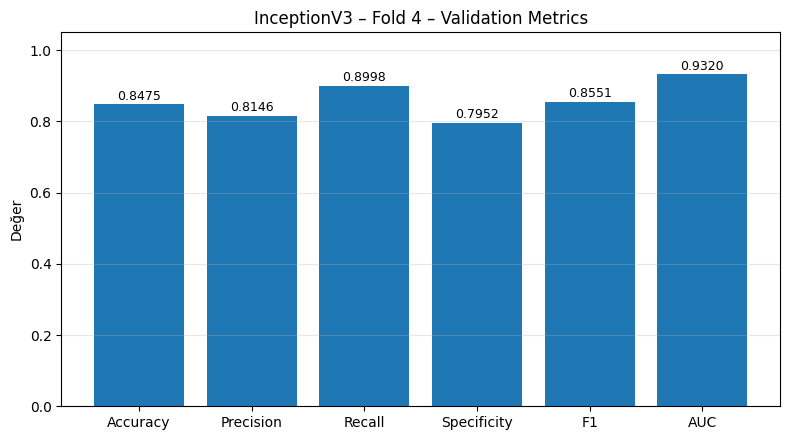

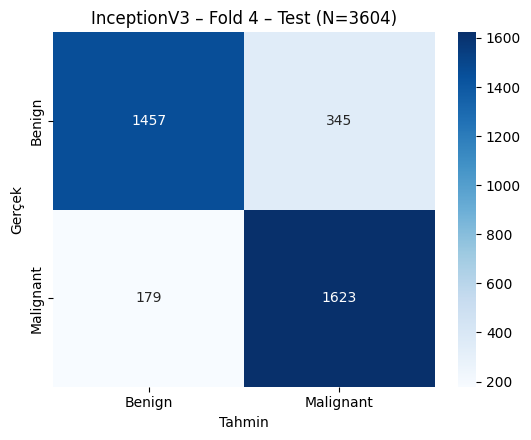

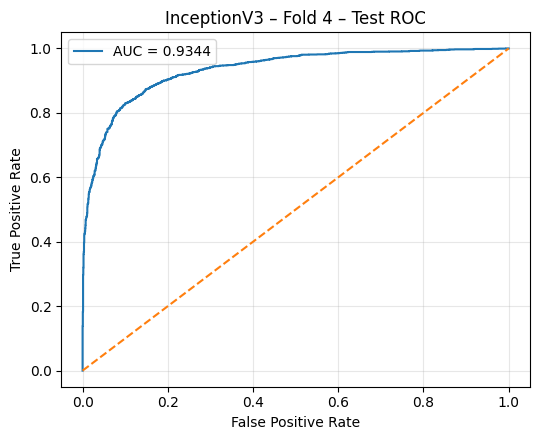

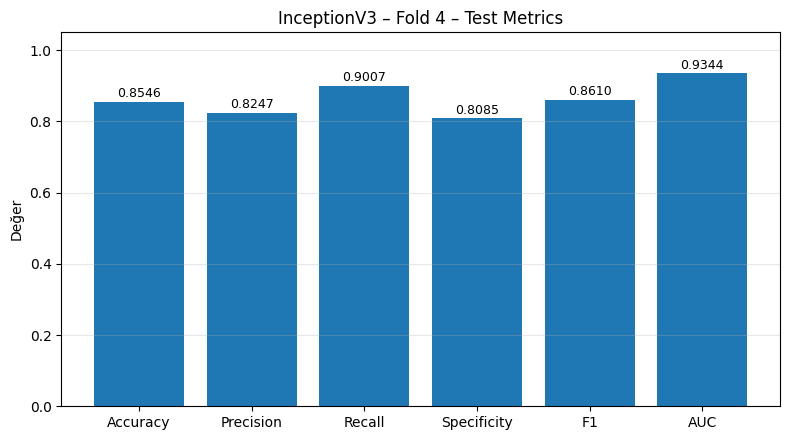

InceptionV3 – Fold 4 sonuçları (best epoch = 9):


,N,TN,FP,FN,TP,Accuracy,Precision,Recall (Sensitivity),Specificity,F1-Score,ROC-AUC,Loss
Train,16826.0,6944.0,1469.0,608.0,7805.0,0.876560,0.841600,0.927731,0.825389,0.882569,0.955636,0.298871
Validation,3594.0,1429.0,368.0,180.0,1617.0,0.847524,0.814610,0.899833,0.795214,0.855103,0.931970,0.350152
Test,3604.0,1457.0,345.0,179.0,1623.0,0.854606,0.824695,0.900666,0.808546,0.861008,0.934427,0.342078


✓ InceptionV3 Fold 4: best epoch 9 | Test acc 0.8546
InceptionV3 | Fold 5 | Epoch 01/10 | Train loss 0.5413 acc 0.7249 | Val loss 0.4721 acc 0.7710
InceptionV3 | Fold 5 | Epoch 02/10 | Train loss 0.4403 acc 0.7972 | Val loss 0.4020 acc 0.8150
InceptionV3 | Fold 5 | Epoch 03/10 | Train loss 0.3942 acc 0.8232 | Val loss 0.3790 acc 0.8347
InceptionV3 | Fold 5 | Epoch 04/10 | Train loss 0.3781 acc 0.8306 | Val loss 0.4362 acc 0.7835
InceptionV3 | Fold 5 | Epoch 05/10 | Train loss 0.3546 acc 0.8432 | Val loss 0.3603 acc 0.8408
InceptionV3 | Fold 5 | Epoch 06/10 | Train loss 0.3407 acc 0.8534 | Val loss 0.3378 acc 0.8578
InceptionV3 | Fold 5 | Epoch 07/10 | Train loss 0.3260 acc 0.8622 | Val loss 0.3545 acc 0.8447
InceptionV3 | Fold 5 | Epoch 08/10 | Train loss 0.3163 acc 0.8653 | Val loss 0.3273 acc 0.8595
InceptionV3 | Fold 5 | Epoch 09/10 | Train loss 0.3145 acc 0.8681 | Val loss 0.3314 acc 0.8548
InceptionV3 | Fold 5 | Epoch 10/10 | Train loss 0.3043 acc 0.8727 | Val loss 0.3202 acc 0.86

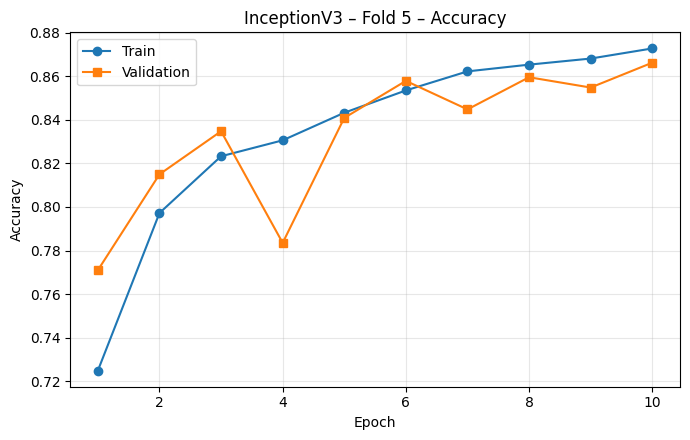

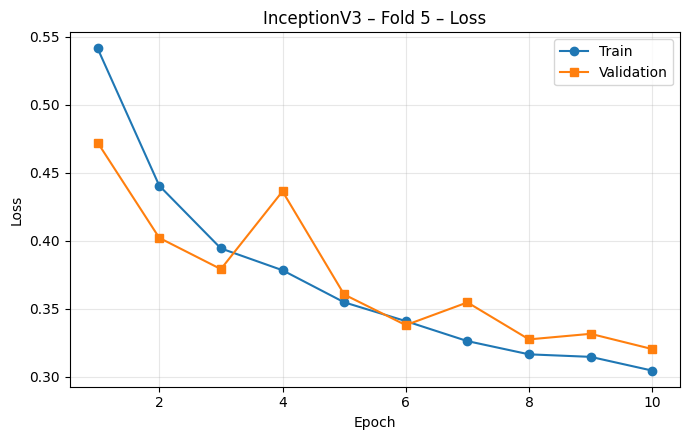

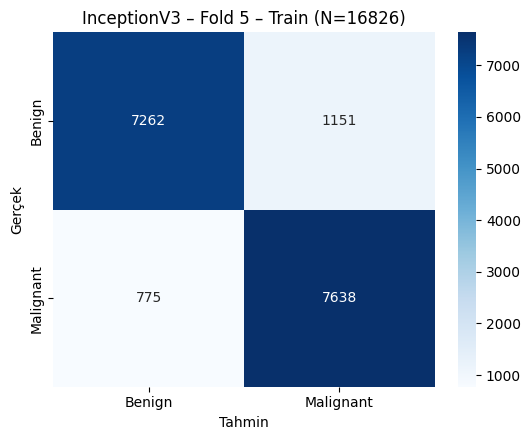

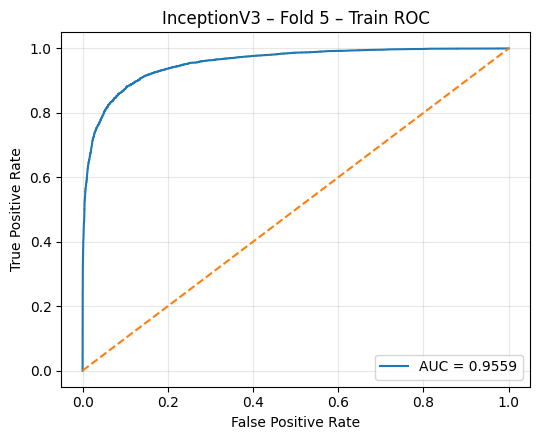

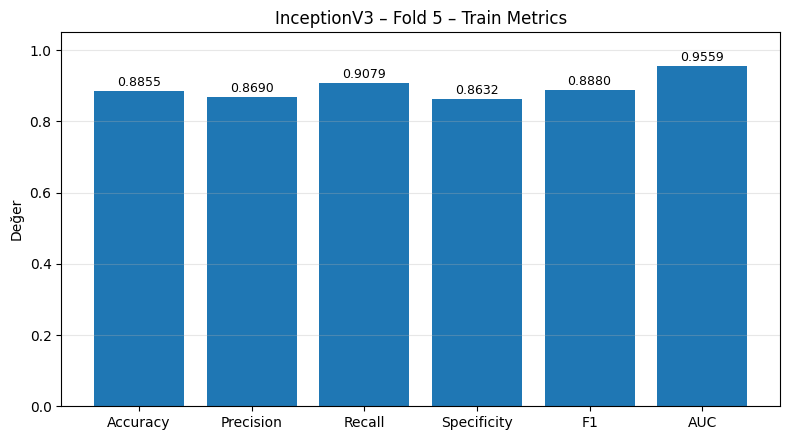

...

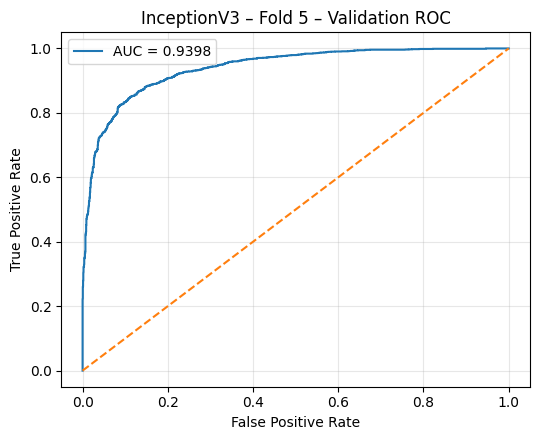

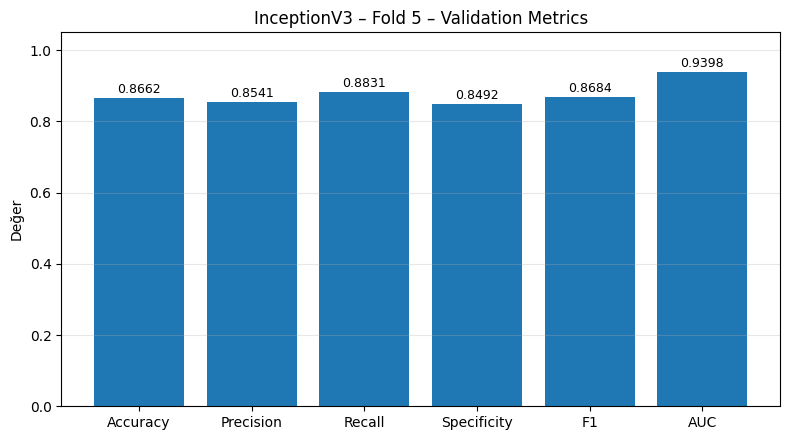

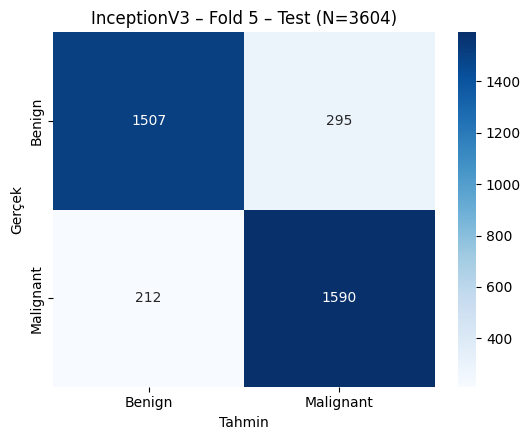

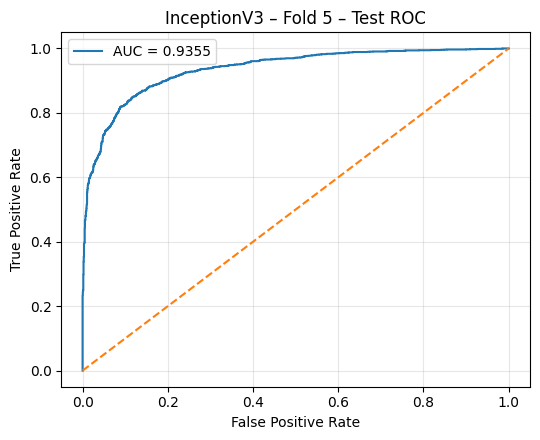

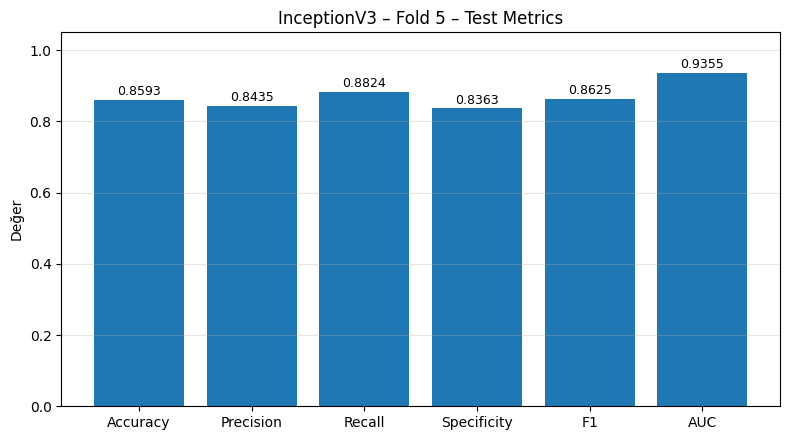

InceptionV3 – Fold 5 sonuçları (best epoch = 10):


,N,TN,FP,FN,TP,Accuracy,Precision,Recall (Sensitivity),Specificity,F1-Score,ROC-AUC,Loss
Train,16826.0,7262.0,1151.0,775.0,7638.0,0.885534,0.869041,0.907881,0.863188,0.888036,0.955899,0.285708
Validation,3594.0,1526.0,271.0,210.0,1587.0,0.866166,0.854144,0.883139,0.849193,0.868399,0.939834,0.320173
Test,3604.0,1507.0,295.0,212.0,1590.0,0.859323,0.843501,0.882353,0.836293,0.862490,0.935500,0.329657


✓ InceptionV3 Fold 5: best epoch 10 | Test acc 0.8593


,Group,Model,Split,Accuracy,Precision,Recall (Sensitivity),Specificity,F1-Score,ROC-AUC
2,baseline_cnn,ResNet34,Test,81.64 ± 0.21,83.16 ± 2.30,79.54 ± 3.35,83.74 ± 3.38,81.23 ± 0.66,89.69 ± 0.06
5,baseline_cnn,DenseNet121,Test,82.41 ± 0.14,84.13 ± 2.26,80.06 ± 3.29,84.76 ± 3.10,81.97 ± 0.71,90.87 ± 0.07
8,baseline_cnn,EfficientNet-B0,Test,88.70 ± 0.12,88.89 ± 1.16,88.48 ± 1.37,88.91 ± 1.47,88.67 ± 0.15,95.80 ± 0.21
11,baseline_cnn,MobileNetV2,Test,86.43 ± 0.25,88.03 ± 2.23,84.46 ± 2.96,88.40 ± 2.79,86.15 ± 0.55,94.28 ± 0.18
14,baseline_cnn,InceptionV3,Test,85.77 ± 0.24,86.52 ± 3.26,85.04 ± 4.33,86.49 ± 4.36,85.64 ± 0.68,93.55 ± 0.15


In [4]:
# ======================= 4. ÇALIŞTIR =======================
KIND, FAM = GROUP.split("_")
models_to_run = MODELS or (CNN_MODELS if FAM == "cnn" else VIT_MODELS)
assert all(FAMILY[m] == FAM for m in models_to_run), "Seçilen modeller gruba uymuyor"
if RERUN:   # etiket başına bir kez: MODELS=None ise gruptaki TÜM modeller, değilse sadece MODELS'tekiler
    marker = OUTPUT_ROOT / CV_MODE / GROUP / f"rerun_{RERUN}.done"
    if marker.exists():
        print(f"RERUN '{RERUN}' daha önce uygulanmış → silme YAPILMADI, kaldığı fold'dan devam ediliyor.")
    else:
        for m in models_to_run:
            d = OUTPUT_ROOT / CV_MODE / GROUP / m
            if d.exists():
                arc = OUTPUT_ROOT / CV_MODE / "_arsiv" / f"{GROUP}__{RERUN}" / m   # eski sonuçlar silinmez, arşive taşınır
                arc.parent.mkdir(parents=True, exist_ok=True); shutil.move(str(d), str(arc))
                print(f"Eski sonuçlar arşive taşındı ({arc}); yeniden eğitilecek: {m}")
        marker.parent.mkdir(parents=True, exist_ok=True)
        marker.write_text(f"{time.strftime('%Y-%m-%d %H:%M')} | silinen modeller: {', '.join(models_to_run)}\n")

(OUTPUT_ROOT / CV_MODE / GROUP).mkdir(parents=True, exist_ok=True)
(OUTPUT_ROOT / CV_MODE / GROUP / "config.json").write_text(json.dumps({
    "GROUP": GROUP, "COMMON": COMMON, "RECIPE": RECIPES[KIND], "FT_SCOPE": FT_SCOPE[(KIND, FAM)],
    "AUGMENT": AUGMENT if RECIPES[KIND]["augment"] else None, "CV_MODE": CV_MODE, "N_FOLDS": N_FOLDS, "FOLD_SEED": FOLD_SEED, "TRAIN_SEED": TRAIN_SEED,
    "fold_counts": fold_table.to_dict("records"), "VIT_LAST_BLOCKS": VIT_LAST_BLOCKS,
    "torch": torch.__version__, "gpu": torch.cuda.get_device_name(0) if device.type == "cuda" else "cpu",
    "kaggle_split_counts": {s: len(d) for s, d in DS.items()}}, indent=2, default=str))

results = []
for name in models_to_run:
    for fold in range(1, N_FOLDS + 1):
        results.append(run_one(name, fold, KIND))

per_run, summary, article = results_to_frames(results)
with pd.ExcelWriter(OUTPUT_ROOT / CV_MODE / GROUP / f"{GROUP}_results.xlsx") as xw:
    per_run.to_excel(xw, sheet_name="Fold bazlı", index=False)
    summary.to_excel(xw, sheet_name="Ortalama-Std", index=False)
    article.to_excel(xw, sheet_name="Makale tablosu", index=False)
display(article[article.Split == "Test"])
